In [1]:
# Import libraries
import os
import requests
import pandas as pd
from PIL import Image
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.metrics.pairwise import cosine_similarity
import torchvision.models as models
import torchvision.transforms as transforms
import torch
import json
from io import BytesIO
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder, normalize
from sklearn.cluster import DBSCAN
import json
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from IPython.display import display
import matplotlib.pyplot as plt

In [2]:
!pip install hdbscan

In [3]:
# Read data
df = pd.read_json('sneakers_sample_19062025.txt', lines=False)

print(df.head())

                                                data  \
0  {'EAN': [], 'size': '44', 'brand': 'ASICS', 'c...   
1  {'EAN': [], 'size': '44', 'brand': 'VANS', 'co...   
2  {'EAN': [], 'size': '44.5', 'brand': 'ADIDAS',...   
3  {'EAN': [], 'size': '42', 'brand': 'NIKE', 'co...   
4  {'EAN': [], 'size': '11/EU 46', 'brand': 'PUMA...   

                      mirakl_product_id             creation_date  \
0  d96975c5-0bea-41f6-a4a8-fdac53f374f3  2024-01-09T12:09:20.568Z   
1  6f302b78-9a86-484e-894f-bb39220931a3  2023-11-09T13:08:33.276Z   
2  70006973-aa9f-4176-9f38-0ba2c5a1b06f  2025-03-29T08:43:47.421Z   
3  6b010b1d-7475-44dc-ad56-502769d2e742  2024-01-04T12:29:59.343Z   
4  cf04d217-bfd6-4743-ae4b-bc98712959ca  2025-02-13T14:31:57.524Z   

                update_date                           product_sku  \
0  2024-11-06T13:03:01.469Z  d96975c5-0bea-41f6-a4a8-fdac53f374f3   
1  2025-02-12T12:21:44.083Z  6f302b78-9a86-484e-894f-bb39220931a3   
2  2025-03-30T21:07:23.464Z  70006973-aa9

In [4]:
df.head()

,data,mirakl_product_id,creation_date,update_date,product_sku,validation,synchronization,catalogs,product_urls,sources,selling_authorization,data_origin
0,"{'EAN': [], 'size': '44', 'brand': 'ASICS', 'c...",d96975c5-0bea-41f6-a4a8-fdac53f374f3,2024-01-09T12:09:20.568Z,2024-11-06T13:03:01.469Z,d96975c5-0bea-41f6-a4a8-fdac53f374f3,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2077', 'provider_sku': '10...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
1,"{'EAN': [], 'size': '44', 'brand': 'VANS', 'co...",6f302b78-9a86-484e-894f-bb39220931a3,2023-11-09T13:08:33.276Z,2025-02-12T12:21:44.083Z,6f302b78-9a86-484e-894f-bb39220931a3,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2002', 'provider_sku': 'VN...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
2,"{'EAN': [], 'size': '44.5', 'brand': 'ADIDAS',...",70006973-aa9f-4176-9f38-0ba2c5a1b06f,2025-03-29T08:43:47.421Z,2025-03-30T21:07:23.464Z,70006973-aa9f-4176-9f38-0ba2c5a1b06f,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2167', 'provider_sku': 'IH...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
3,"{'EAN': [], 'size': '42', 'brand': 'NIKE', 'co...",6b010b1d-7475-44dc-ad56-502769d2e742,2024-01-04T12:29:59.343Z,2024-11-06T13:00:53.470Z,6b010b1d-7475-44dc-ad56-502769d2e742,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2077', 'provider_sku': 'CT...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
4,"{'EAN': [], 'size': '11/EU 46', 'brand': 'PUMA...",cf04d217-bfd6-4743-ae4b-bc98712959ca,2025-02-13T14:31:57.524Z,2025-03-01T00:03:24.205Z,cf04d217-bfd6-4743-ae4b-bc98712959ca,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '3390', 'provider_sku': '46...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."


### Create separate dataframes

In [6]:
# Load the JSON file
with open('sneakers_sample_19062025.txt', 'r', encoding='utf-8') as f:    # added encoding = utf8 otherwise: decoding error
    raw_data = json.load(f)

# Create separate dataframes
meta_rows = []
data_rows = []
sources_rows = []

# Exclude some fields that are not necessary for our tasks
exclude_fields = {
    'creation_date', 'update_date',
    'validation', 'synchronization',
    'catalogs', 'selling_authorization', "product_urls"
}

for entry in raw_data:
    # Top-level fields
    meta = {
        key: entry[key] for key in entry
        if key not in exclude_fields and key not in ['data', 'sources']
    }
    meta_rows.append(meta)
    
    # Extract nested fields (if they exist)
    if 'data' in entry:
        data_rows.append(entry['data'])
    if 'sources' in entry and isinstance(entry['sources'], list):
        for source in entry['sources']:
            # Optionally, attach product ID to track back
            source['mirakl_product_id'] = entry.get('mirakl_product_id')
            sources_rows.append(source)

# Convert all parts to DataFrames
df_meta = pd.DataFrame(meta_rows)
df_data = pd.json_normalize(data_rows)
df_sources = pd.DataFrame(sources_rows)

# Preview
print("Meta columns:", df_meta.columns.tolist())
print("Data columns:", df_data.columns.tolist())
print("Sources sample:", df_sources.head())

Meta columns: ['mirakl_product_id', 'product_sku', 'data_origin']
Data columns: ['EAN', 'size', 'brand', 'color', 'category', 'returnable', 'name [el_CY]', 'name [en_GB]', 'updateOnDelta', 'refinementColor', 'variantGroupCode', 'jiniusSkuMatchCode', 'shortDescription [el_CY]', 'shortDescription [en_GB]', 'mainImage.source', 'mainImage.original_url', 'secondary_image_1.source', 'secondary_image_1.original_url', 'secondary_image_2.source', 'secondary_image_2.original_url', 'secondary_image_3.source', 'secondary_image_3.original_url', 'longDescription [en_GB]', 'longDescription [el_CY]', 'shoeType', 'shoeShape', 'fashionMaterial', 'shoeWidth', 'heelHeight', 'name', 'heelType', 'longDescription', 'shortDescription']
Sources sample:   provider_code                               provider_sku  \
0          2077        1071A091-101--EUM-18--WHITE / BLACK   
1          2002                   VN0A3MTJT2J1--417--BLACK   
2          2167                                IH6003-44.5   
3          207

In [7]:
df_data

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,longDescription [el_CY],shoeType,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription
0,[],44,ASICS,White / Black,FaMeShSneakers,true,Gel-rocket 11 mens volleyball/indoor shoes,Gel-rocket 11 mens volleyball/indoor shoes,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,[],44,VANS,Black,FaMeShSneakers,true,Mens filmore suede,Mens filmore suede,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,[],44.5,ADIDAS,NaN,FaMeShSneakers,true,Ih6003,Adidas response,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,[],42,NIKE,White / Black / Volt,FaMeShSneakers,true,React vision worldwide mens,React vision worldwide mens,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,[],11/EU 46,PUMA,Black/white,FaMeShSneakers,true,Puma men's x-ray 3 sd,Puma men's x-ray 3 sd,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5818,[],37,BUFFALO,White / Silver / Black,FaWoShSneakers,true,Triple hollow sneakers,Triple hollow sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5819,[],39,ADIDAS ORIGINALS,White,FaWoShSneakers,true,Adidas sambae w,Adidas sambae w,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5820,[],41,GUESS,White,FaWoShSneakers,true,Elbina sneakers,Elbina sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5821,[],36.5,NEW BALANCE,Cloud White / Burgundy,FaWoShSneakers,true,327 sportstyle sneakers,327 sportstyle sneakers,None,miscellaneous,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df_meta

,mirakl_product_id,product_sku,data_origin
0,d96975c5-0bea-41f6-a4a8-fdac53f374f3,d96975c5-0bea-41f6-a4a8-fdac53f374f3,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
1,6f302b78-9a86-484e-894f-bb39220931a3,6f302b78-9a86-484e-894f-bb39220931a3,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
2,70006973-aa9f-4176-9f38-0ba2c5a1b06f,70006973-aa9f-4176-9f38-0ba2c5a1b06f,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
3,6b010b1d-7475-44dc-ad56-502769d2e742,6b010b1d-7475-44dc-ad56-502769d2e742,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
4,cf04d217-bfd6-4743-ae4b-bc98712959ca,cf04d217-bfd6-4743-ae4b-bc98712959ca,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
...,...,...,...
5818,acdb8093-c93c-49d7-af05-f04cae009f99,acdb8093-c93c-49d7-af05-f04cae009f99,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
5819,e733c608-da84-49f1-a3ae-52a025b1cb3d,e733c608-da84-49f1-a3ae-52a025b1cb3d,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
5820,6d8cf85e-93bd-47ea-8a59-3e43fe4ef732,6d8cf85e-93bd-47ea-8a59-3e43fe4ef732,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."
5821,e2d00db3-27b2-4996-89e2-5c1579af5d39,e2d00db3-27b2-4996-89e2-5c1579af5d39,"{'name [en_GB]': {'origin': 'PROVIDER', 'provi..."


We observe that data_origin column is nested.

In [10]:
# Flatten 'data_origin' column
data_origin_df = pd.json_normalize(df_meta['data_origin'])

# Add prefixes so we know where they came from
data_origin_df = data_origin_df.add_prefix('origin_')

# Drop original nested columns from df_meta
df_meta = df_meta.drop(columns=['data_origin'])

# Merge the flattened parts back
df_meta = pd.concat([df_meta, data_origin_df], axis=1)

In [11]:
df_meta

,mirakl_product_id,product_sku,origin_name [en_GB].origin,origin_name [en_GB].provider_code,origin_name [el_CY].origin,origin_name [el_CY].provider_code,origin_color.origin,origin_color.provider_code,origin_shortDescription [el_CY].origin,origin_shortDescription [el_CY].provider_code,...,origin_heelHeight.origin,origin_heelHeight.provider_code,origin_longDescription.origin,origin_longDescription.provider_code,origin_shortDescription.origin,origin_shortDescription.provider_code,origin_name.origin,origin_name.provider_code,origin_heelType.origin,origin_heelType.provider_code
0,d96975c5-0bea-41f6-a4a8-fdac53f374f3,d96975c5-0bea-41f6-a4a8-fdac53f374f3,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6f302b78-9a86-484e-894f-bb39220931a3,6f302b78-9a86-484e-894f-bb39220931a3,PROVIDER,2002,PROVIDER,2002,PROVIDER,2002,PROVIDER,2002,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,70006973-aa9f-4176-9f38-0ba2c5a1b06f,70006973-aa9f-4176-9f38-0ba2c5a1b06f,PROVIDER,2167,PROVIDER,2167,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,6b010b1d-7475-44dc-ad56-502769d2e742,6b010b1d-7475-44dc-ad56-502769d2e742,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,cf04d217-bfd6-4743-ae4b-bc98712959ca,cf04d217-bfd6-4743-ae4b-bc98712959ca,PROVIDER,3390,PROVIDER,3390,PROVIDER,3390,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5818,acdb8093-c93c-49d7-af05-f04cae009f99,acdb8093-c93c-49d7-af05-f04cae009f99,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5819,e733c608-da84-49f1-a3ae-52a025b1cb3d,e733c608-da84-49f1-a3ae-52a025b1cb3d,PROVIDER,3429,PROVIDER,3429,PROVIDER,3429,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5820,6d8cf85e-93bd-47ea-8a59-3e43fe4ef732,6d8cf85e-93bd-47ea-8a59-3e43fe4ef732,PROVIDER,2002,PROVIDER,2002,PROVIDER,2002,PROVIDER,2002,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5821,e2d00db3-27b2-4996-89e2-5c1579af5d39,e2d00db3-27b2-4996-89e2-5c1579af5d39,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,PROVIDER,2077,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
df_sources

,provider_code,provider_sku,mirakl_product_id
0,2077,1071A091-101--EUM-18--WHITE / BLACK,d96975c5-0bea-41f6-a4a8-fdac53f374f3
1,2002,VN0A3MTJT2J1--417--BLACK,6f302b78-9a86-484e-894f-bb39220931a3
2,2167,IH6003-44.5,70006973-aa9f-4176-9f38-0ba2c5a1b06f
3,2077,CT2927-100--USAM-09--WHITE / BLACK / VOLT,6b010b1d-7475-44dc-ad56-502769d2e742
4,3390,468781-1870785842,cf04d217-bfd6-4743-ae4b-bc98712959ca
...,...,...,...
5818,2077,1636155--EUM-05--WHITE / SILVER / BLACK,acdb8093-c93c-49d7-af05-f04cae009f99
5819,3429,JI1349--1310--WHITE,e733c608-da84-49f1-a3ae-52a025b1cb3d
5820,2002,FLJELBLEA12WHBEI--401--WHITE,6d8cf85e-93bd-47ea-8a59-3e43fe4ef732
5821,2077,WS327-KA--EUM-04--CLOUD WHITE / BURGUNDY,e2d00db3-27b2-4996-89e2-5c1579af5d39


Now that we have separate flattened dataframes we can investigate whether we have missing values and in which fields.

In [14]:
df_data.isna().sum()

EAN                                  0
size                                 0
brand                               11
color                               15
category                             0
returnable                           0
name [el_CY]                       608
name [en_GB]                         0
updateOnDelta                     5819
refinementColor                    733
variantGroupCode                     0
jiniusSkuMatchCode                   0
shortDescription [el_CY]          1336
shortDescription [en_GB]             0
mainImage.source                     0
mainImage.original_url               4
secondary_image_1.source           290
secondary_image_1.original_url     292
secondary_image_2.source           437
secondary_image_2.original_url     437
secondary_image_3.source           737
secondary_image_3.original_url     737
longDescription [en_GB]           5585
longDescription [el_CY]           5716
shoeType                          5681
shoeShape                

In [15]:
df_meta.isna().sum()

mirakl_product_id                                   0
product_sku                                         0
origin_name [en_GB].origin                          0
origin_name [en_GB].provider_code                 153
origin_name [el_CY].origin                        608
origin_name [el_CY].provider_code                 682
origin_color.origin                                15
origin_color.provider_code                        155
origin_shortDescription [el_CY].origin           1336
origin_shortDescription [el_CY].provider_code    1340
origin_secondary_image_2.origin                   437
origin_secondary_image_2.provider_code            446
origin_secondary_image_1.origin                   288
origin_secondary_image_1.provider_code            306
origin_shortDescription [en_GB].origin              0
origin_shortDescription [en_GB].provider_code      61
origin_secondary_image_3.origin                   737
origin_secondary_image_3.provider_code            741
origin_mainImage.origin     

In [16]:
df_sources.isna().sum()

provider_code        0
provider_sku         0
mirakl_product_id    0
dtype: int64

From the above we observe that some important fields (such as color, brand, descriptions) contain missing values.

In [20]:
#jiniusSkuMatchCode is the field that will later represent the group code
df_data["jiniusSkuMatchCode"].describe() #all empty (although it doesn't appear as missing values)

count     5823
unique       1
top         []
freq      5823
Name: jiniusSkuMatchCode, dtype: object

In [21]:
#check the number of records with empty EAN
df_data["EAN"].apply(lambda x: x == []).sum()

5337

In [22]:
df_data["EAN"].describe()

count     5823
unique     487
top         []
freq      5337
Name: EAN, dtype: object

From the 5823 observations, 5337 of them have empty EAN code and the remaining have a unique EAN code. So no products are grouped by the EAN code.

In [24]:
df_data['brand'].isna().sum()

11

In [25]:
df_data[df_data['brand'].isna()][['name [en_GB]','name', 'color', 'category', 'shortDescription', 'brand']]

,name [en_GB],name,color,category,shortDescription,brand
1075,C8979,NaN,Black,FaMeShSneakers,NaN,NaN
2258,C8979,NaN,All White,FaMeShSneakers,NaN,NaN
2559,C8979,NaN,Black,FaMeShSneakers,NaN,NaN
2941,C895,NaN,White,FaWoShSneakers,NaN,NaN
3856,C895,NaN,Black,FaWoShSneakers,NaN,NaN
4193,C667,NaN,White,FaWoShSneakers,NaN,NaN
4469,C872,NaN,White,FaWoShSneakers,NaN,NaN
4777,C8962,NaN,Black,FaWoShSneakers,NaN,NaN
5033,C667,NaN,White,FaWoShSneakers,NaN,NaN
5451,C666,NaN,White,FaWoShSneakers,NaN,NaN


In [26]:
df_data['brand'].unique()

array(['ASICS', 'VANS', 'ADIDAS', 'NIKE', 'PUMA', 'CONVERSE',
       'ADIDAS ORIGINALS', 'UNDER ARMOUR', 'SAUCONY', 'REEBOK', 'JORDAN',
       'DIESEL', 'CHAMPION', 'NEW BALANCE', 'FRED PERRY', 'SKECHERS',
       'ON RUNNING', 'EA7', 'JOMA', 'CARRERA', "LEVI'S", 'VEJA',
       'PEPE SHOES', 'TALBOT SHOES', 'U.S. POLO ASSN.',
       'PEPE JEANS LONDON', 'TOMMY HILFIGER', 'CALVIN KLEIN JEANS', 'DC',
       'STEFAN', 'ANTONY MORATO', 'TOMMY JEANS', 'KAPPA', 'LYLE & SCOTT',
       'HACKETT', 'KARL KANI', 'SERGIO TACCHINI', 'TAMARIS', 'REVERSE',
       'BAZAAR CHARM', 'MORK EXCLUSIVE', 'LACOSTE', 'SOUTHPORT',
       'SALOMON', 'GAUDI', 'JACK & JONES', 'FUNKY BUDDHA', 'HUGO BOSS',
       'FENOMILANO', 'FILA', 'RHAPSODY', 'BOSTON SPORT CLUB', 'MIMSOGA',
       'SUN68', 'LIU JO SHOES', 'LOTTO', 'PLATO', 'MIZUNO', 'ADMIRAL',
       'BROOKS', 'SIKSILK', 'NICO', 'ICE PLAY', 'BHPC', 'GUESS DENIM',
       'PARIS', 'NO NAME ATHENS', 'GUESS', 'ATLANTA', nan,
       'BE YOU, U.S. POLO ASSN', 'THE NORT

In [27]:
df_data[df_data['brand'] == 'CALVIN KLEIN JEANS']

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,longDescription [el_CY],shoeType,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription
148,[],45,CALVIN KLEIN JEANS,Black / White,FaMeShSneakers,true,Basket cupsole low leather sneakers,Basket cupsole low leather sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
335,[],45,CALVIN KLEIN JEANS,White,FaMeShSneakers,true,Retro tennis low laceup mtl,Retro tennis low laceup mtl,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
660,[],45,CALVIN KLEIN JEANS,White,FaMeShSneakers,true,Senakers,Senakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
675,[],42,CALVIN KLEIN JEANS,Black,FaMeShSneakers,true,Chunky cupsole authentic shoe,Chunky cupsole authentic shoe,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1204,[],43,CALVIN KLEIN JEANS,White,FaMeShSneakers,true,Chunky cupsole mono leather,Chunky cupsole mono leather,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1297,[],44,CALVIN KLEIN JEANS,Black,FaMeShSneakers,true,Retro tennis low laceup mtl,Retro tennis low laceup mtl,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1992,[],41,CALVIN KLEIN JEANS,White,FaMeShSneakers,true,Claic cupsole iconic nylon shoe,Claic cupsole iconic nylon shoe,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3580,[],40,CALVIN KLEIN JEANS,Black,FaWoShSneakers,true,Chunky cupsole laceup leather shoe,Chunky cupsole laceup leather shoe,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5088,[],40,CALVIN KLEIN JEANS,White,FaWoShSneakers,true,Retro tennis su-mesh wn,Retro tennis su-mesh wn,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [28]:
df_data[df_data['brand'] == 'CALVIN KLEIN']

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,longDescription [el_CY],shoeType,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription
4411,[5299901986314],36,CALVIN KLEIN,White,FaWoShSneakers,true,Eva runner low lace shoes,Eva runner low lace shoes,None,white,...,NaN,0090,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
!pip install rapidfuzz

In [30]:
brand_mapping = {
    'ADIDAS ORIGINALS': 'ADIDAS',
    'CALVIN KLEIN JEANS': 'CALVIN KLEIN',
    'LIU JO SHOES': 'LIU JO',
    'GUESS DENIM': 'GUESS',
    'TOMMY JEANS': 'TOMMY HILFIGER',
    'PEPE JEANS LONDON': 'PEPE JEANS',
    'BE YOU, U.S. POLO ASSN': 'U.S. POLO ASSN.',
    'BHPC': 'BEVERLY HILLS POLO CLUB',
    'EA7': 'EMPORIO ARMANI',
    'NO NAME ATHENS': 'NO NAME'
}

In [31]:
df_data_copy = df_data.copy()

df_data_copy['brand_label'] = df_data_copy['brand'].replace(brand_mapping)

In [32]:
df_data['brand'].nunique()

128

In [33]:
df_data_copy['brand'].nunique()

128

In [34]:
df_data_copy['brand_label'].nunique()

121

In [35]:
df_data_copy['brand_label'].unique()

array(['ASICS', 'VANS', 'ADIDAS', 'NIKE', 'PUMA', 'CONVERSE',
       'UNDER ARMOUR', 'SAUCONY', 'REEBOK', 'JORDAN', 'DIESEL',
       'CHAMPION', 'NEW BALANCE', 'FRED PERRY', 'SKECHERS', 'ON RUNNING',
       'EMPORIO ARMANI', 'JOMA', 'CARRERA', "LEVI'S", 'VEJA',
       'PEPE SHOES', 'TALBOT SHOES', 'U.S. POLO ASSN.', 'PEPE JEANS',
       'TOMMY HILFIGER', 'CALVIN KLEIN', 'DC', 'STEFAN', 'ANTONY MORATO',
       'KAPPA', 'LYLE & SCOTT', 'HACKETT', 'KARL KANI', 'SERGIO TACCHINI',
       'TAMARIS', 'REVERSE', 'BAZAAR CHARM', 'MORK EXCLUSIVE', 'LACOSTE',
       'SOUTHPORT', 'SALOMON', 'GAUDI', 'JACK & JONES', 'FUNKY BUDDHA',
       'HUGO BOSS', 'FENOMILANO', 'FILA', 'RHAPSODY', 'BOSTON SPORT CLUB',
       'MIMSOGA', 'SUN68', 'LIU JO', 'LOTTO', 'PLATO', 'MIZUNO',
       'ADMIRAL', 'BROOKS', 'SIKSILK', 'NICO', 'ICE PLAY',
       'BEVERLY HILLS POLO CLUB', 'GUESS', 'PARIS', 'NO NAME', 'ATLANTA',
       nan, 'THE NORTH FACE', 'PLEIN SPORT', 'LA MARTINA', 'COLUMBIA',
       'GAP', 'REEF', 'TOMS',

In [36]:
df_data_copy[df_data_copy['brand_label'] == 'ADIDAS']['name [en_GB]'].unique()

array(['Adidas response', 'Adidas gazelle shoes', 'Swift run 22',
       'Adistar 2 men', 'Midcity mid',
       "Adidas men's supernova stride shoes", 'Duramo speed men',
       'Adidas gazelle indoor', 'Gazelle shoes', 'Cloudfoam go lounge',
       'Midcity low', 'Strutter', 'Response runner unisex',
       'Response super mens', 'Adidas grand court base 2.0',
       'Stan smith vegan', 'Forest grove sneakers', 'Znsored hi mens',
       'Fukasa run', 'Cloudfoam comfy', 'Urban court',
       'Adidas alphaboost v1', 'Alphabounce + c', 'Samba classic',
       'Copa mundial', 'Ozelle', 'Adistar 3', 'X_plrphase',
       'Ultimashow 2.0',
       'Adidas questar             greone/cblack/grethr', 'Advantage 2.0',
       'Adidas copa pure.3 tf', 'Grand court 2.0', 'Samba og',
       'Adidas handball spezial', 'Handball spezial', 'Runfalcon 3.0',
       'Runfalcon 5', 'Adidas men duramo sl', 'Copa pure.1 firm ground',
       "Adidas men's duramo speed shoes", 'Park st',
       'Adidas men runf

In [37]:
# Load the sample to evaluate the groups
import pandas as pd
sample_df = pd.read_csv("sample.csv")

## Task: Match identical products

#### **Approach 1:** Group products using existing fields

In [40]:
# first inspect features
print(df_data.columns)

Index(['EAN', 'size', 'brand', 'color', 'category', 'returnable',
       'name [el_CY]', 'name [en_GB]', 'updateOnDelta', 'refinementColor',
       'variantGroupCode', 'jiniusSkuMatchCode', 'shortDescription [el_CY]',
       'shortDescription [en_GB]', 'mainImage.source',
       'mainImage.original_url', 'secondary_image_1.source',
       'secondary_image_1.original_url', 'secondary_image_2.source',
       'secondary_image_2.original_url', 'secondary_image_3.source',
       'secondary_image_3.original_url', 'longDescription [en_GB]',
       'longDescription [el_CY]', 'shoeType', 'shoeShape', 'fashionMaterial',
       'shoeWidth', 'heelHeight', 'name', 'heelType', 'longDescription',
       'shortDescription'],
      dtype='object')


In [41]:
#column "name" is empty in almost all rows
df_data["name"].isna().sum()/df_data.shape[0]

0.9958784131890778

In [42]:
#find the only products with non-empty "name" column
df_data[df_data["name"].notna()]

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,longDescription [el_CY],shoeType,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription
1340,[198376576226],43,SKECHERS,Black,FaMeShSneakers,true,Skechers 118317 men shoes,Skechers 118317 men shoes,NaN,black,...,SKECHERS 118317 MEN SHOES / GLIDE STEP,0030,NaN,NaN,medium,NaN,SKECHERS 118317 MEN SHOES / GLIDE STEP,other,SKECHERS 118317 MEN SHOES / GLIDE STEP,SKECHERS 118317 MEN SHOES
1458,[198376147365],41,SKECHERS,Black,FaMeShSneakers,true,210890 bbk skechers men shoes,210890 bbk skechers men shoes,NaN,black,...,210890 BBK SKECHERS MEN SHOES/ SLIP IN,0030,NaN,NaN,medium,NaN,210890 BBK SKECHERS MEN SHOES,other,210890 BBK SKECHERS MEN SHOES/ SLIP IN,210890 BBK SKECHERS MEN SHOES
1805,[196989378503],42,SKECHERS,Grey,FaMeShSneakers,true,Skechers 232700 gry men shoes,Skechers 232700 grymen shoes,NaN,grey,...,SKECHERS 232700 GRY MEN SHOES / ARCH FIT,0020,NaN,NaN,medium,NaN,SKECHERS 232700 GRY MEN SHOES / ARCH FIT,other,SKECHERS 232700 GRY MEN SHOES / ARCH FIT,SKECHERS 232700 GRY MEN SHOES
1853,[196989378527],43,SKECHERS,Grey,FaMeShSneakers,true,Skechers 232700 gry men shoes,Skechers 232700 grymen shoes,NaN,grey,...,SKECHERS 232700 GRY MEN SHOES / ARCH FIT,0020,NaN,NaN,medium,NaN,SKECHERS 232700 GRY MEN SHOES / ARCH FIT,other,SKECHERS 232700 GRY MEN SHOES / ARCH FIT,SKECHERS 232700 GRY MEN SHOES
2443,[198376147419],43,SKECHERS,Black,FaMeShSneakers,true,210890 bbk skechers men shoes,210890 bbk skechers men shoes,NaN,black,...,210890 BBK SKECHERS MEN SHOES/ SLIP IN,0030,NaN,NaN,medium,NaN,210890 BBK SKECHERS MEN SHOES,other,210890 BBK SKECHERS MEN SHOES/ SLIP IN,210890 BBK SKECHERS MEN SHOES
3112,[197976864054],41,SKECHERS,Black,FaWoShSneakers,true,Skechers 150370 bbk women shoes,Skechers 150370 bbk women shoes,None,black,...,SKECHERS 150370 BBK WOMEN SHOES / AIR SOLE,0020,NaN,NaN,medium,NaN,SKECHERS 150370 BBK WOMEN SHOES,other,SKECHERS 150370 BBK WOMEN SHOES / AIR SOLE,SKECHERS 150370 BBK WOMEN SHOES
3455,[196989863429],38,SKECHERS,Black/gold,FaWoShSneakers,true,Skechers 117513 women shoes,Skechers 117513 women shoes,None,black,...,SKECHERS 117513 WOMEN SHOES / MEMORY FOAM,0020,NaN,NaN,medium,NaN,SKECHERS 117513 WOMEN SHOES / BOBS SPORT,other,SKECHERS 117513 WOMEN SHOES / MEMORY FOAM,SKECHERS 117513 WOMEN SHOES
3457,[196989863405],37,SKECHERS,Black/gold,FaWoShSneakers,true,Skechers 117513 women shoes,Skechers 117513 women shoes,None,black,...,SKECHERS 117513 WOMEN SHOES / MEMORY FOAM,0020,NaN,NaN,medium,NaN,SKECHERS 117513 WOMEN SHOES / BOBS SPORT,other,SKECHERS 117513 WOMEN SHOES / MEMORY FOAM,SKECHERS 117513 WOMEN SHOES
3498,[198376755850],39,SKECHERS,Beige/silver,FaWoShSneakers,true,Skechers 150246 ntsl women shoes,Skechers 150246 ntsl women shoes,NaN,beige,...,SKECHERS 150246 NTSL WOMEN SHOES / MEMORY FOAM,0020,NaN,NaN,medium,NaN,SKECHERS 150246 NTSL WOMEN SHOES,other,SKECHERS 150246 NTSL WOMEN SHOES / MEMORY FOAM,SKECHERS 150246 NTSL WOMEN SHOES
3550,[198739014495],41,SKECHERS,Black,FaWoShSneakers,true,Skechers 150562 bklv women shoes,Skechers 150562 bklv women shoes,NaN,black,...,SKECHERS 150562 BKLV WOMEN SHOES / MEMORY FOAM,0020,NaN,NaN,medium,NaN,SKECHERS 150562 BKLV WOMEN SHOES,other,SKECHERS 150562 BKLV WOMEN SHOES / MEMORY FOAM,SKECHERS 150562 BKLV WOMEN SHOES


In [43]:
#check if some name [el_CY] are missing
df_data["name [el_CY]"].isna().sum()

608

In [44]:
#check if some name [en_GB] are missing
df_data["name [en_GB]"].isna().sum() #no missing values

0

Given that "name [el_CY]" has missing values in some rows, while "name [en_GB]" not, it is better not to use the greek name in the following grouping to provide more accurate results. I perform a similar check for English and Greek descriptions.

In [46]:
#check if some shortDescription [el_CY] are missing
df_data["shortDescription [el_CY]"].isna().sum() 

1336

In [47]:
#check if some shortDescription [en_GB] are missing
df_data["shortDescription [en_GB]"].isna().sum() #no missing values

0

Again, some Greek descriptions are missing, while there are no missing English descriptions. So it would be better to use only English.

In [49]:
## assuming identical products have the same brand, color, category, name, shortDescription  /// images will be processed later
#Also, provided that short descriptions are the same, there is no need to include long descriptions

In [50]:
# may adjust these to be more/less strict!
group_keys = [
    #'name',     
    'brand',
    'color',   
    'category',
    'name [en_GB]',
    #'name [el_CY]',
    'shortDescription [en_GB]',
    #'shortDescription [el_CY]'
]


# Group and count occurrences
group_sizes_en = df_data.groupby(group_keys).size().reset_index(name='count')

# Filter groups that occur more than once
duplicates_en = group_sizes_en[group_sizes_en['count'] > 1]

# Get full rows that belong to these duplicate groups
identical_products_en = df_data.merge(duplicates_en[group_keys], on=group_keys, how='inner')

# Assign group IDs
identical_products_en['product_group_id'] = identical_products_en.groupby(group_keys).ngroup()

# Create separate DataFrames for each group
grouped_dict_en = {
    f"group_{group_id}": group_df.drop(columns="product_group_id")
    for group_id, group_df in identical_products_en.groupby("product_group_id")
}

# Preview first 5 groups with only group keys + product_group_id
for group_id, df in list(grouped_dict_en.items())[:5]:
    print(f"\n===== Group: {group_id} =====")
    #print(df[group_keys + ["jiniusSkuMatchCode"]])
    print(df[group_keys])


===== Group: group_0 =====
      brand      color        category name [en_GB]  \
103  ADIDAS  Aluminium  FaMeShSneakers       Ozelle   
104  ADIDAS  Aluminium  FaMeShSneakers       Ozelle   

                              shortDescription [en_GB]  
103  Regular fit<br>Lace closure<br>Textile upper<b...  
104  Regular fit<br>Lace closure<br>Textile upper<b...  

===== Group: group_1 =====
      brand  color        category name [en_GB]  \
199  ADIDAS  Beige  FaMeShSneakers   Adizero sl   
200  ADIDAS  Beige  FaMeShSneakers   Adizero sl   
201  ADIDAS  Beige  FaMeShSneakers   Adizero sl   

                              shortDescription [en_GB]  
199  <br>Lace closure for premium lockdown<br>Part ...  
200  <br>Lace closure for premium lockdown<br>Part ...  
201  <br>Lace closure for premium lockdown<br>Part ...  

===== Group: group_2 =====
      brand  color        category          name [en_GB]  \
741  ADIDAS  Black  FaMeShSneakers  Adidas men alphaedge   
742  ADIDAS  Black  FaMeSh

In [51]:
#### this code adds a column in original df
df_data['task1_approach1'] = df_data.groupby(group_keys).ngroup()
df_data

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,shoeType,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription,task1_approach1
0,[],44,ASICS,White / Black,FaMeShSneakers,true,Gel-rocket 11 mens volleyball/indoor shoes,Gel-rocket 11 mens volleyball/indoor shoes,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1041.0
1,[],44,VANS,Black,FaMeShSneakers,true,Mens filmore suede,Mens filmore suede,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4423.0
2,[],44.5,ADIDAS,NaN,FaMeShSneakers,true,Ih6003,Adidas response,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,[],42,NIKE,White / Black / Volt,FaMeShSneakers,true,React vision worldwide mens,React vision worldwide mens,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2839.0
4,[],11/EU 46,PUMA,Black/white,FaMeShSneakers,true,Puma men's x-ray 3 sd,Puma men's x-ray 3 sd,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3168.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5818,[],37,BUFFALO,White / Silver / Black,FaWoShSneakers,true,Triple hollow sneakers,Triple hollow sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1132.0
5819,[],39,ADIDAS ORIGINALS,White,FaWoShSneakers,true,Adidas sambae w,Adidas sambae w,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,882.0
5820,[],41,GUESS,White,FaWoShSneakers,true,Elbina sneakers,Elbina sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1589.0
5821,[],36.5,NEW BALANCE,Cloud White / Burgundy,FaWoShSneakers,true,327 sportstyle sneakers,327 sportstyle sneakers,None,miscellaneous,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2028.0


In [52]:
df_data['task1_approach1'].isna().sum()  

26

From the above output we observe that some products have not been grouped using Approach 1. Further exploration of these products:

In [54]:
#explore the products that have not been grouped
df_data[df_data['task1_approach1'].isna()].head()

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,shoeType,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription,task1_approach1
2,[],44.5,ADIDAS,NaN,FaMeShSneakers,true,Ih6003,Adidas response,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
123,[],42,TALBOT SHOES,NaN,FaMeShSneakers,true,Joma men,Joma men,None,NaN,...,0090,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
402,[],46,TALBOT SHOES,NaN,FaMeShSneakers,true,Joma men,Joma men,None,NaN,...,0090,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
605,[],45.5,ADIDAS,NaN,FaMeShSneakers,true,Id8760,Adidas galaxy 7,NaN,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
868,[],42.5,ON RUNNING,NaN,FaMeShSneakers,true,On running cloud 5,On running cloud 5,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


From the above output we observe that, even though the products with indices 123 and 402 are the same, they have not been grouped together. I suspect that this might be due to having missing colors and Python might treat them as not having the same color. Let's investigate this assumption:

In [56]:
df_data.iloc[123,3] == df_data.iloc[402,3]

False

So the above verifies that the above assumption is true. Following, we group without considering colores.

In [58]:
# Check number of grouped created
df_data["task1_approach1"].nunique()

4608

In [59]:
df_data.shape

(5823, 34)

Out of the 5823 records, approach 1 created 4608 groups. This means that we grouped some products that are identical w.r.t. the previous fields.

## Task 2: Match similar products with different variants

#### **Approach 1:** Group products using existing fields

In [63]:
# To find variants - remove color as a group key

# may adjust these to be more/less strict!
group_keys = [
    #'name',
    'brand',
    #'color',
    'category',
    'name [en_GB]',
    #'name [el_CY]',
    'shortDescription [en_GB]',
    #'shortDescription [el_CY]'
]


# Group and count occurrences
group_sizes_en = df_data.groupby(group_keys).size().reset_index(name='count')

# Filter groups that occur more than once
duplicates_en = group_sizes_en[group_sizes_en['count'] > 1]

# Get full rows that belong to these duplicate groups
identical_products_en = df_data.merge(duplicates_en[group_keys], on=group_keys, how='inner')

# Assign group IDs
identical_products_en['product_group_id'] = identical_products_en.groupby(group_keys).ngroup()

# Create separate DataFrames for each group
grouped_dict_en = {
    f"group_{group_id}": group_df.drop(columns="product_group_id")
    for group_id, group_df in identical_products_en.groupby("product_group_id")
}

# Preview first 5 groups with only group keys + product_group_id
for group_id, df in list(grouped_dict_en.items())[:5]:
    print(f"\n===== Group: {group_id} =====")
    #print(df[group_keys + ["jiniusSkuMatchCode"]])
    print(df[group_keys])

# this results in groups of identical products in the same/ different colors


===== Group: group_0 =====
      brand        category name [en_GB]  \
560  ADIDAS  FaMeShSneakers  4dfwd 2 men   
561  ADIDAS  FaMeShSneakers  4dfwd 2 men   

                              shortDescription [en_GB]  
560  <br>Lace closure<br>adidas PRIMEKNIT textile u...  
561  <br>Lace closure<br>adidas PRIMEKNIT textile u...  

===== Group: group_1 =====
      brand        category  name [en_GB]  \
457  ADIDAS  FaMeShSneakers  4dfwd 2 mens   
458  ADIDAS  FaMeShSneakers  4dfwd 2 mens   

                              shortDescription [en_GB]  
457  <br>Lace closure<br>adidas PRIMEKNIT textile u...  
458  <br>Lace closure<br>adidas PRIMEKNIT textile u...  

===== Group: group_2 =====
      brand        category name [en_GB] shortDescription [en_GB]
499  ADIDAS  FaMeShSneakers  4dfwd 4 men              4DFWD 4 Men
500  ADIDAS  FaMeShSneakers  4dfwd 4 men              4DFWD 4 Men
501  ADIDAS  FaMeShSneakers  4dfwd 4 men              4DFWD 4 Men
502  ADIDAS  FaMeShSneakers  4dfwd 4 men 

In [64]:
#add a column with the group id
df_data['task2_approach1'] = df_data.groupby(group_keys).ngroup()
df_data

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription,task1_approach1,task2_approach1
0,[],44,ASICS,White / Black,FaMeShSneakers,true,Gel-rocket 11 mens volleyball/indoor shoes,Gel-rocket 11 mens volleyball/indoor shoes,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1041.0,843.0
1,[],44,VANS,Black,FaMeShSneakers,true,Mens filmore suede,Mens filmore suede,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4423.0,3737.0
2,[],44.5,ADIDAS,NaN,FaMeShSneakers,true,Ih6003,Adidas response,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,107.0
3,[],42,NIKE,White / Black / Volt,FaMeShSneakers,true,React vision worldwide mens,React vision worldwide mens,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2839.0,2099.0
4,[],11/EU 46,PUMA,Black/white,FaMeShSneakers,true,Puma men's x-ray 3 sd,Puma men's x-ray 3 sd,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3168.0,2609.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5818,[],37,BUFFALO,White / Silver / Black,FaWoShSneakers,true,Triple hollow sneakers,Triple hollow sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1132.0,933.0
5819,[],39,ADIDAS ORIGINALS,White,FaWoShSneakers,true,Adidas sambae w,Adidas sambae w,NaN,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,882.0,681.0
5820,[],41,GUESS,White,FaWoShSneakers,true,Elbina sneakers,Elbina sneakers,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1589.0,1332.0
5821,[],36.5,NEW BALANCE,Cloud White / Burgundy,FaWoShSneakers,true,327 sportstyle sneakers,327 sportstyle sneakers,None,miscellaneous,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2028.0,1755.0


In [65]:
#investigate for products with missing group
df_data['task2_approach1'].isna().sum() 

11

Again, some products were not grouped. Further investigate them:

In [67]:
#explore the products that have not been grouped
df_data[df_data['task2_approach1'].isna()].head()

,EAN,size,brand,color,category,returnable,name [el_CY],name [en_GB],updateOnDelta,refinementColor,...,shoeShape,fashionMaterial,shoeWidth,heelHeight,name,heelType,longDescription,shortDescription,task1_approach1,task2_approach1
1075,[],45,NaN,Black,FaMeShSneakers,true,C8979,C8979,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2258,[],43,NaN,All White,FaMeShSneakers,true,C8979,C8979,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2559,[],40,NaN,Black,FaMeShSneakers,true,C8979,C8979,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2941,[],39,NaN,White,FaWoShSneakers,true,C895,C895,None,white,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3856,[],36,NaN,Black,FaWoShSneakers,true,C895,C895,None,black,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


From the above output we observe that products 1075, 2258, 2559 are the same (with different color) but were not grouped. The issue is that brand is missing so they could not be grouped.  
**Problem that we observe with Approach 1 (in both tasks):** Before grouping, we have to ensure that the fields that we use for grouping do not contain missing values, because if they do some products fail to be correctly grouped. However these are just a few cases (26 in Task 1 and 11 in Task 2).

In [69]:
# Check number of grouped created
df_data["task2_approach1"].nunique()

3900

For task 2 we managed to group even more products that are similar with different colors.

***Approach 1** is the naive approach and doesn't require any evaluation: products that were grouped are indeed identical (task 1) or variants (task 2). Following, we try some other approaches including image and language processing.*

## Task 1: Match identical products

#### **Approach 2:** Group products using image processing and vectorizing existing fields

In this second approach, we process the images provided for each product and create an embedding for the image. We also use existing features (brand, color, shoeType, product_name) and create the corresponding embeddings. Using those embeddings we find the similarities among different products and we cluster using DBSCAN.

In [75]:
df = pd.read_json("sneakers_sample_19062025.txt", lines=False)
df["image_url"] = df["data"].apply(
    lambda x: x.get("mainImage", {}).get("source") or x.get("mainImage", {}).get("original_url")
)

In [76]:
df.head()

,data,mirakl_product_id,creation_date,update_date,product_sku,validation,synchronization,catalogs,product_urls,sources,selling_authorization,data_origin,image_url
0,"{'EAN': [], 'size': '44', 'brand': 'ASICS', 'c...",d96975c5-0bea-41f6-a4a8-fdac53f374f3,2024-01-09T12:09:20.568Z,2024-11-06T13:03:01.469Z,d96975c5-0bea-41f6-a4a8-fdac53f374f3,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2077', 'provider_sku': '10...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi...",https://media-prod-eu-1.mirakl.net/SOURCE/0b6a...
1,"{'EAN': [], 'size': '44', 'brand': 'VANS', 'co...",6f302b78-9a86-484e-894f-bb39220931a3,2023-11-09T13:08:33.276Z,2025-02-12T12:21:44.083Z,6f302b78-9a86-484e-894f-bb39220931a3,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2002', 'provider_sku': 'VN...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi...",https://media-prod-eu-1.mirakl.net/SOURCE/acb3...
2,"{'EAN': [], 'size': '44.5', 'brand': 'ADIDAS',...",70006973-aa9f-4176-9f38-0ba2c5a1b06f,2025-03-29T08:43:47.421Z,2025-03-30T21:07:23.464Z,70006973-aa9f-4176-9f38-0ba2c5a1b06f,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2167', 'provider_sku': 'IH...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi...",https://media-prod-eu-1.mirakl.net/SOURCE/a618...
3,"{'EAN': [], 'size': '42', 'brand': 'NIKE', 'co...",6b010b1d-7475-44dc-ad56-502769d2e742,2024-01-04T12:29:59.343Z,2024-11-06T13:00:53.470Z,6b010b1d-7475-44dc-ad56-502769d2e742,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '2077', 'provider_sku': 'CT...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi...",https://media-prod-eu-1.mirakl.net/SOURCE/14fc...
4,"{'EAN': [], 'size': '11/EU 46', 'brand': 'PUMA...",cf04d217-bfd6-4743-ae4b-bc98712959ca,2025-02-13T14:31:57.524Z,2025-03-01T00:03:24.205Z,cf04d217-bfd6-4743-ae4b-bc98712959ca,"{'status': 'VALID', 'validation_errors': []}",{'status': 'SYNCHRONIZED'},[],[],"[{'provider_code': '3390', 'provider_sku': '46...","{'restricted': False, 'authorized_selling_shop...","{'name [en_GB]': {'origin': 'PROVIDER', 'provi...",https://media-prod-eu-1.mirakl.net/SOURCE/e101...


In [77]:
'''
import pandas as pd
import requests
from PIL import Image
from io import BytesIO
import torch
from transformers import CLIPProcessor, CLIPModel
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Load JSON
df = pd.read_json('sneakers_sample_19062025.txt', lines=False)

# Extract image URLs
df['image_url'] = df['data'].apply(lambda x: x.get('mainImage', {}).get('original_url', ''))

# Load CLIP model
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# Function to extract image embedding
def get_embedding(url):
    try:
        response = requests.get(url, timeout=10)
        img = Image.open(BytesIO(response.content)).convert('RGB')
        inputs = processor(images=img, return_tensors="pt").to(device)
        with torch.no_grad():
            image_features = model.get_image_features(**inputs)
        return image_features.squeeze().cpu().numpy()
    except Exception as e:
        print(f" Failed to load: {url} — {e}")
        return None

# Get image embeddings
print("Extracting embeddings...")
df['embedding'] = df['image_url'].apply(get_embedding)
df = df[df['embedding'].notnull()]  # drop failed images

# Convert to matrix
embeddings = np.vstack(df['embedding'].to_list())

# Compute similarity matrix
similarity = cosine_similarity(embeddings)

# Find top 3 similar images for each
df['top_matches'] = [
    df.iloc[np.argsort(-similarity[i])[1:4]][['image_url', 'data']].to_dict(orient='records')
    for i in range(len(df))
]

# Display variant groups
for i, row in df.iterrows():
    print(f"\n Product: {row['data'].get('name [en_GB]', 'N/A')} ({row['image_url']})")
    for match in row['top_matches']:
        print(f"    Similar: {match['data'].get('name [en_GB]', 'N/A')} - {match['image_url']}")
'''

'\nimport pandas as pd\nimport requests\nfrom PIL import Image\nfrom io import BytesIO\nimport torch\nfrom transformers import CLIPProcessor, CLIPModel\nfrom sklearn.metrics.pairwise import cosine_similarity\nimport numpy as np\n\n# Load JSON\ndf = pd.read_json(\'sneakers_sample_19062025.txt\', lines=False)\n\n# Extract image URLs\ndf[\'image_url\'] = df[\'data\'].apply(lambda x: x.get(\'mainImage\', {}).get(\'original_url\', \'\'))\n\n# Load CLIP model\ndevice = \'cuda\' if torch.cuda.is_available() else \'cpu\'\nmodel = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)\nprocessor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")\n\n# Function to extract image embedding\ndef get_embedding(url):\n    try:\n        response = requests.get(url, timeout=10)\n        img = Image.open(BytesIO(response.content)).convert(\'RGB\')\n        inputs = processor(images=img, return_tensors="pt").to(device)\n        with torch.no_grad():\n            image_features =

### Text-Based Title Feature Extraction

In [79]:
# Create title feature from English name
df_data['product_name'] = df_data['name [en_GB]'].fillna('').astype(str)

# TF-IDF vectorization
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = vectorizer.fit_transform(df_data['product_name'])
text_sim_matrix = cosine_similarity(tfidf_matrix)

# text_sim_matrix[i, j] = similarity between product i and j by title

In [80]:
text_sim_matrix.shape

(5823, 5823)

### Image Feature Extraction

(no need to run the following cell again, we load the embeddings and similarity matrix)

In [83]:
# # Load model (no classifier head)
# # Loading ResNet50 (pretrained on ImageNet)
# # Removing the final classification layer (so we get image features instead of class probabilities)
# # Sets the model to evaluation mode (.eval())
# device = torch.device("cpu")
# model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
# model = torch.nn.Sequential(*list(model.children())[:-1])
# model.eval()

# # Preprocessing
# # Resize images to 224x224 and converting to tensor
# # Normalizing using ImageNet mean & std (required for pretrained models)
# transform = transforms.Compose([
#     transforms.Resize((224, 224)),
#     transforms.ToTensor(),
#     transforms.Normalize(
#         mean=[0.485, 0.456, 0.406],
#         std=[0.229, 0.224, 0.225]
#     )
# ])

# # Define all fallback image columns, many products have multiple image sources
# # The code tries each of these in order until it finds one that works
# fallback_cols = [
#     'mainImage.original_url',
#     'secondary_image_1.original_url',
#     'secondary_image_2.original_url',
#     'secondary_image_3.original_url'
# ]

# # Initialize storage
# image_features = [] # To store embeddings
# image_ids = [] # To track product ID for each image
# broken_image_rows = [] # Log failed attempts

# # Loop through df_data, one product per row
# for idx, row in df_data.iterrows():
#     success = False
#     last_url_attempted = None

#     # Try each of the 4 image columns one by one, and skip if the URL is missing or invalid.
#     for col in fallback_cols:
#         url = row.get(col)
#         if not isinstance(url, str) or not url.startswith('http'):
#             continue

#         last_url_attempted = url

#         try:
#             response = requests.get(url, timeout=15)

#             # Downloading the image with a timeout.
#             # Rejecting the result if it's HTML pretending to be an image (Avoid 404 HTML pretending to be a JPG )
#             if response.status_code != 200 or b'<html' in response.content[:100].lower():
#                 raise ValueError("HTML or bad status")

#             # Try to open as image, loading the image as RGB.
#             # Applying the transform and sends it to the model.
#             # Extracting a 2048-d feature vector for each image.
#             img = Image.open(BytesIO(response.content)).convert('RGB')
#             img_tensor = transform(img).unsqueeze(0).to(device)

#             with torch.no_grad():
#                 features = model(img_tensor).squeeze().numpy()

#             # If image processed successfully, storing its vector and ID.
#             # If it failed, moving to the next fallback column.
#             image_features.append(features)
#             image_ids.append(row.get('mirakl_product_id', f"row_{idx}"))

#             print(f"Row {idx}: Loaded image from '{col}'")
#             success = True
#             break  # Stop after first success

#         except Exception as e:
#             print(f"Row {idx}: ❌ '{col}' failed: {e}")
            
#     # If none of the fallback columns worked, logging the row index and last attempted URL.
#     if not success:
#         broken_image_rows.append({
#             'row_idx': idx,
#             'product_id': row.get('mirakl_product_id'),
#             'last_attempted_url': last_url_attempted
#         })
#         print(f"Row {idx}: ❌ All fallbacks failed.")

# # Saving broken image info for review, all failures to a CSV so we can check and maybe repair them later
# pd.DataFrame(broken_image_rows).to_csv("broken_images.csv", index=False)

# # cosine similarity on valid image embeddings, converting list of feature vectors to NumPy array
# # (Calculating cosine similarity between every pair of images)
# image_features = np.array(image_features)
# image_sim_matrix = cosine_similarity(image_features)

# # image_sim_matrix[i, j] = similarity between image i and j

In [84]:
# url = df_data.loc[85, 'mainImage.original_url']
# r = requests.get(url)
# print("Status:", r.status_code)
# print("Type:", r.headers.get("Content-Type"))

# # trying to display raw content if not a valid image
# try:
#     img = Image.open(BytesIO(r.content))
#     plt.imshow(img)
#     plt.axis('off')
#     plt.show()
# except Exception as e:
#     print("PIL error:", e)
#     print("Raw content (first 300 chars):", r.content[:300])

In [85]:
# url = df_data.loc[8, 'mainImage.original_url']
# r = requests.get(url)

# print("Status Code:", r.status_code)
# print("Content-Type:", r.headers.get("Content-Type"))
# print("First 300 chars of response:")
# print(r.text[:300])  # to show if it's HTML or an error page

In [86]:
# # Save embeddings and corresponding IDs
# np.save("image_features.npy", image_features)
# pd.Series(image_ids).to_csv("image_ids.csv", index=False)

In [87]:
# load them
image_features = np.load("image_features.npy")
image_ids = pd.read_csv("image_ids.csv").iloc[:, 0].tolist()

In [88]:
image_sim_matrix = cosine_similarity(image_features)

In [89]:
image_sim_matrix.shape

(5679, 5679)

In [90]:
image_features.shape #from the total of 5823 product, 5685 have at least one valid image url (137 invalid)
#each image embedding has length 2048

(5679, 2048)

In [91]:
# Build DataFrame for image embeddings and valid metadata
image_df = pd.DataFrame({
    'image_id': image_ids,
    'features': list(image_features)
})

# Try matching by "task1_approach1" column first, fall back to row index
# Create reverse mapping from 'row_i' fallback to real row index
image_df['row_idx'] = image_df['image_id'].apply(
    lambda x: int(x.split('_')[1]) if isinstance(x, str) and x.startswith('row_') else -1
)

# Get metadata rows for valid images
df_filtered = []
for i, row in image_df.iterrows():
    if row['row_idx'] >= 0:
        meta = df_data.iloc[row['row_idx']].copy()
    else:
        meta = df_data[df_data['task1_approach1'] == row['image_id']].iloc[0].copy()
    df_filtered.append(meta)

# Convert back to DataFrame
df_filtered = pd.DataFrame(df_filtered).reset_index(drop=True)

# Update image features matrix
image_features = np.stack(image_df['features'].to_numpy())

In [92]:
image_df.head()

,image_id,features,row_idx
0,row_0,"[0.0, 0.0, 0.0, 0.0, 0.021618342, 0.0, 0.0, 0....",0
1,row_1,"[0.0, 0.0, 0.014974779, 0.039054606, 0.2362951...",1
2,row_3,"[0.0, 0.0, 0.037595145, 0.1022926, 0.14256164,...",3
3,row_4,"[0.0, 0.0, 0.0, 0.0, 0.14014705, 0.0, 0.0, 0.0...",4
4,row_5,"[0.0, 0.0, 0.01151118, 0.0, 0.5357198, 0.0, 0....",5


In [93]:
print(df_data.columns.tolist())

['EAN', 'size', 'brand', 'color', 'category', 'returnable', 'name [el_CY]', 'name [en_GB]', 'updateOnDelta', 'refinementColor', 'variantGroupCode', 'jiniusSkuMatchCode', 'shortDescription [el_CY]', 'shortDescription [en_GB]', 'mainImage.source', 'mainImage.original_url', 'secondary_image_1.source', 'secondary_image_1.original_url', 'secondary_image_2.source', 'secondary_image_2.original_url', 'secondary_image_3.source', 'secondary_image_3.original_url', 'longDescription [en_GB]', 'longDescription [el_CY]', 'shoeType', 'shoeShape', 'fashionMaterial', 'shoeWidth', 'heelHeight', 'name', 'heelType', 'longDescription', 'shortDescription', 'task1_approach1', 'task2_approach1', 'product_name']


In [94]:
print(df_meta.columns.tolist())

['mirakl_product_id', 'product_sku', 'origin_name [en_GB].origin', 'origin_name [en_GB].provider_code', 'origin_name [el_CY].origin', 'origin_name [el_CY].provider_code', 'origin_color.origin', 'origin_color.provider_code', 'origin_shortDescription [el_CY].origin', 'origin_shortDescription [el_CY].provider_code', 'origin_secondary_image_2.origin', 'origin_secondary_image_2.provider_code', 'origin_secondary_image_1.origin', 'origin_secondary_image_1.provider_code', 'origin_shortDescription [en_GB].origin', 'origin_shortDescription [en_GB].provider_code', 'origin_secondary_image_3.origin', 'origin_secondary_image_3.provider_code', 'origin_mainImage.origin', 'origin_mainImage.provider_code', 'origin_returnable.origin', 'origin_size.origin', 'origin_size.provider_code', 'origin_refinementColor.origin', 'origin_category.origin', 'origin_category.provider_code', 'origin_updateOnDelta.origin', 'origin_brand.origin', 'origin_brand.provider_code', 'origin_returnable.provider_code', 'origin_long

In [95]:
print(df_sources.columns.tolist())

['provider_code', 'provider_sku', 'mirakl_product_id']


In [96]:
image_df.head() #includes the embedding for each image and the corresponding index

,image_id,features,row_idx
0,row_0,"[0.0, 0.0, 0.0, 0.0, 0.021618342, 0.0, 0.0, 0....",0
1,row_1,"[0.0, 0.0, 0.014974779, 0.039054606, 0.2362951...",1
2,row_3,"[0.0, 0.0, 0.037595145, 0.1022926, 0.14256164,...",3
3,row_4,"[0.0, 0.0, 0.0, 0.0, 0.14014705, 0.0, 0.0, 0.0...",4
4,row_5,"[0.0, 0.0, 0.01151118, 0.0, 0.5357198, 0.0, 0....",5


In [97]:
df_filtered.shape #correclty includes only the rows of df_data that have a valid image

(5679, 36)

In [99]:
# Structured features
structured_features = df_filtered[['brand', 'color', 'shoeType']].fillna('').astype(str).agg(' '.join, axis=1)
structured_vec = TfidfVectorizer().fit_transform(structured_features)
structured_sim_matrix = cosine_similarity(structured_vec)

# Text sim subset (use only valid ones)
df_filtered['product_name'] = df_filtered['name [en_GB]'].fillna('').astype(str)
tfidf_matrix = TfidfVectorizer(stop_words='english').fit_transform(df_filtered['product_name'])
text_sim_matrix = cosine_similarity(tfidf_matrix)

# Combine all
combined_sim = (
    0.4 * text_sim_matrix +                       
    0.5 * cosine_similarity(image_features) +      
    0.1 * structured_sim_matrix
)

In [100]:
structured_sim_matrix.shape

(5679, 5679)

In [101]:
# fix potential overflows and negatives
combined_sim = np.clip(combined_sim, 0, 1)
combined_dist = 1 - combined_sim

# DBSCAN clustering
clustering = DBSCAN(eps=0.5, min_samples=2, metric='precomputed')
labels = clustering.fit_predict(combined_dist)

# Store results
df_filtered['variant_group'] = labels

In [102]:
df_filtered['variant_group'].unique()

array([ 0,  1, -1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15,
       16, 17, 18, 19], dtype=int64)

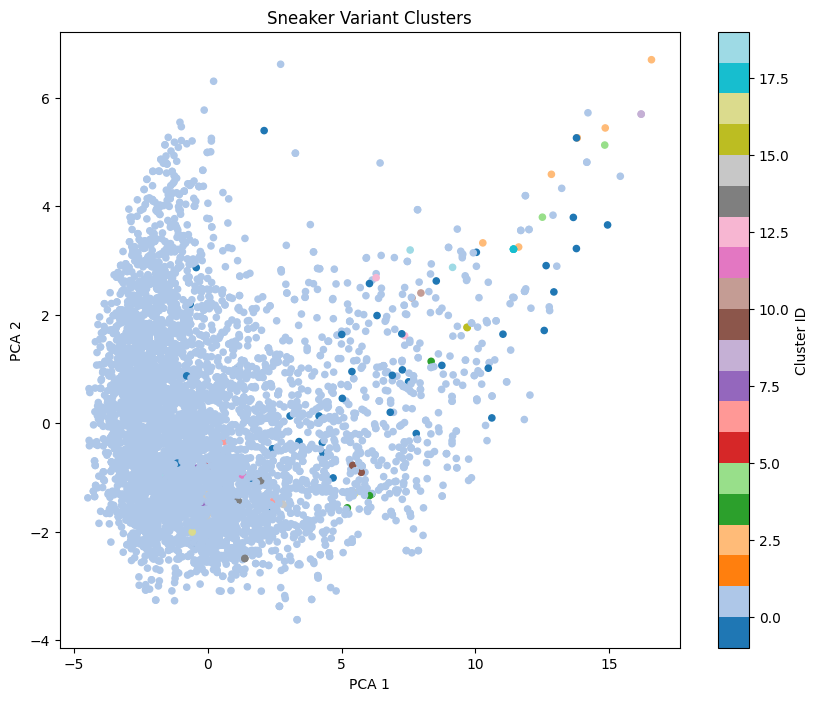

In [103]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce similarity to distance
distance_matrix = 1 - combined_sim

# Use PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(distance_matrix)

# Plot
plt.figure(figsize=(10, 8))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df_filtered['variant_group'], cmap='tab20', s=20)
plt.title("Sneaker Variant Clusters")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label="Cluster ID")
plt.show()

### **Evaluate on the labeled sample**

In [105]:
###evaluate clutsering
from sklearn.metrics import silhouette_score

labels = df_filtered['variant_group'].to_numpy()

# Remove noise points
mask = labels != -1

# Ensure diagonal is zero for silhouette computation
np.fill_diagonal(combined_dist, 0)

if mask.sum() > 1:
    score = silhouette_score(combined_dist[mask][:, mask], labels[mask], metric='precomputed')
    print("Silhouette Score (no noise):", round(score, 4))
else:
    print("Not enough clustered points to compute silhouette score.")

Silhouette Score (no noise): -0.049


Not a good clustering. Now evaluate using a labeled sample of the dataset:

In [107]:
sample_df.columns

Index(['EAN', 'size', 'brand', 'color', 'category', 'heelType', 'shoeType',
       'shoeWidth', 'heelHeight', 'returnable', 'name [el_CY]', 'name [en_GB]',
       'updateOnDelta', 'refinementColor', 'variantGroupCode',
       'jiniusSkuMatchCode', 'longDescription [el_CY]',
       'shortDescription [en_GB]', 'mainImage.source',
       'mainImage.original_url', 'shortDescription [el_CY]',
       'secondary_image_1.source', 'secondary_image_1.original_url',
       'secondary_image_2.source', 'secondary_image_2.original_url',
       'secondary_image_3.source', 'secondary_image_3.original_url',
       'longDescription [en_GB]', 'fashionMaterial', 'name', 'longDescription',
       'shortDescription', 'mirakl_product_id', 'group_id1', 'name [en_GB',
       'group_id2', 'final_group_id', 'final_group_id_clip_strict',
       'manual_group_id', 'manual_group_name'],
      dtype='object')

In [108]:
import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.metrics.pairwise import cosine_distances
from collections import Counter

# Load CLIP image embeddings
clip_embeddings = np.load("clip_embeddings.npy")

# Load product IDs from CSV
clip_ids = pd.read_csv("clip_ids.csv")["mirakl_product_id"].tolist()


# ---------------- 1. Merge CLIP embeddings into the labeled sample ----------------

# clip_embeddings: numpy array with embeddings
# clip_ids: list of mirakl_product_id aligned with clip_embeddings
# sample_df: DataFrame with labeled subset and column 'mirakl_product_id' + 'manual_group_id'

# Step 1a: Create a DataFrame for embeddings and ids
df_clip_emb = pd.DataFrame({
    "mirakl_product_id": clip_ids,
    "clip_embedding": list(clip_embeddings)  # list of np arrays per row
})

# Step 1b: Merge to get embeddings for the sample
merged_df = sample_df.merge(df_clip_emb, on="mirakl_product_id", how="inner")

# ---------------- 2. Extract feature matrix ----------------
# Convert the list of vectors into a single numpy array
X = np.vstack(merged_df["clip_embedding"].values)

# ---------------- 3. Compute pairwise distances ----------------
# Cosine distance is 1 - cosine similarity
distance_matrix = cosine_distances(X)

# ---------------- 4. Run DBSCAN ----------------
dbscan = DBSCAN(eps=0.5, min_samples=2, metric='precomputed')
cluster_labels = dbscan.fit_predict(distance_matrix)

# ---------------- 5. Prepare predicted and true label dataframes ----------------

# Create DataFrame with predicted clusters
predicted_df = pd.DataFrame({
    "product_id": merged_df["mirakl_product_id"],
    "predicted_cluster": cluster_labels
})

# Create DataFrame with ground truth labels
manual_df = sample_df[["mirakl_product_id", "manual_group_id"]].rename(
    columns={"mirakl_product_id": "product_id"}
)

# Merge both on product ID
merged_eval = pd.merge(predicted_df, manual_df, on="product_id", how="inner")
merged_eval.rename(columns={"manual_group_id": "true_group"}, inplace=True)

# ---------------- 6. Evaluation: micro-averaged within-cluster accuracy ----------------
def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
    total_correct = 0
    total_items = len(df)

    for _, cluster_df in df.groupby(pred_col):
        if len(cluster_df) == 0:
            continue
        true_labels = cluster_df[true_col]
        most_common_label_count = Counter(true_labels).most_common(1)[0][1]
        total_correct += most_common_label_count

    return total_correct / total_items

# Compute and display score
score = microavg_within_cluster_accuracy(merged_eval)
print(f"✅ Micro-averaged within-cluster accuracy: {score:.3f}")

✅ Micro-averaged within-cluster accuracy: 0.015


In [109]:
from collections import defaultdict

# Merge merchant info
merchant_map = df_sources.set_index("mirakl_product_id")["provider_code"].to_dict()

# Cleaned JSON
variant_groups = {}
for group_id in df_filtered["variant_group"].unique():
    if group_id == -1:
        continue  # skip noise
    group = df_filtered[df_filtered["variant_group"] == group_id]
    first = group.iloc[0]
    group_json = {
        "model_name": first["product_name"],
        "brand": first["brand"],
        "variants": [],
        "offers": []
    }
    seen = set()
    for _, row in group.iterrows():
        variant_key = (row["color"], row["size"])
        if variant_key not in seen:
            seen.add(variant_key)
            group_json["variants"].append({
                "color": row["color"],
                "size": row["size"],
                "image": row.get("mainImage.original_url", ""),
                "task1_approach1": row["task1_approach1"]
            })
        group_json["offers"].append({
            "merchant": merchant_map.get(row["task1_approach1"], "unknown"),
            "product_sku": row.get("product_sku", ""),
            "task1_approach1": row["task1_approach1"]
        })
    variant_groups[str(group_id)] = group_json

# Save result
with open("variant_groups_cleaned.json", "w") as f:
    json.dump(variant_groups, f, indent=2)

In [110]:
with open("variant_groups.json", "r") as f:
    data = json.load(f)

# Preview the first group
first_key = list(data.keys())[0]
print(json.dumps(data[first_key], indent=2))

{
  "model_name": "Gel-rocket 11 mens volleyball/indoor shoes",
  "brand": "ASICS",
  "variants": [
    {
      "color": "White / Black",
      "size": "44",
      "image": "https://administrator.athlokinisi.com.cy/product_catalog/groups/162995/1071a091-101.jpg",
      "product_group_id": 1041.0
    },
    {
      "color": "Black",
      "size": "44",
      "image": "https://privesports.com.cy/product_catalog/groups/66610/vn0a3mtjt2j1-black.jpg",
      "product_group_id": 4423.0
    },
    {
      "color": NaN,
      "size": "44.5",
      "image": "https://jinius-prod.mirakl.net/mmp/media/product-media/34383/IH6003-1.jpg",
      "product_group_id": NaN
    },
    {
      "color": "White / Black / Volt",
      "size": "42",
      "image": "https://administrator.athlokinisi.com.cy/product_catalog/groups/164557/ct2927-100.jpg",
      "product_group_id": 2839.0
    },
    {
      "color": "Black/white",
      "size": "11/EU 46",
      "image": "https://s3.gy.digital/famousports/uploads/ass

In [111]:
### provider unknown for some reason

In [112]:
# cluster with group id 0 is extremely large, most sneakers fit under this category
# should we reduce the value of eps ??? in DBSCAN



In [113]:
# tuning similarity weights for better clustering

import matplotlib.pyplot as plt
import requests
from PIL import Image
from io import BytesIO

from sklearn.cluster import DBSCAN
from sklearn.metrics import pairwise_distances

def try_similarity_weights(text_sim, image_sim, structured_sim, df, eps=0.5, min_samples=2):
    best_config = None
    results = []
    for text_w in [0.2, 0.3, 0.4]:
        for img_w in [0.4, 0.5, 0.6]:
            struc_w = 1.0 - text_w - img_w
            if struc_w < 0: continue
            combined_sim = (
                text_w * text_sim +
                img_w * image_sim +
                struc_w * structured_sim
            )
            combined_sim = np.clip(combined_sim, 0, 1)
            dist = 1 - combined_sim
            labels = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed').fit_predict(dist)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = sum(labels == -1)
            results.append((text_w, img_w, struc_w, n_clusters, n_noise))
            print(f"Text: {text_w:.1f}, Image: {img_w:.1f}, Structured: {struc_w:.1f} => Clusters: {n_clusters}, Noise: {n_noise}")
    return results

In [114]:
try_similarity_weights(text_sim_matrix, image_sim_matrix, structured_sim_matrix, df_filtered)

Text: 0.2, Image: 0.4, Structured: 0.4 => Clusters: 24, Noise: 23
Text: 0.2, Image: 0.5, Structured: 0.3 => Clusters: 8, Noise: 8
Text: 0.2, Image: 0.6, Structured: 0.2 => Clusters: 2, Noise: 5
Text: 0.3, Image: 0.4, Structured: 0.3 => Clusters: 33, Noise: 31
Text: 0.3, Image: 0.5, Structured: 0.2 => Clusters: 14, Noise: 20
Text: 0.3, Image: 0.6, Structured: 0.1 => Clusters: 5, Noise: 10
Text: 0.4, Image: 0.4, Structured: 0.2 => Clusters: 43, Noise: 57
Text: 0.4, Image: 0.5, Structured: 0.1 => Clusters: 20, Noise: 42
Text: 0.4, Image: 0.6, Structured: 0.0 => Clusters: 6, Noise: 19


[(0.2, 0.4, 0.4, 24, 23),
 (0.2, 0.5, 0.30000000000000004, 8, 8),
 (0.2, 0.6, 0.20000000000000007, 2, 5),
 (0.3, 0.4, 0.29999999999999993, 33, 31),
 (0.3, 0.5, 0.19999999999999996, 14, 20),
 (0.3, 0.6, 0.09999999999999998, 5, 10),
 (0.4, 0.4, 0.19999999999999996, 43, 57),
 (0.4, 0.5, 0.09999999999999998, 20, 42),
 (0.4, 0.6, 0.0, 6, 19)]

In [115]:
print("text_sim_matrix shape:", text_sim_matrix.shape)
print("image_sim_matrix shape:", image_sim_matrix.shape)
print("structured_sim_matrix shape:", structured_sim_matrix.shape)


text_sim_matrix shape: (5679, 5679)
image_sim_matrix shape: (5679, 5679)
structured_sim_matrix shape: (5679, 5679)


In [116]:
 # Text: 0.4, Image: 0.4, Structured: 0.2 => Clusters: 43, Noise: 57   more clusters -> likely more correct??? 




Chat recommends: (evi : ekama ta implement but not spoudea)

lowering eps 

Use PCA/UMAP before DBSCAN

Switch to HDBSCAN  -> different algorithm - maybe better?

Visual Check After Clustering -> will do anyway

Avoid Normalizing If Not Needed   -> i think we need to though

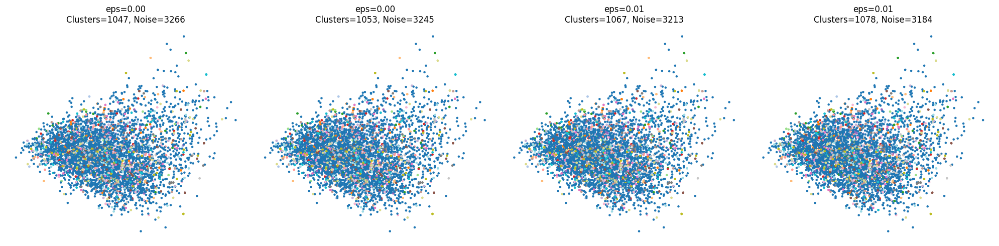

In [118]:
## trying several epsilon values - much smaller

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

# Reduce dimensions using PCA for visualization
def reduce_with_pca(features, n_components=2):
    pca = PCA(n_components=n_components)
    return pca.fit_transform(features)

# Run DBSCAN at multiple eps values, store results
def run_dbscan_varying_eps(image_features, eps_values):
    reduced_features = reduce_with_pca(image_features, n_components=2)
    all_results = []

    fig, axs = plt.subplots(1, len(eps_values), figsize=(5 * len(eps_values), 5))
    if len(eps_values) == 1:
        axs = [axs]

    for i, eps in enumerate(eps_values):
        db = DBSCAN(eps=eps, min_samples=2, metric='cosine')
        labels = db.fit_predict(image_features)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = sum(labels == -1)

        axs[i].scatter(reduced_features[:, 0], reduced_features[:, 1], c=labels, cmap='tab20', s=5)
        axs[i].set_title(f"eps={eps:.2f}\nClusters={n_clusters}, Noise={n_noise}")
        axs[i].axis('off')

        all_results.append({
            'eps': eps,
            'labels': labels,
            'n_clusters': n_clusters,
            'n_noise': n_noise
        })

    plt.tight_layout()
    plt.show()
    return all_results

# Example call (you must define image_features beforehand or load from .npy)
# eps_values = [0.15, 0.2, 0.25, 0.3]
# results = run_dbscan_varying_eps(image_features, eps_values)
image_features = np.load("image_features.npy")
results = run_dbscan_varying_eps(image_features, [0.001, 0.002, 0.005, 0.01])

For these clusterings we will compute the Silhouette score

In [120]:
#compute silhouette for the above clusterings
for res in results:
    labels = res['labels']
    eps = res['eps']
    mask = labels != -1

    if len(set(labels[mask])) < 2:
        print(f"eps={eps:.4f}: Only one cluster (or none) after removing noise. Cannot compute silhouette.")
        continue

    # Compute Silhouette Score using cosine distance on valid points only
    try:
        score = silhouette_score(
            image_features[mask], 
            labels[mask], 
            metric='cosine'
        )
        print(f"eps={eps:.4f}: Clusters={res['n_clusters']}, Noise={res['n_noise']}, Silhouette={score:.4f}")

    except Exception as e:
        print(f"eps={eps:.4f}: Error computing silhouette - {e}")

eps=0.0010: Clusters=1047, Noise=3266, Silhouette=0.9999
eps=0.0020: Clusters=1053, Noise=3245, Silhouette=0.9996
eps=0.0050: Clusters=1067, Noise=3213, Silhouette=0.9989
eps=0.0100: Clusters=1078, Noise=3184, Silhouette=0.9968


We observe that lowering epsilon produces very high Silhouette scores (almost 1). However the noise is high, meaning that several products have not been grouped. Some of these probably correspond to variants (which will be investigated later). Following we print the images of the products of a few clusters, for visual inspection. We don't have annotated data yet to compute some other performance metric.

### **Evaluate on sample**

In [123]:
import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.metrics.pairwise import cosine_distances
from collections import Counter

# ---------------- 1. Merge CLIP embeddings into the labeled sample ----------------

# Create a DataFrame for embeddings and mirakl_product_id
df_clip_emb = pd.DataFrame({
    "mirakl_product_id": clip_ids,
    "clip_embedding": list(clip_embeddings)
})

# Merge labeled sample with embeddings
merged_df = sample_df.merge(df_clip_emb, on="mirakl_product_id", how="inner")

# Convert list of embeddings into a matrix
X = np.vstack(merged_df["clip_embedding"].values)

# Compute cosine distances
distance_matrix = cosine_distances(X)

# ---------------- 2. Evaluation Function ----------------
def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
    total_correct = 0
    total_items = len(df)

    for _, cluster_df in df.groupby(pred_col):
        if len(cluster_df) == 0:
            continue
        true_labels = cluster_df[true_col]
        most_common_label_count = Counter(true_labels).most_common(1)[0][1]
        total_correct += most_common_label_count

    return total_correct / total_items

# ---------------- 3. Run DBSCAN for each eps ----------------
eps_values = [0.0010, 0.0020, 0.0050, 0.0100]

for eps in eps_values:
    # Fit DBSCAN
    dbscan = DBSCAN(eps=eps, min_samples=2, metric='precomputed')
    cluster_labels = dbscan.fit_predict(distance_matrix)

    # Build predicted dataframe
    predicted_df = pd.DataFrame({
        "product_id": merged_df["mirakl_product_id"],
        "predicted_cluster": cluster_labels
    })

    # Ground truth
    manual_df = sample_df[["mirakl_product_id", "manual_group_id"]].rename(
        columns={"mirakl_product_id": "product_id"}
    )

    # Merge and rename for evaluation
    merged_eval = pd.merge(predicted_df, manual_df, on="product_id", how="inner")
    merged_eval.rename(columns={"manual_group_id": "true_group"}, inplace=True)

    # Evaluate
    score = microavg_within_cluster_accuracy(merged_eval)
    print(f"eps = {eps:.4f} → Micro-averaged within-cluster accuracy: {score:.3f}")

eps = 0.0010 → Micro-averaged within-cluster accuracy: 0.091
eps = 0.0020 → Micro-averaged within-cluster accuracy: 0.091
eps = 0.0050 → Micro-averaged within-cluster accuracy: 0.093
eps = 0.0100 → Micro-averaged within-cluster accuracy: 0.093


In [124]:
# For a specific eps, print the images of some products in the same cluster, for visual inspection
target_eps = 0.001
result = next(res for res in results if abs(res['eps'] - target_eps) < 1e-6)

labels_eps = result['labels']
df_filtered['cluster_label'] = labels_eps

# Exclude noise (-1)
valid_clusters = sorted(c for c in set(labels_eps) if c != -1)

# Take first 5 clusters
selected_clusters = valid_clusters[:10]

print(f"Selected clusters for visualization: {selected_clusters}")

Selected clusters for visualization: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [125]:
from IPython.display import display, HTML

def show_clusters_as_html(df, cluster_ids, max_items=6):
    for cluster_id in cluster_ids:
        cluster_df = df[df['cluster_label'] == cluster_id]
        if cluster_df.empty:
            print(f"Cluster {cluster_id} is empty!")
            continue

        html = f"<h3 style='margin-top:20px'>Cluster {cluster_id} ({len(cluster_df)} items)</h3>"
        html += "<div style='display:flex;flex-wrap:wrap'>"

        for _, row in cluster_df.head(max_items).iterrows():
            name = row.get('product_name', '')
            
            # Choose the best available image
            for col in [
                'mainImage.original_url',
                'secondary_image_1.original_url',
                'secondary_image_2.original_url',
                'secondary_image_3.original_url'
            ]:
                img = row.get(col, '')
                if isinstance(img, str) and img.startswith('http'):
                    break
            else:
                img = ''
            
            html += f"""
                <div style='margin:10px;text-align:center'>
                    <img src='{img}' width='120' style='border-radius:8px'><br>
                    <div style='max-width:120px;font-size:12px'>{name}</div>
                </div>
            """
        html += "</div>"
        display(HTML(html))

In [126]:
show_clusters_as_html(df_filtered, selected_clusters, max_items=6)

From the images of the first 10 clusters, we observe that the products are indeed identical. As an additional validation, in the following code I extract the largest cluster that was created and print the images of its products:

In [128]:
#find the sizes of the clusters
non_noise = df_filtered[df_filtered['cluster_label'] != -1]
cluster_counts = non_noise['cluster_label'].value_counts()
print(cluster_counts)
biggest_cluster_label = cluster_counts.idxmax()
biggest_cluster_size = cluster_counts.max()

print(f"Biggest cluster label: {biggest_cluster_label}")
print(f"Size of biggest cluster: {biggest_cluster_size}")

cluster_label
547     7
9       7
495     6
670     6
510     6
       ..
392     2
393     2
394     2
395     2
1046    2
Name: count, Length: 1047, dtype: int64
Biggest cluster label: 547
Size of biggest cluster: 7


In [129]:
show_clusters_as_html(df_filtered, [biggest_cluster_label], max_items=20)

We observe that the biggest cluster is correct. Also, we observe that some identical products have different names. Following, we will use the same approach to cluster similar products with different variants (Task 2) and see how well it performs for this task.

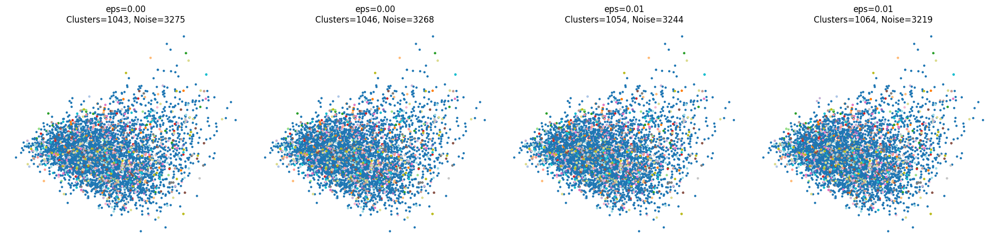

In [131]:
#same thing as before but using pca on images before dbscan to reduce noise

from sklearn.decomposition import PCA

pca = PCA(n_components=50)
image_pca = pca.fit_transform(image_features)

# Reduce dimensions using PCA for visualization
def reduce_with_pca(features, n_components=2):
    pca = PCA(n_components=n_components)
    return pca.fit_transform(features)

# Run DBSCAN at multiple eps values, store results but now on PCA IMAGES
def run_dbscan_varying_eps(image_features, eps_values):
    reduced_features = reduce_with_pca(image_features, n_components=2)
    all_results = []

    fig, axs = plt.subplots(1, len(eps_values), figsize=(5 * len(eps_values), 5))
    if len(eps_values) == 1:
        axs = [axs]

    for i, eps in enumerate(eps_values):
        db = DBSCAN(eps=eps, min_samples=2, metric='cosine')
        labels = db.fit_predict(image_features)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = sum(labels == -1)

        axs[i].scatter(reduced_features[:, 0], reduced_features[:, 1], c=labels, cmap='tab20', s=5)
        axs[i].set_title(f"eps={eps:.2f}\nClusters={n_clusters}, Noise={n_noise}")
        axs[i].axis('off')

        all_results.append({
            'eps': eps,
            'labels': labels,
            'n_clusters': n_clusters,
            'n_noise': n_noise
        })

    plt.tight_layout()
    plt.show()
    return all_results

# Example call (you must define image_features beforehand or load from .npy)
# eps_values = [0.15, 0.2, 0.25, 0.3]
# results = run_dbscan_varying_eps(image_features, eps_values)
image_features = np.load("image_features.npy")
results = run_dbscan_varying_eps(image_pca, [0.001, 0.002, 0.005, 0.01])


# pca doesnt help 

### **Evaluate on sample**

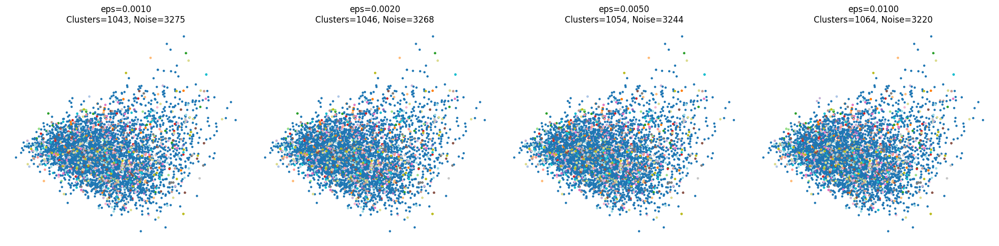

❌ Length mismatch at eps=0.0010
❌ Length mismatch at eps=0.0020
❌ Length mismatch at eps=0.0050
❌ Length mismatch at eps=0.0100


In [134]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from collections import Counter

# ----------------------- Step 1: Load inputs -----------------------
# Load CLIP image features and product IDs
image_features = np.load("image_features.npy")
clip_ids = pd.read_csv("clip_ids.csv")["mirakl_product_id"].tolist()

# Truncate clip_ids to match the number of image features
clip_ids = clip_ids[:len(image_features)]


# Truncate clip_ids to match the number of clustered embeddings
clip_ids_filtered = clip_ids[:len(labels)]


# Assume sample_df contains labeled products with 'mirakl_product_id' and 'manual_group_id'

# ----------------------- Step 2: Define helper functions -----------------------

def reduce_with_pca(features, n_components=2):
    pca = PCA(n_components=n_components)
    return pca.fit_transform(features)

def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
    total_correct = 0
    total_items = len(df)
    for _, cluster_df in df.groupby(pred_col):
        if len(cluster_df) == 0:
            continue
        true_labels = cluster_df[true_col]
        most_common_label_count = Counter(true_labels).most_common(1)[0][1]
        total_correct += most_common_label_count
    return total_correct / total_items

def run_dbscan_varying_eps(image_features, eps_values):
    reduced_features = reduce_with_pca(image_features, n_components=2)
    all_results = []

    fig, axs = plt.subplots(1, len(eps_values), figsize=(5 * len(eps_values), 5))
    if len(eps_values) == 1:
        axs = [axs]

    for i, eps in enumerate(eps_values):
        db = DBSCAN(eps=eps, min_samples=2, metric='cosine')
        labels = db.fit_predict(image_features)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = sum(labels == -1)

        axs[i].scatter(reduced_features[:, 0], reduced_features[:, 1], c=labels, cmap='tab20', s=5)
        axs[i].set_title(f"eps={eps:.4f}\nClusters={n_clusters}, Noise={n_noise}")
        axs[i].axis("off")

        all_results.append({
            'eps': eps,
            'labels': labels,  # ✅ include labels here for evaluation
            'n_clusters': n_clusters,
            'n_noise': n_noise
        })

    plt.tight_layout()
    plt.show()
    return all_results

# ----------------------- Step 3: Apply PCA and run DBSCAN -----------------------

# Reduce features before clustering
pca = PCA(n_components=50)
image_pca = pca.fit_transform(image_features)

eps_values = [0.001, 0.002, 0.005, 0.01]
results = run_dbscan_varying_eps(image_pca, eps_values)

# ----------------------- Step 4: Evaluate clustering for each eps -----------------------

for result in results:
    eps = result['eps']
    labels = result['labels']

    # ✅ Match only the valid number of product IDs
    clip_ids_filtered = clip_ids[:len(labels)]

    if len(clip_ids_filtered) != len(labels):
        print(f"❌ Length mismatch at eps={eps:.4f}")
        continue  # skip this round if not matching

    # Create DataFrame with predicted clusters
    predicted_df = pd.DataFrame({
        "product_id": clip_ids_filtered,
        "predicted_cluster": labels
    })

    # Merge with manually labeled sample
    merged_df = pd.merge(
        predicted_df,
        sample_df[['mirakl_product_id', 'manual_group_id']],
        left_on="product_id",
        right_on="mirakl_product_id",
        how="inner"
    )
    merged_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

    # Compute accuracy
    score = microavg_within_cluster_accuracy(merged_df)
    print(f"eps={eps:.4f} → Micro-averaged within-cluster accuracy: {score:.3f}")

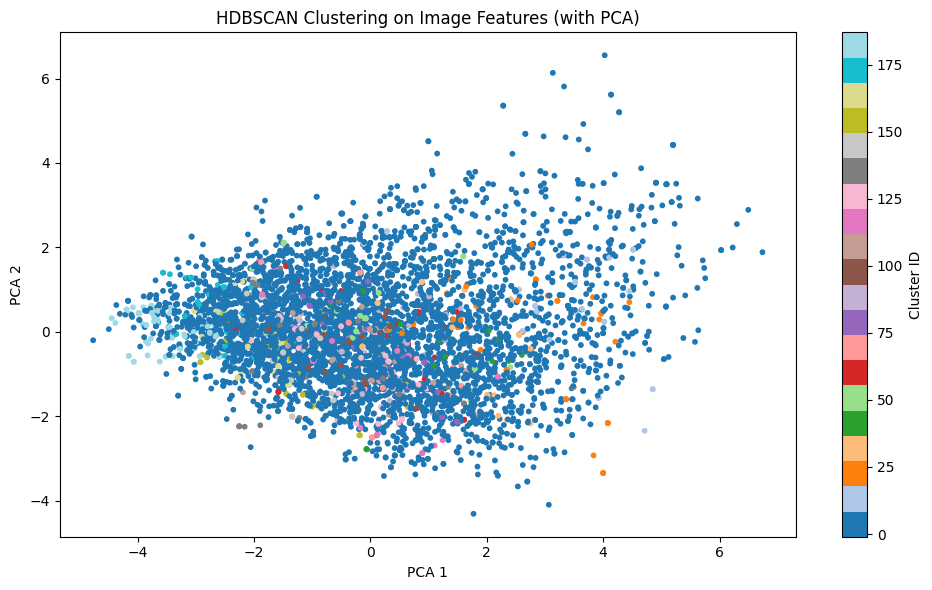

Clusters: 188, Noise Points: 4664


In [135]:
# maybe using HDBSCAN ?????

import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import hdbscan

# Load your image features
image_features = np.load("image_features.npy")  # adjust path as needed

# HDBSCAN clustering
clusterer = hdbscan.HDBSCAN(min_cluster_size=3, metric='euclidean')
labels = clusterer.fit_predict(image_features)

# PCA for visualization
pca = PCA(n_components=2)
pca_result = pca.fit_transform(image_features)

# Plot clusters
plt.figure(figsize=(10, 6))
plt.scatter(pca_result[:, 0], pca_result[:, 1], c=labels, cmap='tab20', s=10)
plt.title("HDBSCAN Clustering on Image Features (with PCA)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label="Cluster ID")
plt.tight_layout()
plt.show()

# Summary
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = sum(labels == -1)
print(f"Clusters: {n_clusters}, Noise Points: {n_noise}")

In [136]:
### more clusters -> good sign ?!?! i think

### **Evaluate on sample**

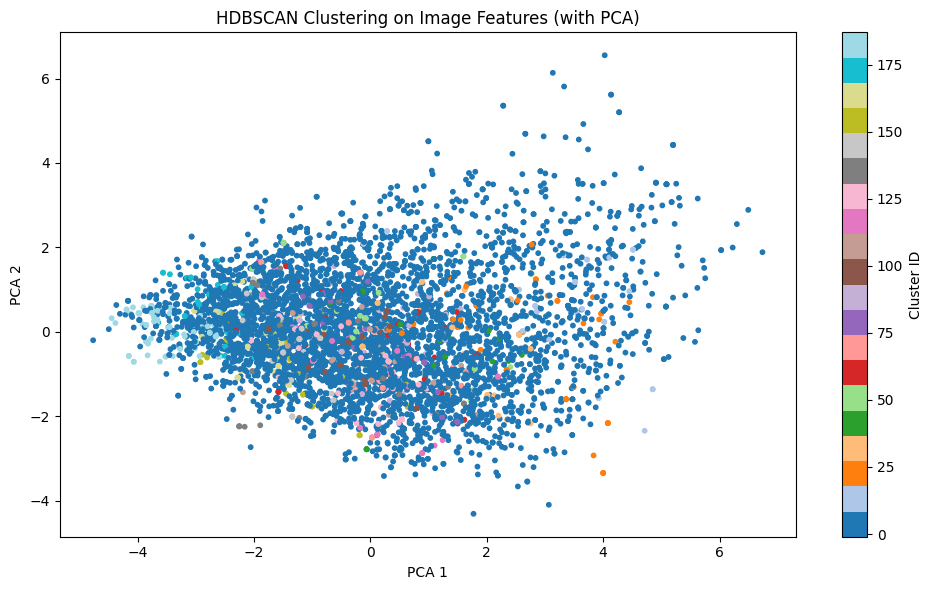

Clusters: 188, Noise Points: 4664
Length of image_features: 5679
Length of clip_ids: 971
Length of labels (from HDBSCAN): 5679
✅ Micro-averaged within-cluster accuracy (HDBSCAN): 0.092


In [139]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from collections import Counter
import hdbscan

# ----------------------- Step 1: Load inputs -----------------------
# Load features and corresponding product IDs
image_features = np.load("image_features.npy")
clip_ids = pd.read_csv("clip_ids.csv")["mirakl_product_id"].tolist()

# Ensure clip_ids matches feature length
clip_ids = clip_ids[:len(image_features)]

# ----------------------- Step 2: Run HDBSCAN -----------------------
clusterer = hdbscan.HDBSCAN(min_cluster_size=3, metric='euclidean')
labels = clusterer.fit_predict(image_features)

# ----------------------- Step 3: Visualize with PCA -----------------------
pca = PCA(n_components=2)
pca_result = pca.fit_transform(image_features)

plt.figure(figsize=(10, 6))
plt.scatter(pca_result[:, 0], pca_result[:, 1], c=labels, cmap='tab20', s=10)
plt.title("HDBSCAN Clustering on Image Features (with PCA)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.colorbar(label="Cluster ID")
plt.tight_layout()
plt.show()

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = sum(labels == -1)
print(f"Clusters: {n_clusters}, Noise Points: {n_noise}")
# ----------------------- Step 4: Evaluate Clustering -----------------------

print(f"Length of image_features: {len(image_features)}")
print(f"Length of clip_ids: {len(clip_ids)}")
print(f"Length of labels (from HDBSCAN): {len(labels)}")

# Load sample_df for evaluation
# (Make sure you have already defined this earlier)
# sample_df = pd.read_csv("your_labeled_sample.csv")  # Uncomment if needed

# Get list of sample product IDs
sample_ids = sample_df["mirakl_product_id"].tolist()

# Assign predicted clusters only to the samples
sample_predicted_df = pd.DataFrame({
    "product_id": sample_ids,
    "predicted_cluster": labels[:len(sample_ids)]
})

# Merge predictions with ground truth labels
merged_df = pd.merge(
    sample_predicted_df,
    sample_df[["mirakl_product_id", "manual_group_id"]],
    left_on="product_id", right_on="mirakl_product_id",
    how="inner"
)
merged_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

# Micro-averaged within-cluster accuracy
def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
    total_correct = 0
    total_items = len(df)
    for _, cluster_df in df.groupby(pred_col):
        if len(cluster_df) == 0:
            continue
        true_labels = cluster_df[true_col]
        most_common_label_count = Counter(true_labels).most_common(1)[0][1]
        total_correct += most_common_label_count
    return total_correct / total_items

# Evaluate
score = microavg_within_cluster_accuracy(merged_df)
print(f"✅ Micro-averaged within-cluster accuracy (HDBSCAN): {score:.3f}")


In [140]:
import hdbscan
import numpy as np

def try_similarity_weights_hdbscan(text_sim, image_sim, structured_sim, df, min_cluster_size=3, min_samples=2):
    results = []
    for text_w in [0.2, 0.3, 0.4]:
        for img_w in [0.4, 0.5, 0.6]:
            struc_w = 1.0 - text_w - img_w
            if struc_w < 0:
                continue
            # Combine weighted similarity matrix
            combined_sim = (
                text_w * text_sim +
                img_w * image_sim +
                struc_w * structured_sim
            )
            combined_sim = np.clip(combined_sim, 0, 1)
            combined_dist = 1 - combined_sim

            # HDBSCAN requires a condensed or full distance matrix
            clusterer = hdbscan.HDBSCAN(min_cluster_size=min_cluster_size,
                                        min_samples=min_samples,
                                        metric='precomputed')
            labels = clusterer.fit_predict(combined_dist)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = sum(labels == -1)
            results.append((text_w, img_w, struc_w, n_clusters, n_noise))
            print(f"Text: {text_w:.1f}, Image: {img_w:.1f}, Structured: {struc_w:.1f} → Clusters: {n_clusters}, Noise: {n_noise}")
    return results



# Re-define HDBSCAN visual tuning function
def try_similarity_weights_hdbscan_with_visuals(text_sim, image_sim, structured_sim, df, min_cluster_size=3, min_samples=2):
    import hdbscan

    results = []
    for text_w in [0.2, 0.3, 0.4]:
        for img_w in [0.4, 0.5, 0.6]:
            struc_w = 1.0 - text_w - img_w
            if struc_w < 0:
                continue
            combined_sim = (
                text_w * text_sim +
                img_w * image_sim +
                struc_w * structured_sim
            )
            combined_sim = np.clip(combined_sim, 0, 1)
            combined_dist = 1 - combined_sim

            # Run HDBSCAN
            clusterer = hdbscan.HDBSCAN(min_cluster_size=min_cluster_size,
                                        min_samples=min_samples,
                                        metric='precomputed')
            labels = clusterer.fit_predict(combined_dist)
            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            n_noise = sum(labels == -1)
            print(f"Text: {text_w:.1f}, Image: {img_w:.1f}, Structured: {struc_w:.1f} → Clusters: {n_clusters}, Noise: {n_noise}")

            # PCA for visualization
            pca = PCA(n_components=2)
            pca_features = pca.fit_transform(combined_sim)
            plt.figure(figsize=(6, 5))
            plt.scatter(pca_features[:, 0], pca_features[:, 1], c=labels, cmap='tab20', s=10)
            plt.title(f"HDBSCAN: T:{text_w}, I:{img_w}, S:{struc_w}\nClusters={n_clusters}, Noise={n_noise}")
            plt.xlabel("PCA 1")
            plt.ylabel("PCA 2")
            plt.colorbar(label="Cluster ID")
            plt.tight_layout()
            plt.show()

            results.append({
                "text_weight": text_w,
                "image_weight": img_w,
                "structured_weight": struc_w,
                "n_clusters": n_clusters,
                "n_noise": n_noise,
                "labels": labels
            })
    return results

Text: 0.2, Image: 0.4, Structured: 0.4 → Clusters: 440, Noise: 2395


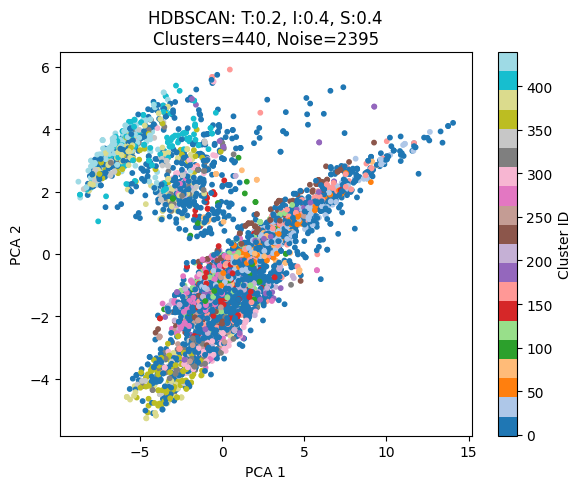

Text: 0.2, Image: 0.5, Structured: 0.3 → Clusters: 413, Noise: 2467


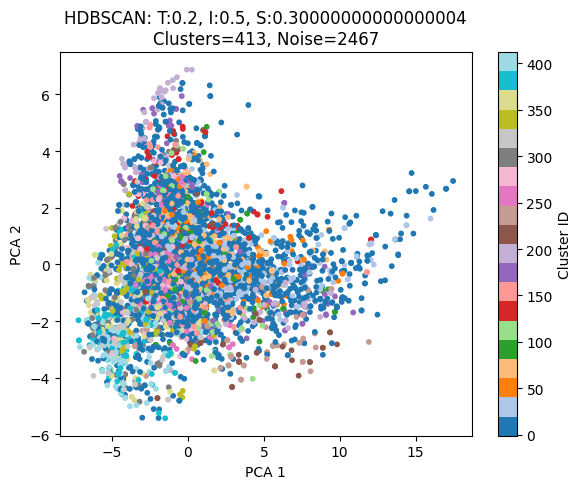

Text: 0.2, Image: 0.6, Structured: 0.2 → Clusters: 421, Noise: 2293


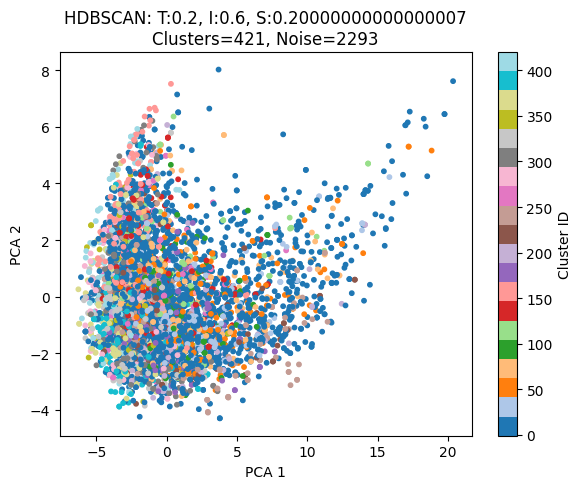

Text: 0.3, Image: 0.4, Structured: 0.3 → Clusters: 435, Noise: 2254


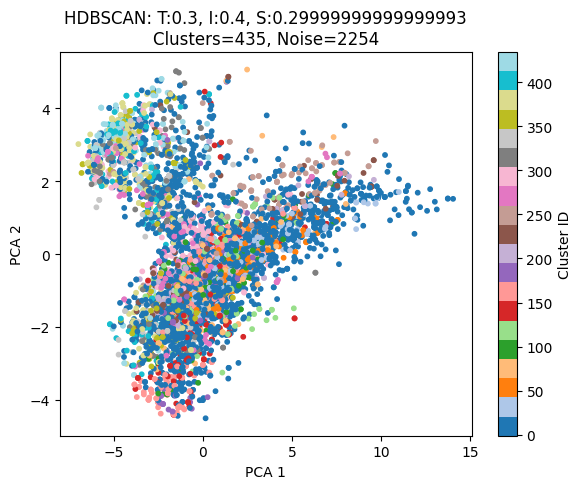

Text: 0.3, Image: 0.5, Structured: 0.2 → Clusters: 464, Noise: 1898


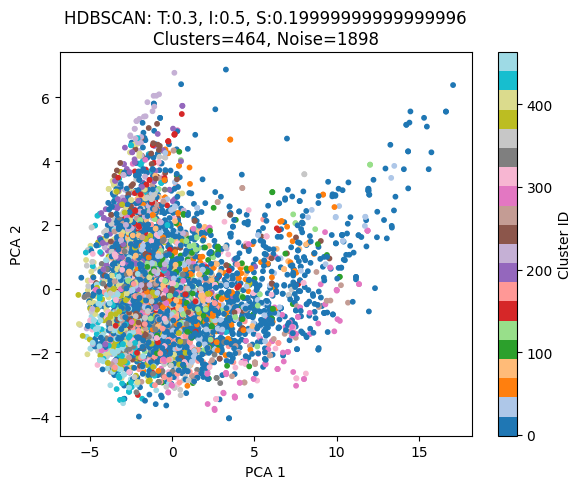

Text: 0.3, Image: 0.6, Structured: 0.1 → Clusters: 469, Noise: 1739


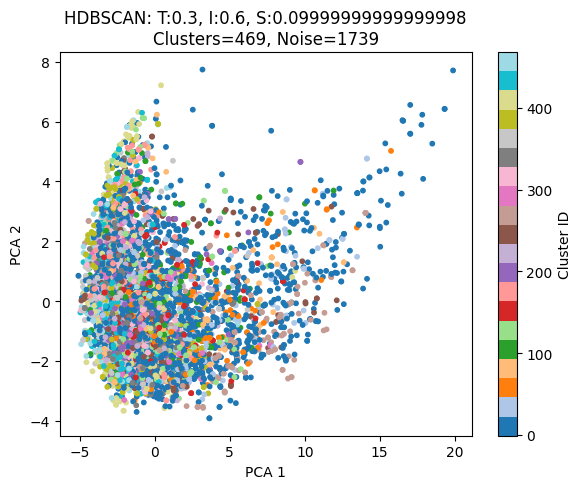

Text: 0.4, Image: 0.4, Structured: 0.2 → Clusters: 497, Noise: 1790


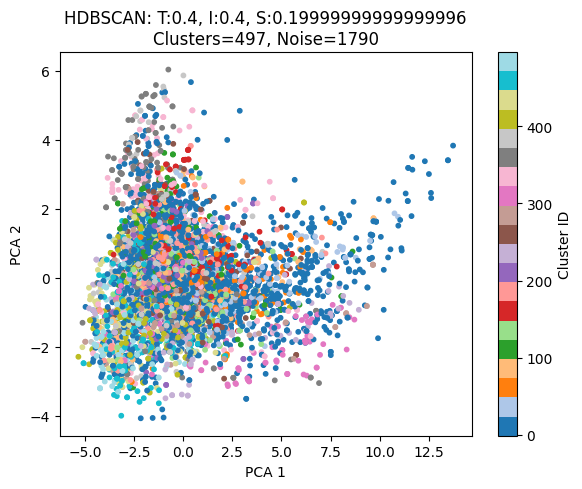

Text: 0.4, Image: 0.5, Structured: 0.1 → Clusters: 493, Noise: 1673


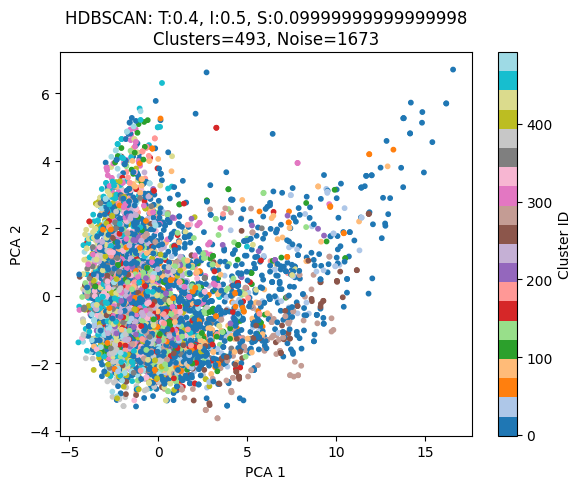

Text: 0.4, Image: 0.6, Structured: 0.0 → Clusters: 492, Noise: 1744


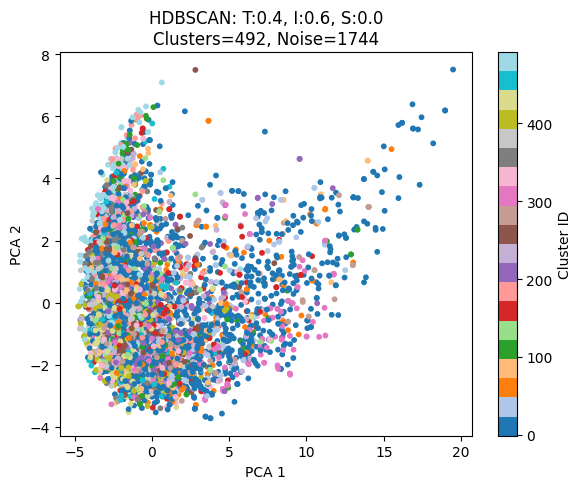

[{'text_weight': 0.2,
  'image_weight': 0.4,
  'structured_weight': 0.4,
  'n_clusters': 440,
  'n_noise': 2395,
  'labels': array([115, 131,  -1, ...,  23, 149, 149], dtype=int64)},
 {'text_weight': 0.2,
  'image_weight': 0.5,
  'structured_weight': 0.30000000000000004,
  'n_clusters': 413,
  'n_noise': 2467,
  'labels': array([107, 110,  -1, ...,  19, 120, 120], dtype=int64)},
 {'text_weight': 0.2,
  'image_weight': 0.6,
  'structured_weight': 0.20000000000000007,
  'n_clusters': 421,
  'n_noise': 2293,
  'labels': array([125,  97,  -1, ...,  19, 107, 107], dtype=int64)},
 {'text_weight': 0.3,
  'image_weight': 0.4,
  'structured_weight': 0.29999999999999993,
  'n_clusters': 435,
  'n_noise': 2254,
  'labels': array([148, 127,  -1, ...,  12,  75,  75], dtype=int64)},
 {'text_weight': 0.3,
  'image_weight': 0.5,
  'structured_weight': 0.19999999999999996,
  'n_clusters': 464,
  'n_noise': 1898,
  'labels': array([152, 118,  -1, ...,  33, 136, 136], dtype=int64)},
 {'text_weight': 0.3,

In [141]:
try_similarity_weights_hdbscan_with_visuals(
    text_sim_matrix,
    image_sim_matrix,
    structured_sim_matrix,
    df_filtered,
    min_cluster_size=4,
    min_samples=2)

### **Evaluate on sample**

Text: 0.2, Image: 0.4, Structured: 0.4 → Clusters: 440, Noise: 2395


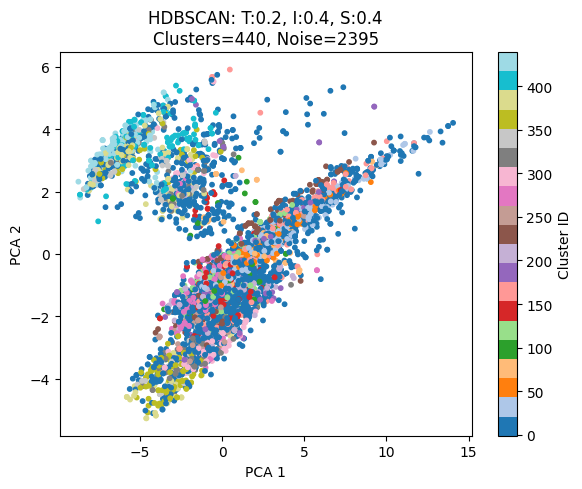

Text: 0.2, Image: 0.5, Structured: 0.3 → Clusters: 413, Noise: 2467


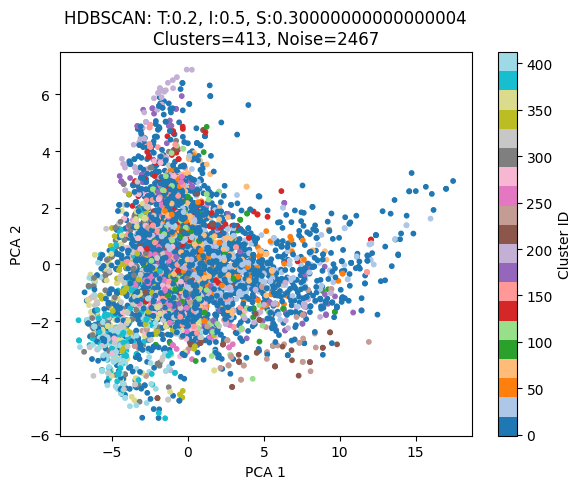

Text: 0.2, Image: 0.6, Structured: 0.2 → Clusters: 421, Noise: 2293


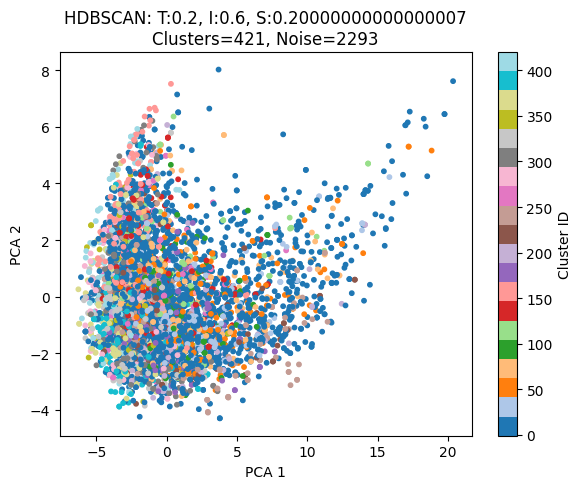

Text: 0.3, Image: 0.4, Structured: 0.3 → Clusters: 435, Noise: 2254


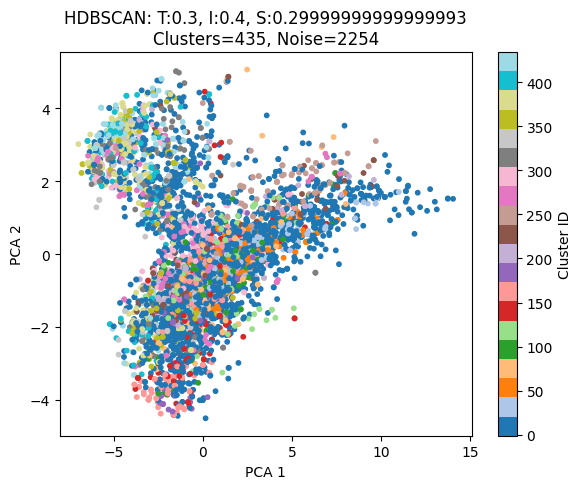

Text: 0.3, Image: 0.5, Structured: 0.2 → Clusters: 464, Noise: 1898


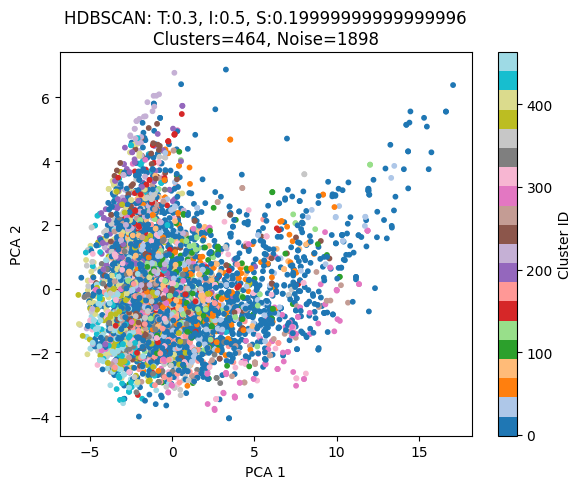

Text: 0.3, Image: 0.6, Structured: 0.1 → Clusters: 469, Noise: 1739


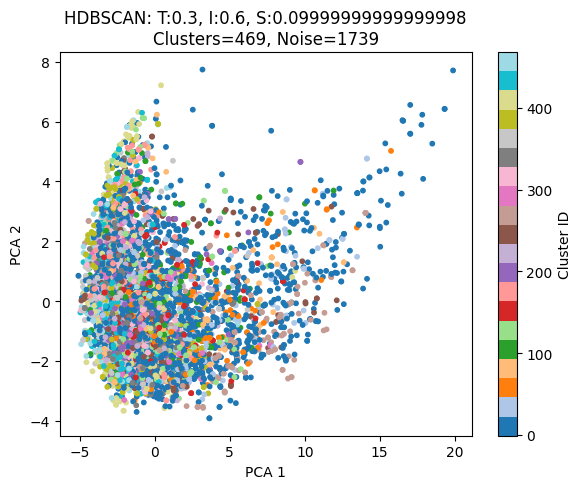

Text: 0.4, Image: 0.4, Structured: 0.2 → Clusters: 497, Noise: 1790


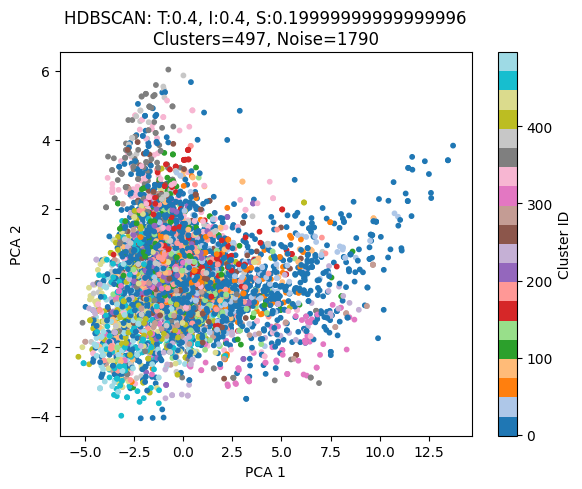

Text: 0.4, Image: 0.5, Structured: 0.1 → Clusters: 493, Noise: 1673


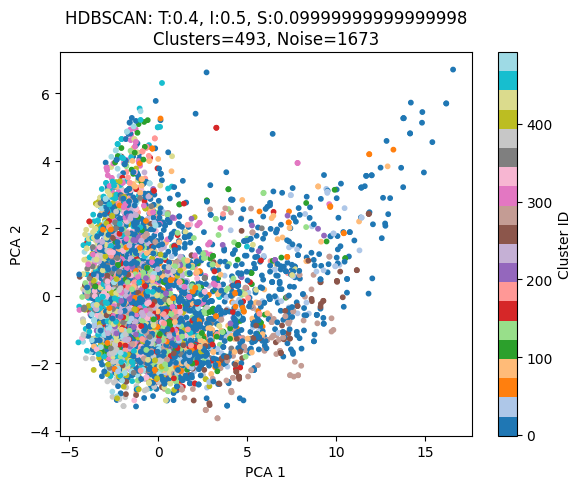

Text: 0.4, Image: 0.6, Structured: 0.0 → Clusters: 492, Noise: 1744


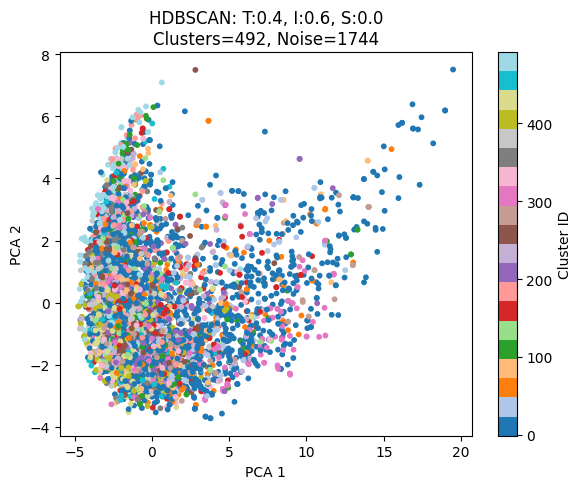

KeyError: 'mirakl_product_id'

In [143]:
# Define accuracy function (if not already)
from collections import Counter

def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
    total_correct = 0
    total_items = len(df)
    for _, cluster_df in df.groupby(pred_col):
        if len(cluster_df) == 0:
            continue
        true_labels = cluster_df[true_col]
        most_common_label_count = Counter(true_labels).most_common(1)[0][1]
        total_correct += most_common_label_count
    return total_correct / total_items

# Run clustering
results = try_similarity_weights_hdbscan_with_visuals(
    text_sim_matrix,
    image_sim_matrix,
    structured_sim_matrix,
    df_filtered,
    min_cluster_size=4,
    min_samples=2
)

# Evaluate each result
for r in results:
    labels = r["labels"]

    if len(labels) != len(df_filtered):
        print(f"❌ Length mismatch — skipping: T={r['text_weight']}, I={r['image_weight']}, S={r['structured_weight']}")
        continue

    predicted_df = pd.DataFrame({
        "product_id": df_filtered["mirakl_product_id"].values,
        "predicted_cluster": labels
    })

    merged_df = pd.merge(predicted_df, sample_df[['mirakl_product_id', 'manual_group_id']],
                         left_on="product_id", right_on="mirakl_product_id", how="inner")
    merged_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

    score = microavg_within_cluster_accuracy(merged_df)
    print(f"✅ T={r['text_weight']:.1f}, I={r['image_weight']:.1f}, S={r['structured_weight']:.1f} → "
          f"Micro-Avg Accuracy: {score:.3f}")

## Task 2: Match similar products with different variants

In the previous section we identified a method to cluster identical products using DBSCAN based on the similarity among products (using image features, product features, like brand, color, and product name). However the eps parameter was too small, meaning that only very similar products get clustered together (exact matches, near-duplicates). Now, we will investigate which values of eps will group variants. As a first step, we cluster using several values of eps and compute the Silhouette score on each.

In [167]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

#define possible values of eps parameter
eps_values = np.arange(0.01, 0.51, 0.01)

results = []

for eps in eps_values:
    print(f"\nRunning DBSCAN for eps = {eps}")

    # Fit DBSCAN
    model = DBSCAN(eps=eps, min_samples=2, metric='precomputed')
    labels = model.fit_predict(combined_dist)

    # Exclude noise
    mask = labels != -1
    n_clusters = len(set(labels[mask]))

    if n_clusters < 2:
        #print(f"  Not enough clusters after noise filtering (n_clusters={n_clusters}). Skipping silhouette.")
        score = None
    else:
        # Compute silhouette (note: combined_dist is precomputed)
        np.fill_diagonal(combined_dist, 0)  # safety for silhouette_score
        try:
            score = silhouette_score(combined_dist[mask][:, mask], labels[mask], metric='precomputed')
            #print(f" Silhouette Score: {score:.4f}")
        except Exception as e:
            #print(f"  Error computing silhouette: {e}")
            score = None

    # Store results
    results.append({
        'eps': eps,
        'n_clusters': n_clusters,
        'silhouette_score': score,
        'noise_count': np.sum(labels == -1)
    })


Running DBSCAN for eps = 0.01

Running DBSCAN for eps = 0.02

Running DBSCAN for eps = 0.03

Running DBSCAN for eps = 0.04

Running DBSCAN for eps = 0.05

Running DBSCAN for eps = 0.060000000000000005

Running DBSCAN for eps = 0.06999999999999999

Running DBSCAN for eps = 0.08

Running DBSCAN for eps = 0.09

Running DBSCAN for eps = 0.09999999999999999

Running DBSCAN for eps = 0.11

Running DBSCAN for eps = 0.12

Running DBSCAN for eps = 0.13

Running DBSCAN for eps = 0.14

Running DBSCAN for eps = 0.15000000000000002

Running DBSCAN for eps = 0.16

Running DBSCAN for eps = 0.17

Running DBSCAN for eps = 0.18000000000000002

Running DBSCAN for eps = 0.19

Running DBSCAN for eps = 0.2

Running DBSCAN for eps = 0.21000000000000002

Running DBSCAN for eps = 0.22

Running DBSCAN for eps = 0.23

Running DBSCAN for eps = 0.24000000000000002

Running DBSCAN for eps = 0.25

Running DBSCAN for eps = 0.26

Running DBSCAN for eps = 0.27

Running DBSCAN for eps = 0.28

Running DBSCAN for eps = 0

In [168]:
#convert to dataframe for easier inspection
results_df = pd.DataFrame(results)
print(results_df)

     eps  n_clusters  silhouette_score  noise_count
0   0.01         941          0.998723         3602
1   0.02         952          0.993716         3554
2   0.03         977          0.980569         3467
3   0.04        1016          0.957122         3324
4   0.05        1041          0.929795         3200
5   0.06        1043          0.900498         3086
6   0.07        1056          0.869837         2943
7   0.08        1063          0.841709         2793
8   0.09        1054          0.802242         2637
9   0.10        1045          0.781063         2492
10  0.11        1051          0.757760         2312
11  0.12        1044          0.733220         2158
12  0.13        1023          0.701960         2020
13  0.14        1010          0.682045         1876
14  0.15        1003          0.664931         1729
15  0.16         981          0.652755         1636
16  0.17         966          0.625556         1523
17  0.18         939          0.614500         1444
18  0.19    

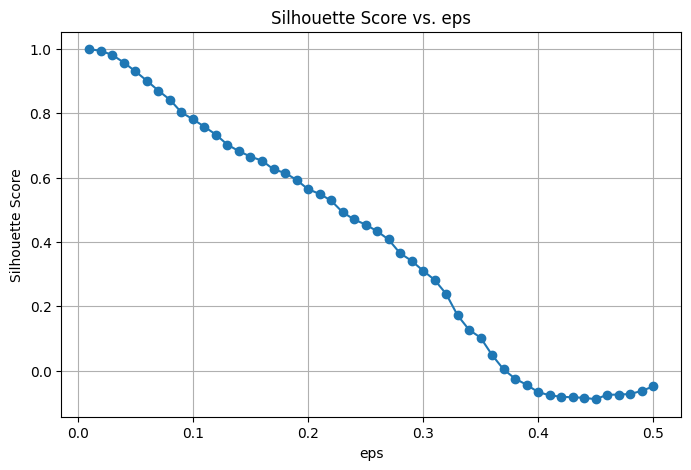

In [169]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(results_df['eps'], results_df['silhouette_score'], marker='o')
plt.title('Silhouette Score vs. eps')
plt.xlabel('eps')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

For eps = 0.25 we observe, from the previous output, that less than 1000 of the data are noise (they were not grouped), but some of these might correspond to unique products? Try DBSCAN for this eps

In [171]:
from sklearn.cluster import DBSCAN
#arbitrarily chosen eps
chosen_eps = 0.25

dbscan_model = DBSCAN(eps=chosen_eps, min_samples=2, metric='precomputed')
labels_eps = dbscan_model.fit_predict(combined_dist)

# Assign to DataFrame
df_filtered['cluster_label'] = labels_eps

In [172]:
# Noise is labeled -1, exclude it
valid_clusters = sorted([c for c in set(labels_eps) if c != -1])

# Take the first 5
selected_clusters = valid_clusters[:10]

print(f"First 5 clusters (excluding noise): {selected_clusters}")

First 5 clusters (excluding noise): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [173]:
show_clusters_as_html(df_filtered, selected_clusters, max_items=8)

We capture some variants, however we have some products that are not clustered correctly (e.g. see cluster 1)

## Task 1: Match identical products

#### **Approach 3:** Group products using image processing and descriptions

From previous EDA we observe that short descriptions in English have no missing values, while long descriptions are missing for almost all records. In this approach, we will vectorize short English descriptions and combine them with the image embeddings. Then we will use those vectors to cluster.

In [178]:
# vectorize product descriptions

# Fill NaNs with empty strings and convert to str just in case
texts = df_filtered['shortDescription [en_GB]'].fillna('').astype(str)

# Initialize and fit the vectorizer
vectorizer = TfidfVectorizer(stop_words='english')
text_features = vectorizer.fit_transform(texts)

In [179]:
# tfidf_matrix is a sparse matrix of shape (n_rows, n_terms)
print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (5679, 2311)


To be able to combine the description embeddings with the image embeddings, we have to reduce both to the same dimension.

In [181]:
#Let's try reducing to 300 dimensions for beginning
pca_dim = 300
image_vec = PCA(n_components=pca_dim).fit_transform(image_features)
text_vec = PCA(n_components=pca_dim).fit_transform(text_features.toarray())

#### **Approach 3.1:** Combine the embeddings using concatenation

In [183]:
#combine  embeddings (we concatenate but we could also try element-wise multiplication)
combined_vec = np.concatenate([image_vec, text_vec], axis=1)

#### **DBSCAN**

In [185]:
#cluster using DBSCAN

# We can tune eps and min_samples
db = DBSCAN(eps=0.5, min_samples=2, metric='euclidean')
cluster_labels = db.fit_predict(combined_vec)

# Add cluster labels back to DataFrame
df_filtered['cluster_label'] = cluster_labels

# See result
print(df_filtered[['product_name', 'cluster_label']].head())

                                 product_name  cluster_label
0  Gel-rocket 11 mens volleyball/indoor shoes             -1
1                          Mens filmore suede              0
2                 React vision worldwide mens             -1
3                       Puma men's x-ray 3 sd             -1
4                       Chuck taylor all star              1


Plot the above clustering:

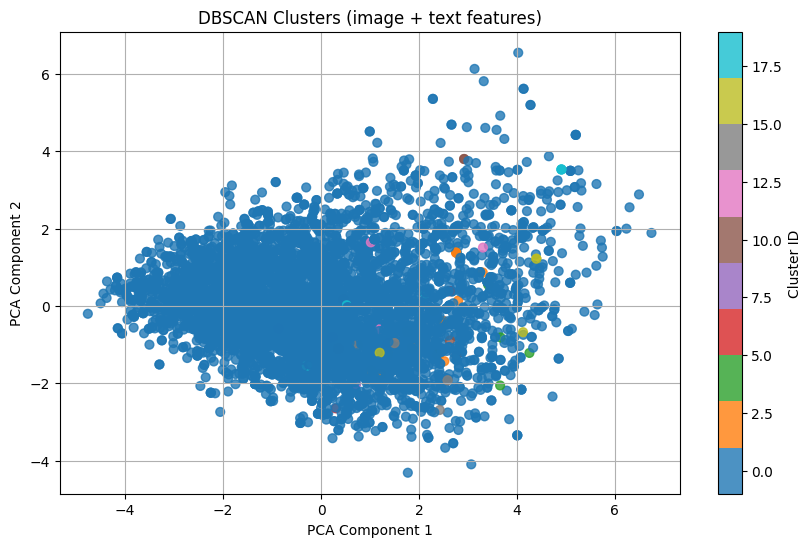

In [187]:
# Reduce to 2D for plotting
plot_embeddings = PCA(n_components=2).fit_transform(combined_vec)

db_labels = df_filtered['cluster_label'].to_numpy()

# Plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(plot_embeddings[:, 0], plot_embeddings[:, 1], c=labels, cmap='tab10', s=40, alpha=0.8)
plt.title("DBSCAN Clusters (image + text features)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.grid(True)
plt.show()

Evaluate the performance of the clustering using the Silhouette score.

In [189]:
from sklearn.metrics import silhouette_score
if len(set(db_labels)) > 1:  # silhouette score not valid if only 1 cluster
    score_dbscan = silhouette_score(combined_vec, db_labels)
    print("DBSCAN Silhouette Score:", round(score_dbscan, 4))

DBSCAN Silhouette Score: 0.1373


Silhouette score is small => seems like not a good clustering  
Let's display the images:

In [191]:
# Exclude noise
valid_clusters = sorted(c for c in set(cluster_labels) if c != -1)

# Get first 10 clusters
selected_clusters = valid_clusters[:10]

print(f"First 10 clusters (excluding noise): {selected_clusters}")

First 10 clusters (excluding noise): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [192]:
show_clusters_as_html(df_filtered, selected_clusters, max_items=8)

The first 10 clusters are correct.

#### **K-MEANS**

In [195]:
from sklearn.cluster import KMeans

# Choose number of clusters (you can tune this)
k = 10

# Run KMeans
kmeans = KMeans(n_clusters=k, random_state=42)
cluster_labels = kmeans.fit_predict(combined_vec)

# Add cluster labels to DataFrame
df_filtered['cluster_label'] = cluster_labels

# Preview
print(df_filtered[['product_name', 'cluster_label']].head())

                                 product_name  cluster_label
0  Gel-rocket 11 mens volleyball/indoor shoes              1
1                          Mens filmore suede              4
2                 React vision worldwide mens              4
3                       Puma men's x-ray 3 sd              5
4                       Chuck taylor all star              0


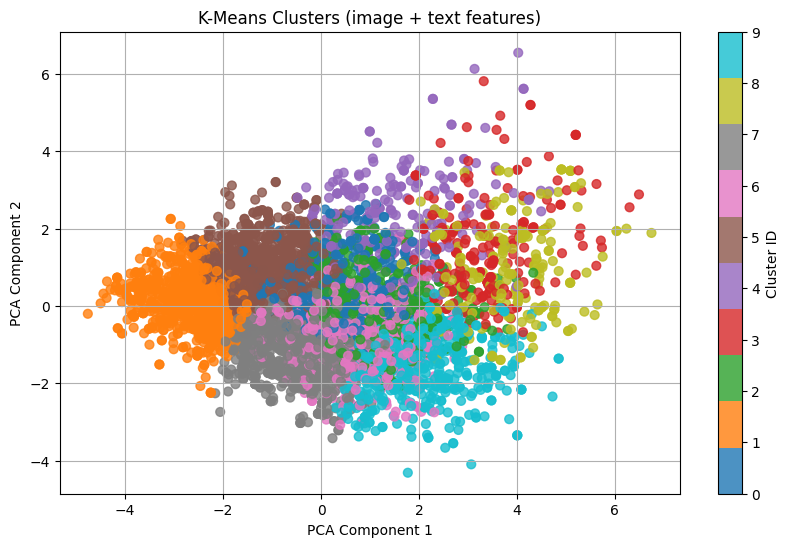

In [196]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce to 2D
plot_vec = PCA(n_components=2).fit_transform(combined_vec)

kmeans_labels = df_filtered['cluster_label'].to_numpy()

# Plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(plot_vec[:, 0], plot_vec[:, 1], c=cluster_labels, cmap='tab10', s=40, alpha=0.8)
plt.title("K-Means Clusters (image + text features)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.grid(True)
plt.show()

In [197]:
score_kmeans = silhouette_score(combined_vec, kmeans_labels)
print("KMeans Silhouette Score:", round(score_kmeans, 4))

KMeans Silhouette Score: 0.031


Display the images of the first 10 clusters:

In [199]:
# Get all unique cluster IDs
all_clusters = sorted(df_filtered['cluster_label'].unique())
print(f"All cluster IDs: {all_clusters}")

# Take first 10
selected_clusters = all_clusters[:10]

All cluster IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [200]:
show_clusters_as_html(df_filtered, selected_clusters,  max_items=8)

Not good clustering. 

Try to tune the number of clusters for K-Means:

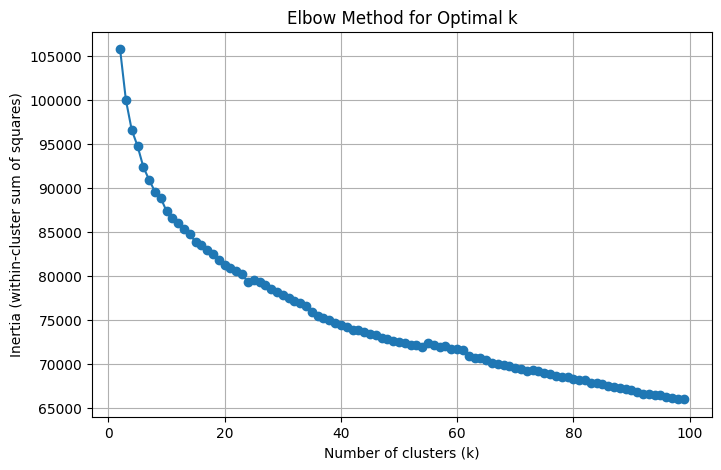

In [204]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []
k_range = range(2, 100)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(combined_vec)
    inertias.append(kmeans.inertia_)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker='o')
plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.grid(True)
plt.show()

Inertia doesn't level off.

#### **Aglomerative**

In [207]:
from sklearn.cluster import AgglomerativeClustering

# Choose number of clusters
n_clusters = 10  # You can tune this

# Fit the model
agg = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
cluster_labels = agg.fit_predict(combined_vec)

# Assign to DataFrame
df_filtered['cluster_label'] = cluster_labels

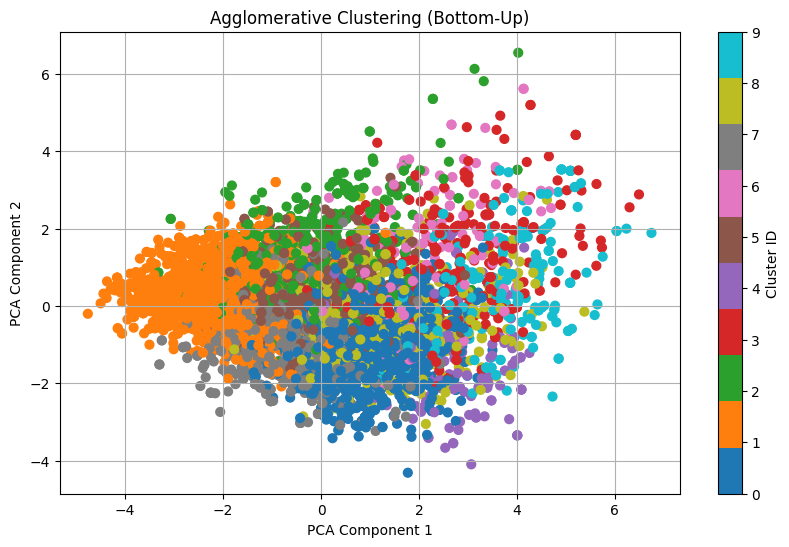

In [208]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce to 2D
plot_vec = PCA(n_components=2).fit_transform(combined_vec)

agglo_labels = df_filtered['cluster_label'].to_numpy()

plt.figure(figsize=(10, 6))
scatter = plt.scatter(plot_vec[:, 0], plot_vec[:, 1], c=cluster_labels, cmap='tab10', s=40)
plt.title("Agglomerative Clustering (Bottom-Up)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.grid(True)
plt.show()

In [209]:
score_agglo = silhouette_score(combined_vec, agglo_labels)
print("Agglomerative Clustering Silhouette Score:", round(score_agglo, 4))

Agglomerative Clustering Silhouette Score: 0.015


Display images:

In [211]:
selected_clusters = sorted(df_filtered['cluster_label'].unique())
print(f"Clusters found: {selected_clusters}")

Clusters found: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


In [212]:
show_clusters_as_html(df_filtered, selected_clusters, max_items=8)

#### **Approach 3.2:** Combine embeddings using element-wise multiplication

In [214]:
#combine the image and description (reduced) embeddings
combined_vec2 = image_vec * text_vec

#### **DBSCAN**

In [216]:
#cluster using DBSCAN

# We can tune eps and min_samples
db = DBSCAN(eps=0.5, min_samples=5, metric='euclidean')
cluster_labels = db.fit_predict(combined_vec2)

# Add cluster labels back to DataFrame
df_filtered['cluster'] = cluster_labels

# See result
print(df_filtered[['product_name', 'cluster']].head())

                                 product_name  cluster
0  Gel-rocket 11 mens volleyball/indoor shoes        0
1                          Mens filmore suede        0
2                 React vision worldwide mens        0
3                       Puma men's x-ray 3 sd        0
4                       Chuck taylor all star        0


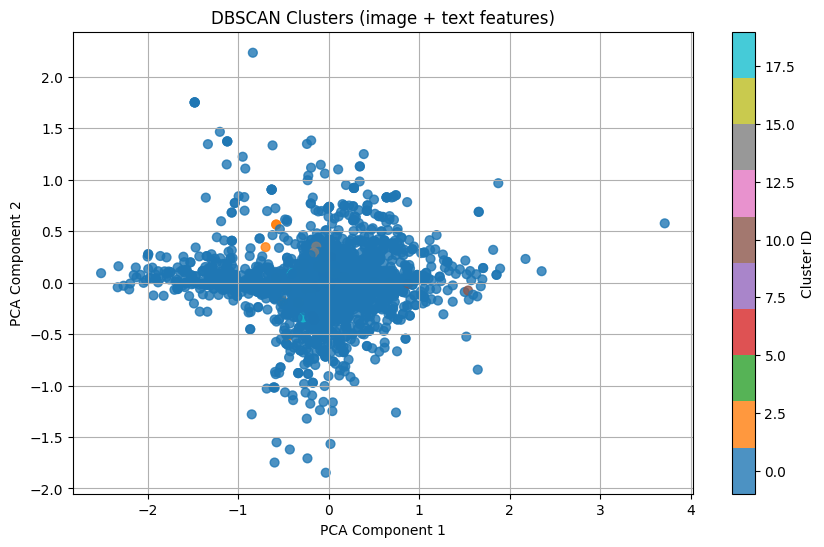

In [217]:
# Reduce to 2D for plotting
plot_embeddings = PCA(n_components=2).fit_transform(combined_vec2)

db_labels = df_filtered['cluster'].to_numpy()

# Plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(plot_embeddings[:, 0], plot_embeddings[:, 1], c=labels, cmap='tab10', s=40, alpha=0.8)
plt.title("DBSCAN Clusters (image + text features)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.grid(True)
plt.show()

In [218]:
from sklearn.metrics import silhouette_score
if len(set(db_labels)) > 1:  # silhouette score not valid if only 1 cluster
    score_dbscan = silhouette_score(combined_vec2, db_labels)
    print("DBSCAN Silhouette Score:", round(score_dbscan, 4))

DBSCAN Silhouette Score: 0.4723


With the new combined embeddings we get a much better Silhouette score.

#### **K-MEANS**

In [221]:
from sklearn.cluster import KMeans

# Choose number of clusters (you can tune this)
k = 10

# Run KMeans
kmeans = KMeans(n_clusters=k, random_state=42)
cluster_labels = kmeans.fit_predict(combined_vec2)

# Add cluster labels to DataFrame
df_filtered['cluster'] = cluster_labels

# Preview
print(df_filtered[['product_name', 'cluster']].head())

                                 product_name  cluster
0  Gel-rocket 11 mens volleyball/indoor shoes        8
1                          Mens filmore suede        8
2                 React vision worldwide mens        0
3                       Puma men's x-ray 3 sd        0
4                       Chuck taylor all star        9


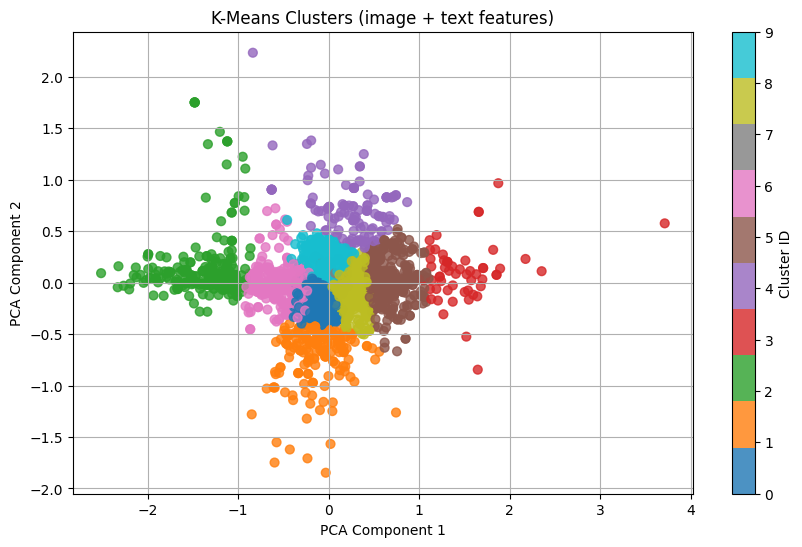

In [222]:
# Reduce to 2D
plot_vec = PCA(n_components=2).fit_transform(combined_vec2)

kmeans_labels = df_filtered['cluster'].to_numpy()

# Plot
plt.figure(figsize=(10, 6))
scatter = plt.scatter(plot_vec[:, 0], plot_vec[:, 1], c=cluster_labels, cmap='tab10', s=40, alpha=0.8)
plt.title("K-Means Clusters (image + text features)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.grid(True)
plt.show()

In [223]:
score_kmeans = silhouette_score(combined_vec2, kmeans_labels)
print("KMeans Silhouette Score:", round(score_kmeans, 4))

KMeans Silhouette Score: 0.1462


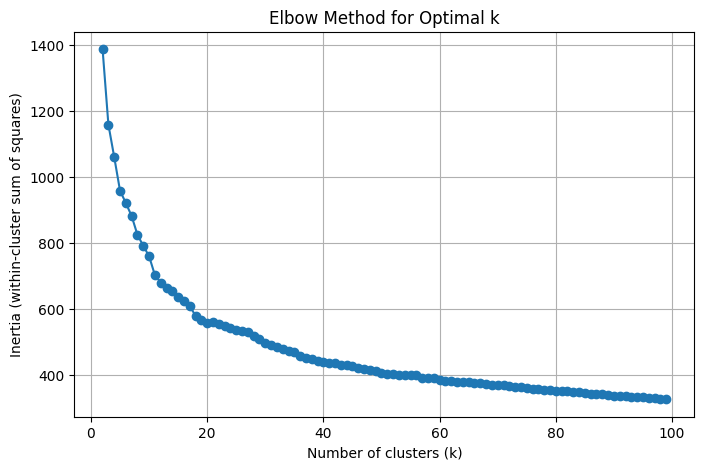

In [224]:
#try to tune number of clusters using the Elbow method

inertias = []
k_range = range(2, 100)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(combined_vec2)
    inertias.append(kmeans.inertia_)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker='o')
plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.grid(True)
plt.show()

#### **Aglomerative**

In [226]:
from sklearn.cluster import AgglomerativeClustering

# Choose number of clusters
n_clusters = 10  # You can tune this

# Fit the model
agg = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward')
cluster_labels = agg.fit_predict(combined_vec2)

# Assign to DataFrame
df_filtered['cluster'] = cluster_labels

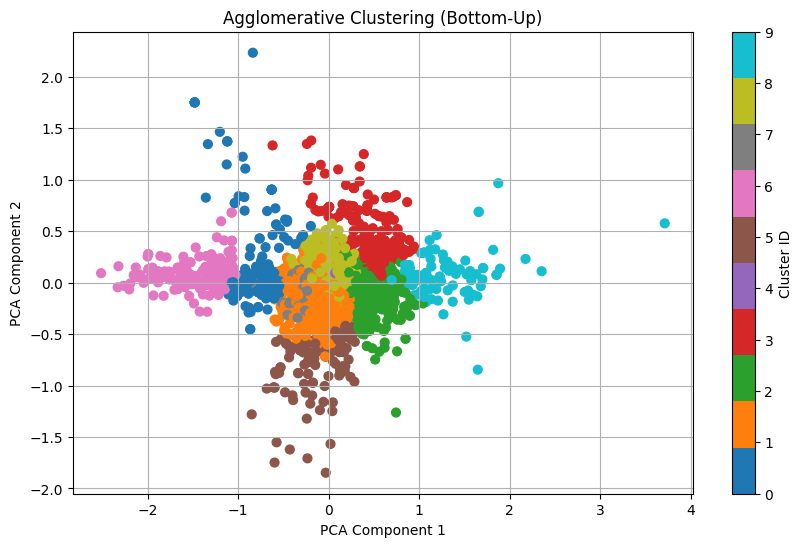

In [227]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce to 2D
plot_vec = PCA(n_components=2).fit_transform(combined_vec2)

agglo_labels = df_filtered['cluster'].to_numpy()

plt.figure(figsize=(10, 6))
scatter = plt.scatter(plot_vec[:, 0], plot_vec[:, 1], c=cluster_labels, cmap='tab10', s=40)
plt.title("Agglomerative Clustering (Bottom-Up)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label="Cluster ID")
plt.grid(True)
plt.show()

In [228]:
score_agglo = silhouette_score(combined_vec2, agglo_labels)
print("Agglomerative Clustering Silhouette Score:", round(score_agglo, 4))

Agglomerative Clustering Silhouette Score: 0.1282


In [229]:
####so combining the embeddings by multiplying leads to better clustering
#need more investigation

In [230]:
####FOR APPROAACH 4 TRY USING ONLY THE DESCRIPTION, BUT I THINK WE SHOULD DO THAT AFTER WE GET A GOOD CLUSTERING WHEN USING BOTH IMAGES AND DESCRIPTION

In [235]:
## another attempt (Evi)

Using TFIDF may be suboptimal as "Nike Air Max" ≠ "Nike Airmax", "White and Black" ≠ "Black/White", 

However, Sentence-BERT understands the meaning of the full sentence. So we may use this transformer to encode the text metadata.

In [238]:
# Install dependencies (if needed)
!pip install sentence-transformers hdbscan --quiet


In [239]:

import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict

# === Step 1: Load Data and Image Embeddings ===
df = pd.read_json('sneakers_sample_19062025.txt', lines=False)
image_vecs = np.load("image_features.npy")

# Align DataFrame to match saved image embeddings
df = df.reset_index(drop=True).iloc[:len(image_vecs)]

# === Step 2: Extract Text Metadata ===
df["description"] = df["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")
df["name"] = df["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df["brand"] = df["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df["color"] = df["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")

# === Step 3: Sentence-BERT for Text Embeddings ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")
texts = (df["name"].fillna("") + " " + df["brand"].fillna("") + " " + df["color"].fillna("") + " " + df["description"].fillna("")).tolist()
text_vecs = text_model.encode(texts, normalize_embeddings=True)

# === Step 4: Combine Vectors by Concatenation ===
image_vecs = normalize(image_vecs)
alpha = 0.6  # weight emphasis for image vs text
combined_vecs = np.hstack([alpha * image_vecs, (1 - alpha) * text_vecs])
combined_vecs = normalize(combined_vecs)

# === Step 5: HDBSCAN Clustering ===
clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
df["cluster_id"] = clusterer.fit_predict(combined_vecs)

# === Step 6: Export Cluster Groups to JSON ===
groups = defaultdict(list)
for _, row in df.iterrows():
    groups[int(row["cluster_id"])].append({
        "product_id": row.get("mirakl_product_id"),
        "name": row.get("name"),
        "image": row.get("data", {}).get("mainImage", {}).get("original_url")
    })

with open("sneaker_clusters.json", "w") as f:
    json.dump(groups, f, indent=2)

print(" Clustering complete! Saved to sneaker_clusters.json.")


 Clustering complete! Saved to sneaker_clusters.json.


We may open the json file to inspect the clusters

In [241]:
# Load saved clusters
with open("sneaker_clusters.json", "r") as f:
    clusters = json.load(f)

# Print a summary
print(f"Total groups (including noise): {len(clusters)}\n")

for cluster_id, items in clusters.items():
    print(f"\n Cluster {cluster_id} — {len(items)} items")
    for item in items[:3]:  # preview first 3
        print(f"  - {item['name']} ({item['product_id']})")


Total groups (including noise): 4


 Cluster 1 — 5486 items
  - Gel-rocket 11 mens volleyball/indoor shoes (d96975c5-0bea-41f6-a4a8-fdac53f374f3)
  - Mens filmore suede (6f302b78-9a86-484e-894f-bb39220931a3)
  - React vision worldwide mens (6b010b1d-7475-44dc-ad56-502769d2e742)

 Cluster -1 — 187 items
  - Adidas response (70006973-aa9f-4176-9f38-0ba2c5a1b06f)
  - Under armour ua m phantom 1 reissue (55dc4733-2492-4798-bf4e-63c6e39817b4)
  - Vans men atwood canvas (fdd0eed9-9e05-4ca9-a832-b9cca492151d)

 Cluster 0 — 3 items
  - Cortez womens shoes (5ea92e24-5ea6-4d33-bc51-73ef7e73be6c)
  - Beverly hills polo club women’s lifestyle wedge trainer sneakers with gold detailing (b9720763-1a33-44c6-a8d2-b8151bfee3df)
  - All star cruise (3b8c07ee-252a-4227-b990-3b4131500735)

 Cluster 2 — 3 items
  - New balance (229edeab-2f66-466b-9d6d-78165a285bdf)
  - B202111 (006be3d1-32d8-4f55-9d77-6043261a6a75)
  - Reverse sneakers (22429e41-14d9-419f-beee-04c497566eaf)


In [242]:
##### skata!!!!
## shall we group by (brand and model? or just brand?) and then take the separate dataframes and use image processing on the separate groups????

## An attempt to find variants using both groupby operations and textual embeddings as well as image embeddings (only brand and category) (call this method *)

In [244]:

import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict

# === Step 1: Load full image embeddings and metadata ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)
# Flatten fields needed for grouping
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

image_vecs_all = np.load("image_features.npy")
df_data = df_data.reset_index(drop=True).iloc[:len(image_vecs_all)]  # align

# === Step 2: Define grouping keys ===
group_keys = ['brand', 'category']#, 'name [en_GB]' ] #, 'shortDescription [en_GB]']

# === Step 3: Identify identical metadata groups ===
group_sizes = df_data.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_data.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 4: Prepare sentence transformer model ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")

# === Step 5: Clustering per group ===
results_all = {}

for group_id, group_df in identical_groups.groupby("product_group_id"):
    indices = group_df.index.tolist()  # index in original df_data

    # Extract text
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Extract image vectors for this group
    img_vecs = normalize(image_vecs_all[indices])

    # Combine image + text vectors
    alpha = 0.6
    combined_vecs = np.hstack([alpha * img_vecs, (1 - alpha) * text_vecs])
    combined_vecs = normalize(combined_vecs)

    # Run HDBSCAN
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(combined_vecs)
    group_df = group_df.copy()
    group_df["cluster_id"] = labels

    # Store results as JSON structure
    grouped_json = defaultdict(list)
    for _, row in group_df.iterrows():
        grouped_json[int(row["cluster_id"])].append({
            "product_id": row.get("mirakl_product_id"),
            "name": row.get("data", {}).get("name [en_GB]", ""),
            "image": row.get("data", {}).get("mainImage", {}).get("original_url")
        })

    results_all[f"group_{group_id}"] = grouped_json

# === Step 6: Save all cluster groups (per group) ===
with open("clustered_duplicate_groups.json", "w") as f:
    json.dump(results_all, f, indent=2)

print("Done! Clustering run separately on each duplicate metadata group.")


Done! Clustering run separately on each duplicate metadata group.


## Evaluating the method above (method *)

In [246]:
# Step 7: Evaluate clustering quality (micro-averaged accuracy)

from collections import Counter

# Flatten results_all to a DataFrame of predicted clusters
flattened_results = []
for group_key, clusters in results_all.items():
    for cluster_id, items in clusters.items():
        if cluster_id == -1:
            continue  # skip noise
        for item in items:
            flattened_results.append({
                "product_id": item["product_id"],
                "predicted_cluster": f"{group_key}_cluster_{cluster_id}"
            })

cluster_df = pd.DataFrame(flattened_results)

# Merge with ground truth labels
eval_df = pd.merge(cluster_df, sample_df[["mirakl_product_id", "manual_group_id"]],
                   left_on="product_id", right_on="mirakl_product_id", how="inner")
eval_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

# Micro-averaged within-cluster accuracy
def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
    total_correct = 0
    total_items = len(df)
    for _, cluster_df in df.groupby(pred_col):
        if len(cluster_df) == 0:
            continue
        true_labels = cluster_df[true_col]
        most_common_label_count = Counter(true_labels).most_common(1)[0][1]
        total_correct += most_common_label_count
    return total_correct / total_items

# Evaluate
score = microavg_within_cluster_accuracy(eval_df)
print(f"✅ Micro-averaged within-cluster accuracy (Hybrid Clustering): {score:.3f}")


✅ Micro-averaged within-cluster accuracy (Hybrid Clustering): 0.214


## Visualising the results of method *

In [248]:
# === Load & Visualize Clusters by Group and Cluster ID ===

import json
from IPython.display import display, HTML

# Load clustered results (each metadata group clustered separately)
with open("clustered_duplicate_groups.json", "r") as f:
    clusters_by_group = json.load(f)

# Visualize clusters in notebook
def show_group_cluster(group_id, cluster_id=None, max_items=6):
    group_key = f"group_{group_id}"
    if group_key not in clusters_by_group:
        print(f" Group {group_id} not found.")
        return

    clusters = clusters_by_group[group_key]
    # FIX: don't convert keys to string
    cluster_ids = [cluster_id] if cluster_id is not None else list(clusters.keys())

    for cid in cluster_ids:
        if str(cid) not in clusters:
            print(f"  Cluster {cid} not found in {group_key}")
            continue
        items = clusters[str(cid)][:max_items]
        html = f"<h3 style='margin-top:20px'>Group {group_id} – Cluster {cid} ({len(clusters[str(cid)])} items)</h3><div style='display:flex;flex-wrap:wrap'>"
        for item in items:
            name = item.get('name', '')
            img = item.get('image', '')
            html += f"""
                <div style='margin:10px;text-align:center'>
                    <img src='{img}' width='120' style='border-radius:8px'><br>
                    <div style='max-width:120px;font-size:12px'>{name}</div>
                </div>
            """
        html += "</div>"
        display(HTML(html))

# === Example usage ===

# Show all clusters in group 0
show_group_cluster(0)

# Show only cluster 0 in group 1
show_group_cluster(1, cluster_id=0)

# Show noise in group 2
# show_group_cluster(2, cluster_id=-1)


In [249]:
# 1. Show all clusters for first 3 groups
for gid in range(3):
    show_group_cluster(gid)

# 2. Show noise cluster only
for gid in range(3):
    show_group_cluster(gid, cluster_id=-1)

# 3. Show cluster 0 where it exists
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group and "0" in clusters_by_group[gkey]:
        show_group_cluster(gid, cluster_id=0)

# 4. Show largest cluster in each group
for gid in range(3):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        largest = max(clusters_by_group[gkey].items(), key=lambda x: len(x[1]))[0]
        show_group_cluster(gid, cluster_id=int(largest))

# 5. Show all clusters that have exactly 2 items
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        for cid, items in clusters_by_group[gkey].items():
            if len(items) == 2:
                show_group_cluster(gid, cluster_id=int(cid))

Not strict enough - clusters non similar items together.

## An attempt to find variants using both groupby operations and textual embeddings as well as image embeddings (only brand and category and name en_gb)(call this method **)

In [252]:

import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict

# === Step 1: Load full image embeddings and metadata ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)
# Flatten fields needed for grouping
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

image_vecs_all = np.load("image_features.npy")
df_data = df_data.reset_index(drop=True).iloc[:len(image_vecs_all)]  # align

# === Step 2: Define grouping keys ===
group_keys = ['brand', 'category', 'name [en_GB]' ] #, 'shortDescription [en_GB]']     # including description will make it more strict!

# === Step 3: Identify identical metadata groups ===
group_sizes = df_data.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_data.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 4: Prepare sentence transformer model ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")

# === Step 5: Clustering per group ===
results_all = {}

for group_id, group_df in identical_groups.groupby("product_group_id"):
    indices = group_df.index.tolist()  # index in original df_data

    # Extract text
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Extract image vectors for this group
    img_vecs = normalize(image_vecs_all[indices])

    # Combine image + text vectors
    alpha = 0.6
    combined_vecs = np.hstack([alpha * img_vecs, (1 - alpha) * text_vecs])
    combined_vecs = normalize(combined_vecs)

    # Run HDBSCAN
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(combined_vecs)
    group_df = group_df.copy()
    group_df["cluster_id"] = labels

    # Store results as JSON structure
    grouped_json = defaultdict(list)
    for _, row in group_df.iterrows():
        grouped_json[int(row["cluster_id"])].append({
            "product_id": row.get("mirakl_product_id"),
            "name": row.get("data", {}).get("name [en_GB]", ""),
            "image": row.get("data", {}).get("mainImage", {}).get("original_url")
        })

    results_all[f"group_{group_id}"] = grouped_json

# === Step 6: Save all cluster groups (per group) ===
with open("clustered_duplicate_groups_2.json", "w") as f:
    json.dump(results_all, f, indent=2)

print("Done! Clustering run separately on each duplicate metadata group.")


Done! Clustering run separately on each duplicate metadata group.


## Evaluating method **

In [254]:
# === Step 7: Evaluate clustering accuracy ===

from collections import Counter

# 1. Flatten clustering results into a list of product_id → predicted_cluster
flattened_results = []
for group_key, clusters in results_all.items():
    for cluster_id, items in clusters.items():
        if cluster_id == -1:
            continue  # skip noise
        for item in items:
            flattened_results.append({
                "product_id": item["product_id"],
                "predicted_cluster": f"{group_key}_cluster_{cluster_id}"
            })

cluster_df = pd.DataFrame(flattened_results)

# 2. Merge with ground truth labels
# Load sample_df if not already loaded
# sample_df = pd.read_csv("your_ground_truth.csv")  # You must have this
eval_df = pd.merge(cluster_df, sample_df[["mirakl_product_id", "manual_group_id"]],
                   left_on="product_id", right_on="mirakl_product_id", how="inner")
eval_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

# 3. Micro-averaged within-cluster accuracy
def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
    total_correct = 0
    total_items = len(df)
    for _, cluster_df in df.groupby(pred_col):
        if len(cluster_df) == 0:
            continue
        true_labels = cluster_df[true_col]
        most_common_label_count = Counter(true_labels).most_common(1)[0][1]
        total_correct += most_common_label_count
    return total_correct / total_items

# 4. Compute and report score
score = microavg_within_cluster_accuracy(eval_df)
print(f"✅ Micro-averaged within-cluster accuracy (Stricter Metadata Grouping): {score:.3f}")


✅ Micro-averaged within-cluster accuracy (Stricter Metadata Grouping): 1.000


## Visualising method **

In [256]:
# === Load & Visualize Clusters by Group and Cluster ID ===

import json
from IPython.display import display, HTML

# Load clustered results (each metadata group clustered separately)
with open("clustered_duplicate_groups_2.json", "r") as f:
    clusters_by_group = json.load(f)

# Visualize clusters in notebook
def show_group_cluster(group_id, cluster_id=None, max_items=6):
    group_key = f"group_{group_id}"
    if group_key not in clusters_by_group:
        print(f" Group {group_id} not found.")
        return

    clusters = clusters_by_group[group_key]
    # FIX: don't convert keys to string
    cluster_ids = [cluster_id] if cluster_id is not None else list(clusters.keys())

    for cid in cluster_ids:
        if str(cid) not in clusters:
            print(f"  Cluster {cid} not found in {group_key}")
            continue
        items = clusters[str(cid)][:max_items]
        html = f"<h3 style='margin-top:20px'>Group {group_id} – Cluster {cid} ({len(clusters[str(cid)])} items)</h3><div style='display:flex;flex-wrap:wrap'>"
        for item in items:
            name = item.get('name', '')
            img = item.get('image', '')
            html += f"""
                <div style='margin:10px;text-align:center'>
                    <img src='{img}' width='120' style='border-radius:8px'><br>
                    <div style='max-width:120px;font-size:12px'>{name}</div>
                </div>
            """
        html += "</div>"
        display(HTML(html))

# === Example usage ===

# Show all clusters in group 0
show_group_cluster(0)

# Show only cluster 0 in group 1
show_group_cluster(1, cluster_id=0)

# Show noise in group 2
# show_group_cluster(2, cluster_id=-1)


  Cluster 0 not found in group_1


In [257]:
# 1. Show all clusters for first 3 groups
for gid in range(3):
    show_group_cluster(gid)

# 2. Show noise cluster only
for gid in range(3):
    show_group_cluster(gid, cluster_id=-1)

# 3. Show cluster 0 where it exists
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group and "0" in clusters_by_group[gkey]:
        show_group_cluster(gid, cluster_id=0)

# 4. Show largest cluster in each group
for gid in range(3):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        largest = max(clusters_by_group[gkey].items(), key=lambda x: len(x[1]))[0]
        show_group_cluster(gid, cluster_id=int(largest))

# 5. Show all clusters that have exactly 2 items
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        for cid, items in clusters_by_group[gkey].items():
            if len(items) == 2:
                show_group_cluster(gid, cluster_id=int(cid))

Better now. Clusters variants

## To find identical products (instead of variants) also used color as a group key

In [260]:

import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict

# === Step 1: Load full image embeddings and metadata ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)
# Flatten fields needed for grouping
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

image_vecs_all = np.load("image_features.npy")
df_data = df_data.reset_index(drop=True).iloc[:len(image_vecs_all)]  # align

# === Step 2: Define grouping keys ===
group_keys = ['color', 'brand', 'category', 'name [en_GB]' ] #, 'shortDescription [en_GB]']     # including description will make it more strict!

# === Step 3: Identify identical metadata groups ===
group_sizes = df_data.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_data.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 4: Prepare sentence transformer model ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")

# === Step 5: Clustering per group ===
results_all = {}

for group_id, group_df in identical_groups.groupby("product_group_id"):
    indices = group_df.index.tolist()  # index in original df_data

    # Extract text
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Extract image vectors for this group
    img_vecs = normalize(image_vecs_all[indices])

    # Combine image + text vectors
    alpha = 0.6
    combined_vecs = np.hstack([alpha * img_vecs, (1 - alpha) * text_vecs])
    combined_vecs = normalize(combined_vecs)

    # Run HDBSCAN
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(combined_vecs)
    group_df = group_df.copy()
    group_df["cluster_id"] = labels

    # Store results as JSON structure
    grouped_json = defaultdict(list)
    for _, row in group_df.iterrows():
        grouped_json[int(row["cluster_id"])].append({
            "product_id": row.get("mirakl_product_id"),
            "name": row.get("data", {}).get("name [en_GB]", ""),
            "image": row.get("data", {}).get("mainImage", {}).get("original_url")
        })

    results_all[f"group_{group_id}"] = grouped_json

# === Step 6: Save all cluster groups (per group) ===
with open("identical_groups.json", "w") as f:
    json.dump(results_all, f, indent=2)

print("Done! Clustering run separately on each duplicate metadata group.")


Done! Clustering run separately on each duplicate metadata group.


In [261]:
# === Load & Visualize Clusters by Group and Cluster ID ===

import json
from IPython.display import display, HTML

# Load clustered results (each metadata group clustered separately)
with open("identical_groups.json", "r") as f:
    clusters_by_group = json.load(f)

# Visualize clusters in notebook
def show_group_cluster(group_id, cluster_id=None, max_items=6):
    group_key = f"group_{group_id}"
    if group_key not in clusters_by_group:
        print(f" Group {group_id} not found.")
        return

    clusters = clusters_by_group[group_key]
    # FIX: don't convert keys to string
    cluster_ids = [cluster_id] if cluster_id is not None else list(clusters.keys())

    for cid in cluster_ids:
        if str(cid) not in clusters:
            print(f"  Cluster {cid} not found in {group_key}")
            continue
        items = clusters[str(cid)][:max_items]
        html = f"<h3 style='margin-top:20px'>Group {group_id} – Cluster {cid} ({len(clusters[str(cid)])} items)</h3><div style='display:flex;flex-wrap:wrap'>"
        for item in items:
            name = item.get('name', '')
            img = item.get('image', '')
            html += f"""
                <div style='margin:10px;text-align:center'>
                    <img src='{img}' width='120' style='border-radius:8px'><br>
                    <div style='max-width:120px;font-size:12px'>{name}</div>
                </div>
            """
        html += "</div>"
        display(HTML(html))

# === Example usage ===

# Show all clusters in group 0
show_group_cluster(0)

# Show only cluster 0 in group 1
show_group_cluster(1, cluster_id=0)

# Show noise in group 2
# show_group_cluster(2, cluster_id=-1)


  Cluster 0 not found in group_1


In [262]:
# 1. Show all clusters for first 3 groups
for gid in range(3):
    show_group_cluster(gid)

# 2. Show noise cluster only
for gid in range(3):
    show_group_cluster(gid, cluster_id=-1)

# 3. Show cluster 0 where it exists
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group and "0" in clusters_by_group[gkey]:
        show_group_cluster(gid, cluster_id=0)

# 4. Show largest cluster in each group
for gid in range(3):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        largest = max(clusters_by_group[gkey].items(), key=lambda x: len(x[1]))[0]
        show_group_cluster(gid, cluster_id=int(largest))

# 5. Show all clusters that have exactly 2 items
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        for cid, items in clusters_by_group[gkey].items():
            if len(items) == 2:
                show_group_cluster(gid, cluster_id=int(cid))

In [263]:
# even better ... ladies i want your opinion: na valoume description or not? i suppose it would reduce false matches!

## Comparing this to using no images - just text metadata embeddings (identical products, include colour as a group key)

In [265]:
import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict
from IPython.display import display, HTML

# === Step 1: Load metadata ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)

# Flatten fields for grouping and processing
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

# === Step 2: Group by metadata keys (excluding image info) ===
group_keys = ['color', 'brand', 'category', 'name [en_GB]']
group_sizes = df_data.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_data.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 3: Prepare sentence transformer ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")

# === Step 4: Cluster text-only features per group ===
results_all = {}

for group_id, group_df in identical_groups.groupby("product_group_id"):
    # Extract text
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Cluster text embeddings
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(text_vecs)
    group_df = group_df.copy()
    group_df["cluster_id"] = labels

    # Save clusters as JSON
    grouped_json = defaultdict(list)
    for _, row in group_df.iterrows():
        grouped_json[int(row["cluster_id"])].append({
            "product_id": row.get("mirakl_product_id"),
            "name": row.get("data", {}).get("name [en_GB]", ""),
            "image": row.get("data", {}).get("mainImage", {}).get("original_url")
        })

    results_all[f"group_{group_id}"] = grouped_json

# === Step 5: Save results ===
with open("text_only_clustered_groups.json", "w") as f:
    json.dump(results_all, f, indent=2)

print("Text-only clustering complete!")

# === Step 6: Visualize results ===
with open("text_only_clustered_groups.json", "r") as f:
    clusters_by_group = json.load(f)

def show_group_cluster(group_id, cluster_id=None, max_items=6):
    group_key = f"group_{group_id}"
    if group_key not in clusters_by_group:
        print(f" Group {group_id} not found.")
        return

    clusters = clusters_by_group[group_key]
    cluster_ids = [cluster_id] if cluster_id is not None else list(clusters.keys())

    for cid in cluster_ids:
        if str(cid) not in clusters:
            print(f"  Cluster {cid} not found in {group_key}")
            continue
        items = clusters[str(cid)][:max_items]
        html = f"<h3 style='margin-top:20px'>Group {group_id} – Cluster {cid} ({len(clusters[str(cid)])} items)</h3><div style='display:flex;flex-wrap:wrap'>"
        for item in items:
            name = item.get('name', '')
            img = item.get('image', '')
            html += f"""
                <div style='margin:10px;text-align:center'>
                    <img src='{img}' width='120' style='border-radius:8px'><br>
                    <div style='max-width:120px;font-size:12px'>{name}</div>
                </div>
            """
        html += "</div>"
        display(HTML(html))

# === Example usage ===
show_group_cluster(0)
show_group_cluster(1, cluster_id=0)


Text-only clustering complete!


  Cluster 0 not found in group_1


## Evaluating this method

In [267]:
# Step 1: Flatten clusters
flattened = []
for group_key, clusters in clusters_by_group.items():
    for cluster_id, items in clusters.items():
        if str(cluster_id) == "-1":
            continue
        for item in items:
            pid = item.get("product_id")
            if pid:
                flattened.append({
                    "product_id": pid,
                    "predicted_cluster": f"{group_key}_cluster_{cluster_id}"
                })

cluster_df = pd.DataFrame(flattened)

# Step 2: If empty, stop here
if cluster_df.empty:
    print("⚠️ No non-noise clusters found. Check HDBSCAN min_cluster_size or vector quality.")
else:
    print(f"✅ Flattened predicted clusters: {len(cluster_df)} rows")

    # Step 3: Merge and evaluate (same as before)
    eval_df = pd.merge(
        cluster_df,
        sample_df[["mirakl_product_id", "manual_group_id"]],
        left_on="product_id",
        right_on="mirakl_product_id",
        how="inner"
    ).copy()
    eval_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

    print(f"✅ Matched ground truth samples: {len(eval_df)} / {len(sample_df)}")

    # Accuracy functions...


⚠️ No non-noise clusters found. Check HDBSCAN min_cluster_size or vector quality.


### This means this algorithm is too "strict" - only gives noise

## Visualising this method

In [270]:
# === Visualize lots of clusters ===

# Show all clusters for first 5 groups
for gid in range(5):
    show_group_cluster(gid)

# Show noise cluster (-1) for first 5 groups
for gid in range(5):
    show_group_cluster(gid, cluster_id=-1)

# Show cluster 0 where it exists
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group and "0" in clusters_by_group[gkey]:
        show_group_cluster(gid, cluster_id=0)

# Show largest cluster in each of the first 10 groups
for gid in range(10):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        largest = max(clusters_by_group[gkey].items(), key=lambda x: len(x[1]))[0]
        show_group_cluster(gid, cluster_id=int(largest))

# Show all clusters that have exactly 2 items
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        for cid, items in clusters_by_group[gkey].items():
            if len(items) == 2:
                show_group_cluster(gid, cluster_id=int(cid))


In [271]:
# 1. Show all clusters for first 3 groups
for gid in range(3):
    show_group_cluster(gid)

# 2. Show noise cluster only
for gid in range(3):
    show_group_cluster(gid, cluster_id=-1)

# 3. Show cluster 0 where it exists
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group and "0" in clusters_by_group[gkey]:
        show_group_cluster(gid, cluster_id=0)

# 4. Show largest cluster in each group
for gid in range(3):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        largest = max(clusters_by_group[gkey].items(), key=lambda x: len(x[1]))[0]
        show_group_cluster(gid, cluster_id=int(largest))

# 5. Show all clusters that have exactly 2 items
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        for cid, items in clusters_by_group[gkey].items():
            if len(items) == 2:
                show_group_cluster(gid, cluster_id=int(cid))

## Comparing this to using no images - just text metadata embeddings (finding variants - do not include colour as a group key)

In [273]:
import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict
from IPython.display import display, HTML

# === Step 1: Load metadata ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)

# Flatten fields for grouping and processing
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

# === Step 2: Group by metadata keys (excluding image info) ===
group_keys = ['brand', 'category', 'name [en_GB]']
group_sizes = df_data.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_data.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 3: Prepare sentence transformer ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")

# === Step 4: Cluster text-only features per group ===
results_all = {}

for group_id, group_df in identical_groups.groupby("product_group_id"):
    # Extract text
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Cluster text embeddings
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(text_vecs)
    group_df = group_df.copy()
    group_df["cluster_id"] = labels

    # Save clusters as JSON
    grouped_json = defaultdict(list)
    for _, row in group_df.iterrows():
        grouped_json[int(row["cluster_id"])].append({
            "product_id": row.get("mirakl_product_id"),
            "name": row.get("data", {}).get("name [en_GB]", ""),
            "image": row.get("data", {}).get("mainImage", {}).get("original_url")
        })

    results_all[f"group_{group_id}"] = grouped_json

# === Step 5: Save results ===
with open("text_only_clustered_groups_2.json", "w") as f:
    json.dump(results_all, f, indent=2)

print("Text-only clustering complete!")

# === Step 6: Visualize results ===
with open("text_only_clustered_groups_2.json", "r") as f:
    clusters_by_group = json.load(f)

def show_group_cluster(group_id, cluster_id=None, max_items=6):
    group_key = f"group_{group_id}"
    if group_key not in clusters_by_group:
        print(f" Group {group_id} not found.")
        return

    clusters = clusters_by_group[group_key]
    cluster_ids = [cluster_id] if cluster_id is not None else list(clusters.keys())

    for cid in cluster_ids:
        if str(cid) not in clusters:
            print(f"  Cluster {cid} not found in {group_key}")
            continue
        items = clusters[str(cid)][:max_items]
        html = f"<h3 style='margin-top:20px'>Group {group_id} – Cluster {cid} ({len(clusters[str(cid)])} items)</h3><div style='display:flex;flex-wrap:wrap'>"
        for item in items:
            name = item.get('name', '')
            img = item.get('image', '')
            html += f"""
                <div style='margin:10px;text-align:center'>
                    <img src='{img}' width='120' style='border-radius:8px'><br>
                    <div style='max-width:120px;font-size:12px'>{name}</div>
                </div>
            """
        html += "</div>"
        display(HTML(html))

# === Example usage ===
show_group_cluster(0)
show_group_cluster(1, cluster_id=0)


Text-only clustering complete!


  Cluster 0 not found in group_1


## Evaluation

In [275]:
# === Step 7: Evaluate clustering accuracy ===

import pandas as pd
from collections import Counter
import json

# Load clustering output
with open("text_only_clustered_groups_2.json", "r") as f:
    clusters_by_group = json.load(f)

# Flatten predicted clusters
flattened = []
for group_key, clusters in clusters_by_group.items():
    for cluster_id, items in clusters.items():
        if str(cluster_id) == "-1":
            continue  # skip noise
        for item in items:
            pid = item.get("product_id")
            if pid:
                flattened.append({
                    "product_id": pid,
                    "predicted_cluster": f"{group_key}_cluster_{cluster_id}"
                })

cluster_df = pd.DataFrame(flattened)

# If nothing clustered (all noise), stop early
if cluster_df.empty:
    print("⚠️ No non-noise clusters found. Check HDBSCAN settings or text embedding quality.")
else:
    print(f"✅ Flattened predicted clusters: {len(cluster_df)} rows")

    # === Load ground truth ===
    # sample_df = pd.read_csv("sample_ground_truth.csv")  # if not already loaded
    required_cols = {"mirakl_product_id", "manual_group_id"}
    if not required_cols.issubset(sample_df.columns):
        raise ValueError(f"sample_df must contain columns: {required_cols}")

    # === Merge predictions with true labels ===
    eval_df = pd.merge(
        cluster_df,
        sample_df[["mirakl_product_id", "manual_group_id"]],
        left_on="product_id",
        right_on="mirakl_product_id",
        how="inner"
    ).copy()
    eval_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

    print(f"✅ Matched ground truth samples: {len(eval_df)} / {len(sample_df)}")

    # === Define evaluation metrics ===
    def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
        total_correct = 0
        total_items = len(df)
        for _, cdf in df.groupby(pred_col):
            most_common = Counter(cdf[true_col]).most_common(1)[0][1]
            total_correct += most_common
        return total_correct / total_items if total_items else float("nan")

    def average_per_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
        accuracies = []
        for _, cdf in df.groupby(pred_col):
            total = len(cdf)
            if total == 0:
                continue
            most_common = Counter(cdf[true_col]).most_common(1)[0][1]
            accuracies.append(most_common / total)
        return sum(accuracies) / len(accuracies) if accuracies else float("nan")

    # === Report results ===
    micro_score = microavg_within_cluster_accuracy(eval_df)
    avg_score = average_per_cluster_accuracy(eval_df)

    print(f"\n📊 Evaluation Results (Text-only Clustering – Metadata Grouping + SentenceTransformer)")
    print(f"✅ Micro-averaged within-cluster accuracy: {micro_score:.3f}")
    print(f"✅ Average per-cluster accuracy (cluster purity): {avg_score:.3f}")


✅ Flattened predicted clusters: 283 rows
✅ Matched ground truth samples: 35 / 947

📊 Evaluation Results (Text-only Clustering – Metadata Grouping + SentenceTransformer)
✅ Micro-averaged within-cluster accuracy: 1.000
✅ Average per-cluster accuracy (cluster purity): 1.000


## Visualising the method

In [277]:
# === Load & Visualize Clusters by Group and Cluster ID ===

import json
from IPython.display import display, HTML

# Load clustered results (each metadata group clustered separately)
with open("text_only_clustered_groups_2.json", "r") as f:
    clusters_by_group = json.load(f)

# Visualize clusters in notebook
def show_group_cluster(group_id, cluster_id=None, max_items=6):
    group_key = f"group_{group_id}"
    if group_key not in clusters_by_group:
        print(f" Group {group_id} not found.")
        return

    clusters = clusters_by_group[group_key]
    # FIX: don't convert keys to string
    cluster_ids = [cluster_id] if cluster_id is not None else list(clusters.keys())

    for cid in cluster_ids:
        if str(cid) not in clusters:
            print(f"  Cluster {cid} not found in {group_key}")
            continue
        items = clusters[str(cid)][:max_items]
        html = f"<h3 style='margin-top:20px'>Group {group_id} – Cluster {cid} ({len(clusters[str(cid)])} items)</h3><div style='display:flex;flex-wrap:wrap'>"
        for item in items:
            name = item.get('name', '')
            img = item.get('image', '')
            html += f"""
                <div style='margin:10px;text-align:center'>
                    <img src='{img}' width='120' style='border-radius:8px'><br>
                    <div style='max-width:120px;font-size:12px'>{name}</div>
                </div>
            """
        html += "</div>"
        display(HTML(html))



In [278]:
# 1. Show all clusters for first 3 groups
for gid in range(3):
    show_group_cluster(gid)

# 2. Show noise cluster only
for gid in range(3):
    show_group_cluster(gid, cluster_id=-1)

# 3. Show cluster 0 where it exists
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group and "0" in clusters_by_group[gkey]:
        show_group_cluster(gid, cluster_id=0)

# 4. Show largest cluster in each group
for gid in range(3):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        largest = max(clusters_by_group[gkey].items(), key=lambda x: len(x[1]))[0]
        show_group_cluster(gid, cluster_id=int(largest))

# 5. Show all clusters that have exactly 2 items
for gid in range(len(clusters_by_group)):
    gkey = f"group_{gid}"
    if gkey in clusters_by_group:
        for cid, items in clusters_by_group[gkey].items():
            if len(items) == 2:
                show_group_cluster(gid, cluster_id=int(cid))

## Comparing this to using no images - just text metadata embeddings (finding variants - do not include colour as a group key) - but this time excluding  nameen_gb as a group key

In [280]:
import numpy as np
import pandas as pd
import json
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import normalize
import hdbscan
from collections import defaultdict
from IPython.display import display, HTML

# === Step 1: Load metadata ===
df_data = pd.read_json("sneakers_sample_19062025.txt", lines=False)

# Flatten fields for grouping and processing
df_data["brand"] = df_data["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_data["color"] = df_data["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_data["category"] = df_data["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_data["name [en_GB]"] = df_data["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_data["shortDescription [en_GB]"] = df_data["data"].apply(lambda x: x.get("shortDescription") if isinstance(x, dict) else "")

# === Step 2: Group by metadata keys (excluding image info) ===
group_keys = ['brand', 'category']
group_sizes = df_data.groupby(group_keys).size().reset_index(name='count')
duplicates = group_sizes[group_sizes["count"] > 1]
identical_groups = df_data.merge(duplicates[group_keys], on=group_keys, how="inner")
identical_groups["product_group_id"] = identical_groups.groupby(group_keys).ngroup()

# === Step 3: Prepare sentence transformer ===
text_model = SentenceTransformer("all-MiniLM-L6-v2")

# === Step 4: Cluster text-only features per group ===
results_all = {}

for group_id, group_df in identical_groups.groupby("product_group_id"):
    # Extract text
    names = group_df["data"].apply(lambda x: x.get("name [en_GB]", "") if isinstance(x, dict) else "")
    brands = group_df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
    colors = group_df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
    descriptions = group_df["data"].apply(lambda x: x.get("shortDescription", "") if isinstance(x, dict) else "")
    texts = (names + " " + brands + " " + colors + " " + descriptions).fillna("").tolist()
    text_vecs = text_model.encode(texts, normalize_embeddings=True)

    # Cluster text embeddings
    clusterer = hdbscan.HDBSCAN(min_cluster_size=2, metric='euclidean')
    labels = clusterer.fit_predict(text_vecs)
    group_df = group_df.copy()
    group_df["cluster_id"] = labels

    # Save clusters as JSON
    grouped_json = defaultdict(list)
    for _, row in group_df.iterrows():
        grouped_json[int(row["cluster_id"])].append({
            "product_id": row.get("mirakl_product_id"),
            "name": row.get("data", {}).get("name [en_GB]", ""),
            "image": row.get("data", {}).get("mainImage", {}).get("original_url")
        })

    results_all[f"group_{group_id}"] = grouped_json

# === Step 5: Save results ===
with open("text_only_clustered_groups_3.json", "w") as f:
    json.dump(results_all, f, indent=2)

print("Text-only clustering complete!")

# === Step 6: Visualize results ===
with open("text_only_clustered_groups_3.json", "r") as f:
    clusters_by_group = json.load(f)

def show_group_cluster(group_id, cluster_id=None, max_items=6):
    group_key = f"group_{group_id}"
    if group_key not in clusters_by_group:
        print(f" Group {group_id} not found.")
        return

    clusters = clusters_by_group[group_key]
    cluster_ids = [cluster_id] if cluster_id is not None else list(clusters.keys())

    for cid in cluster_ids:
        if str(cid) not in clusters:
            print(f"  Cluster {cid} not found in {group_key}")
            continue
        items = clusters[str(cid)][:max_items]
        html = f"<h3 style='margin-top:20px'>Group {group_id} – Cluster {cid} ({len(clusters[str(cid)])} items)</h3><div style='display:flex;flex-wrap:wrap'>"
        for item in items:
            name = item.get('name', '')
            img = item.get('image', '')
            html += f"""
                <div style='margin:10px;text-align:center'>
                    <img src='{img}' width='120' style='border-radius:8px'><br>
                    <div style='max-width:120px;font-size:12px'>{name}</div>
                </div>
            """
        html += "</div>"
        display(HTML(html))

# === Example usage ===
show_group_cluster(0)
show_group_cluster(1, cluster_id=0)


Text-only clustering complete!


## Evaluation

In [282]:
# === Step 7: Evaluate clustering performance ===

import pandas as pd
from collections import Counter
import json

# Load clustering output
with open("text_only_clustered_groups_3.json", "r") as f:
    clusters_by_group = json.load(f)

# Flatten all clusters into rows: (product_id, predicted_cluster)
flattened = []
for group_key, clusters in clusters_by_group.items():
    for cluster_id, items in clusters.items():
        if str(cluster_id) == "-1":
            continue  # skip noise
        for item in items:
            pid = item.get("product_id")
            if pid:
                flattened.append({
                    "product_id": pid,
                    "predicted_cluster": f"{group_key}_cluster_{cluster_id}"
                })

cluster_df = pd.DataFrame(flattened)

# Check if anything was clustered
if cluster_df.empty:
    print("⚠️ No non-noise clusters found. Clustering might be too strict or vectors too similar.")
else:
    print(f"✅ Flattened predicted clusters: {len(cluster_df)} rows")

    # === Load or verify ground truth ===
    # sample_df = pd.read_csv("your_ground_truth.csv")  # Uncomment if not in memory

    required_cols = {"mirakl_product_id", "manual_group_id"}
    if not required_cols.issubset(sample_df.columns):
        raise ValueError(f"sample_df must contain columns: {required_cols}")

    # === Merge predicted clusters with true group labels ===
    eval_df = pd.merge(
        cluster_df,
        sample_df[["mirakl_product_id", "manual_group_id"]],
        left_on="product_id",
        right_on="mirakl_product_id",
        how="inner"
    ).copy()
    eval_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

    print(f"✅ Matched ground truth samples: {len(eval_df)} / {len(sample_df)}")

    # === Evaluation metrics ===
    def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
        total_correct = 0
        total_items = len(df)
        for _, cdf in df.groupby(pred_col):
            most_common = Counter(cdf[true_col]).most_common(1)[0][1]
            total_correct += most_common
        return total_correct / total_items if total_items else float("nan")

    def average_per_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
        accuracies = []
        for _, cdf in df.groupby(pred_col):
            total = len(cdf)
            if total == 0:
                continue
            most_common = Counter(cdf[true_col]).most_common(1)[0][1]
            accuracies.append(most_common / total)
        return sum(accuracies) / len(accuracies) if accuracies else float("nan")

    # === Report results ===
    micro_score = microavg_within_cluster_accuracy(eval_df)
    avg_score = average_per_cluster_accuracy(eval_df)

    print(f"\n📊 Evaluation Results (Text-only Clustering – Brand+Category Grouping)")
    print(f"✅ Micro-averaged within-cluster accuracy: {micro_score:.3f}")
    print(f"✅ Average per-cluster accuracy (cluster purity): {avg_score:.3f}")


✅ Flattened predicted clusters: 3497 rows
✅ Matched ground truth samples: 566 / 947

📊 Evaluation Results (Text-only Clustering – Brand+Category Grouping)
✅ Micro-averaged within-cluster accuracy: 0.896
✅ Average per-cluster accuracy (cluster purity): 0.947


In [288]:
#### EVALUATION FUNCTION - elina

In [289]:
# sneaker_clusters.json - inital use of sentence bert
# clustered_duplicate_groups.json - groupby, text, img (brand&categ)
# clustered_duplicate_groups_2.json - groupby, text, img (brand&categ&name en_gb)
# identical_groups.json - identical instead of variants, also used color as group key
# text_only_clustered_groups.json - no img- just text metadata emb (identical, incl color as group key)
# text_only_clustered_groups_2.json - no img- just text metadata emb (finding variants, not incl color as group key)
# text_only_clustered_groups_3.json - no img- just text metadata emb (finding variants, not incl color as group key, also excluding nameen_gb as a group key)

In [290]:
import os
import json
import numpy as np
import pandas as pd
from sklearn.metrics import pairwise_distances

# Load aligned embedding source
image_vecs_all = np.load("image_features.npy")
df_data = df_data.iloc[:len(image_vecs_all)]  # align with embeddings
valid_ids = df_data["mirakl_product_id"].astype(str).tolist()
id_to_index = {pid: i for i, pid in enumerate(valid_ids)}

# All files and labels
clustering_files = {
    "sneaker_clusters.json": "initial_use_of_sentence_bert",
    "clustered_duplicate_groups.json": "groupby_text_img_brand_cat",
    "clustered_duplicate_groups_2.json": "groupby_text_img_brand_cat_name",
    "identical_groups.json": "identical_grouping_with_color",
    "text_only_clustered_groups.json": "text_only_identical_with_color",
    "text_only_clustered_groups_2.json": "text_only_variants_no_color",
    "text_only_clustered_groups_3.json": "text_only_variants_no_color_no_name"
}

# Evaluate function
def evaluate_cluster_json(file_path, approach_name):
    with open(file_path) as f:
        data = json.load(f)

    results = []

    # Case 1: flat dict of clusters (e.g., sneaker_clusters.json)
    if isinstance(data, dict) and isinstance(next(iter(data.values())), list):
        for cluster_id, items in data.items():
            pids = [item["product_id"] for item in items if isinstance(item, dict) and "product_id" in item]
            matched = [id_to_index[pid] for pid in pids if pid in id_to_index]

            if not matched:
                continue

            vecs = image_vecs_all[matched]
            dist = pairwise_distances(vecs)
            avg_dist = np.mean(dist[np.triu_indices_from(dist, k=1)]) if len(matched) > 1 else 0.0

            results.append({
                "approach": approach_name,
                "group": f"cluster_{cluster_id}",
                "size": len(pids),
                "valid_ids": len(matched),
                "noise_ratio": round(1 - len(matched) / len(pids), 3),
                "avg_intra_dist": round(avg_dist, 3) if avg_dist > 0 else None
            })
        return results

    # Case 2: nested group → cluster → items
    if isinstance(data, dict):
        for group_id, cluster_dict in data.items():
            if not isinstance(cluster_dict, dict):
                continue
            for cluster_id, items in cluster_dict.items():
                cluster_name = f"{group_id}_cluster_{cluster_id}"
                pids = [item["product_id"] for item in items if isinstance(item, dict) and "product_id" in item]
                matched = [id_to_index[pid] for pid in pids if pid in id_to_index]

                if not matched:
                    continue

                vecs = image_vecs_all[matched]
                dist = pairwise_distances(vecs)
                avg_dist = np.mean(dist[np.triu_indices_from(dist, k=1)]) if len(matched) > 1 else 0.0

                results.append({
                    "approach": approach_name,
                    "group": cluster_name,
                    "size": len(pids),
                    "valid_ids": len(matched),
                    "noise_ratio": round(1 - len(matched) / len(pids), 3),
                    "avg_intra_dist": round(avg_dist, 3) if avg_dist > 0 else None,
                    "num_clusters": 1  # one row = one cluster
                })

        return results

    # Case 3: fallback
    print(f"⚠️ Unknown format in {file_path}")
    return results


# Run all evaluations
all_results = []
for fname, approach in clustering_files.items():
    print(f"🔍 Evaluating {fname}")
    try:
        all_results.extend(evaluate_cluster_json(fname, approach))
    except Exception as e:
        print(f"⚠️ Error evaluating {fname}: {e}")

# Combine and save
df_eval = pd.DataFrame(all_results)
df_eval.to_csv("clustering_evaluation_results.csv", index=False)

# Summary table
summary = df_eval.groupby("approach").agg({
    "num_clusters": "sum",
    "size": "mean",
    "valid_ids": "mean",
    "noise_ratio": "mean",
    "avg_intra_dist": "mean"
}).round(3)

display(df_eval.head(10))
display(summary)


🔍 Evaluating sneaker_clusters.json
🔍 Evaluating clustered_duplicate_groups.json
🔍 Evaluating clustered_duplicate_groups_2.json
🔍 Evaluating identical_groups.json
🔍 Evaluating text_only_clustered_groups.json
🔍 Evaluating text_only_clustered_groups_2.json
🔍 Evaluating text_only_clustered_groups_3.json


,approach,group,size,valid_ids,noise_ratio,avg_intra_dist,num_clusters
0,initial_use_of_sentence_bert,cluster_1,5486,5486,0.0,6.123,NaN
1,initial_use_of_sentence_bert,cluster_-1,187,187,0.0,10.612,NaN
2,initial_use_of_sentence_bert,cluster_0,3,3,0.0,4.985,NaN
3,initial_use_of_sentence_bert,cluster_2,3,3,0.0,0.000,NaN
4,groupby_text_img_brand_cat,group_0_cluster_-1,118,118,0.0,6.121,1.0
5,groupby_text_img_brand_cat,group_0_cluster_0,450,450,0.0,6.284,1.0
6,groupby_text_img_brand_cat,group_0_cluster_1,3,3,0.0,5.727,1.0
7,groupby_text_img_brand_cat,group_1_cluster_-1,29,29,0.0,6.663,1.0
8,groupby_text_img_brand_cat,group_1_cluster_0,5,5,0.0,6.401,1.0
9,groupby_text_img_brand_cat,group_1_cluster_1,192,192,0.0,6.556,1.0


,num_clusters,size,valid_ids,noise_ratio,avg_intra_dist
approach,,,,,
groupby_text_img_brand_cat,258.0,21.818,21.818,0.000,6.395
groupby_text_img_brand_cat_name,1194.0,2.850,2.850,0.000,6.319
identical_grouping_with_color,969.0,2.305,2.305,0.000,6.299
initial_use_of_sentence_bert,0.0,1419.750,1419.750,0.000,5.430
text_only_identical_with_color,1005.0,2.316,2.259,0.024,6.299
text_only_variants_no_color,1274.0,2.769,2.700,0.025,6.312
text_only_variants_no_color_no_name,927.0,6.223,6.072,0.025,6.305


In [291]:
# size -> Average number of products per cluster across all clusters in an approach.
# valid_ids -> Same as size, but filtered to those with valid image embeddings (in image_vecs_all).
# noise_ratio -> Proportion of items that were not included in intra-cluster distance computation (e.g., no image embeddings).
# avg_intra_dist -> Average Euclidean distance between all image embeddings within a cluster (lower is tighter).

In [292]:
# A noise_ratio of 0.0 means all product_ids in the JSON matched your image_vecs_all index (id_to_index).
# This is expected for approaches that used those exact product_ids from the dataset that was used to generate image_features.npy.
# For example, in initial_use_of_sentence_bert, every product had a corresponding image embedding.
# On the other hand, if even one product_id didn’t have an image vector, it would contribute to a non-zero noise_ratio.

### noise_ratio is only meaningful for approaches that rely on image embeddings.

# Why Noise Ratio is 0.0 for Text-only Approaches?
# That’s misleading. It should not even be computed or should be set to None for text-only approaches.

# Your current code computes it blindly for all approaches. If the IDs happen to match by chance, it'll show a value — but it's not meaningful.

In [294]:
# guys vlakies pano nomizo nothing meaningful en lali TIPOTE

In [296]:
import json
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_distances
from tqdm import tqdm

from sentence_transformers import SentenceTransformer

#text_embeddings = text_vecs # i think text embeddings same in all approaches, correct me an ime lathos
from sentence_transformers import SentenceTransformer
model = SentenceTransformer("all-MiniLM-L6-v2")

df_data["text_input"] = (
    df_data["brand"].fillna("") + " " +
    df_data["name [en_GB]"].fillna("") + " " +
    df_data["category"].fillna("") + " " +
    df_data["color"].fillna("")
)

text_embeddings = model.encode(
    df_data["text_input"].tolist(),
    batch_size=64,
    show_progress_bar=True
)

np.save("text_embeddings.npy", text_embeddings)

image_embeddings = image_features

# Map product_id to index in embeddings
product_ids = df_data["mirakl_product_id"].astype(str).tolist()
id_to_index = {pid: idx for idx, pid in enumerate(product_ids)}

# JSON cluster files and their labels
clustering_files = {
    "initial_use_of_sentence_bert": "sneaker_clusters.json",
    "groupby_text_img_brand_cat": "clustered_duplicate_groups.json",
    "groupby_text_img_brand_cat_name": "clustered_duplicate_groups_2.json",
    "identical_grouping_with_color": "identical_groups.json",
    "text_only_identical_with_color": "text_only_clustered_groups.json",
    "text_only_variants_no_color": "text_only_clustered_groups_2.json",
    "text_only_variants_no_color_no_name": "text_only_clustered_groups_3.json",
}

# What embedding type each approach used
embedding_source = {
    "initial_use_of_sentence_bert": "both",
    "groupby_text_img_brand_cat": "both",
    "groupby_text_img_brand_cat_name": "both",
    "identical_grouping_with_color": "text",
    "text_only_identical_with_color": "text",
    "text_only_variants_no_color": "text",
    "text_only_variants_no_color_no_name": "text"
}

# Helper: get the right embedding vector
def get_embedding(pid, source):
    if pid not in id_to_index:
        return None
    idx = id_to_index[pid]
    if source == "text":
        return text_embeddings[idx]
    elif source == "image":
        return image_embeddings[idx]
    elif source == "both":
        return np.concatenate([text_embeddings[idx], image_embeddings[idx]])
    return None

# Helper: compute mean pairwise distance within a cluster
def compute_cluster_consistency(embeddings):
    if len(embeddings) <= 1:
        return None
    dists = cosine_distances(embeddings)
    return np.mean(dists[np.triu_indices_from(dists, k=1)])

# Store results
all_results = []

for approach, file_name in tqdm(clustering_files.items(), desc="Evaluating clustering methods"):
    emb_type = embedding_source[approach]

    try:
        with open(file_name) as f:
            clusters = json.load(f)
    except Exception as e:
        print(f"❌ Error loading {file_name}: {e}")
        continue

    # Normalize structure: flat dict becomes single group
    if isinstance(clusters, dict) and isinstance(next(iter(clusters.values())), list):
        cluster_groups = {"group_0": clusters}
    else:
        cluster_groups = clusters

    cluster_consistencies = []

    for group_id, group_clusters in cluster_groups.items():
        if not isinstance(group_clusters, dict):
            continue
        for cluster_id, items in group_clusters.items():
            if cluster_id == "-1" or not isinstance(items, list):
                continue

            embeddings = []
            for item in items:
                pid = item.get("product_id") if isinstance(item, dict) else item
                emb = get_embedding(pid, emb_type)
                if emb is not None:
                    embeddings.append(emb)

            if len(embeddings) > 1:
                score = compute_cluster_consistency(np.array(embeddings))
                if score is not None:
                    cluster_consistencies.append(score)

    avg_score = np.mean(cluster_consistencies) if cluster_consistencies else None

    all_results.append({
        "approach": approach,
        "embedding_used": emb_type,
        "avg_intra_cluster_distance": round(avg_score, 4) if avg_score is not None else None,
        "num_clusters_evaluated": len(cluster_consistencies)
    })

# Create final DataFrame
df_consistency = pd.DataFrame(all_results).sort_values("avg_intra_cluster_distance")
print(df_consistency)


Batches:   0%|          | 0/89 [00:00<?, ?it/s]

Evaluating clustering methods: 100%|█████████████████████████████████████████████████████| 7/7 [00:01<00:00,  6.80it/s]

                              approach embedding_used  \
5          text_only_variants_no_color           text   
6  text_only_variants_no_color_no_name           text   
0         initial_use_of_sentence_bert           both   
1           groupby_text_img_brand_cat           both   
2      groupby_text_img_brand_cat_name           both   
3        identical_grouping_with_color           text   
4       text_only_identical_with_color           text   

   avg_intra_cluster_distance  num_clusters_evaluated  
5                      0.0220                      78  
6                      0.0633                     798  
0                      0.1484                       3  
1                      0.2944                     125  
2                      0.3126                      20  
3                         NaN                       0  
4                         NaN                       0  


trying to visualise the above clusters (so as to manually check afterwards)

In [298]:
## no output

In [299]:
import json
import pandas as pd
from IPython.display import display, HTML

# === Fallback image columns (adjust if needed) ===
fallback_cols = [
    "image_url", 
    "mainImage", 
    "media.main", 
    "data.mainImage.original_url"
]

# === Define clustering files ===
clustering_files = {
    "initial_use_of_sentence_bert": "sneaker_clusters.json",
    "groupby_text_img_brand_cat": "clustered_duplicate_groups.json",
    "groupby_text_img_brand_cat_name": "clustered_duplicate_groups_2.json",
    "identical_grouping_with_color": "identical_groups.json",
    "text_only_identical_with_color": "text_only_clustered_groups.json",
    "text_only_variants_no_color": "text_only_clustered_groups_2.json",
    "text_only_variants_no_color_no_name": "text_only_clustered_groups_3.json",
}

# === Embedding type metadata (optional, unused here) ===
embedding_source = {
    "initial_use_of_sentence_bert": "both",
    "groupby_text_img_brand_cat": "both",
    "groupby_text_img_brand_cat_name": "both",
    "identical_grouping_with_color": "text",
    "text_only_identical_with_color": "text",
    "text_only_variants_no_color": "text",
    "text_only_variants_no_color_no_name": "text"
}

# === Extract valid image URL from row ===
def extract_image_url(row):
    for col in fallback_cols:
        value = row.get(col)
        if isinstance(value, dict):
            # Try to get nested URL (like 'mainImage': {'original_url': ...})
            if "original_url" in value and isinstance(value["original_url"], str):
                return value["original_url"]
        elif isinstance(value, str) and value.startswith("http"):
            return value
    return ""  # fallback

# === HTML Cluster Display Function ===
def show_cluster_images(group_clusters, group_id="group_0", method="", max_items=6):
    for cluster_id, items in group_clusters.items():
        if cluster_id == "-1" or not isinstance(items, list):
            continue

        html = f"<h2 style='margin-top:30px;color:#aa00ff'>Approach: {method} – {group_id} – Cluster {cluster_id} ({len(items)} items)</h2>"
        html += "<div style='display:flex;flex-wrap:wrap;background-color:#111;padding:15px;border-radius:10px'>"

        for item in items[:max_items]:
            pid = item.get("product_id") if isinstance(item, dict) else item
            row = df_data[df_data["mirakl_product_id"].astype(str) == str(pid)]
            if row.empty:
                continue
            row = row.squeeze()

            name = row.get("name [en_GB]", "")
            img_url = extract_image_url(row)

            
            print(f"📷 {method} | PID: {pid} | URL: {img_url} | Name: {name}")

            html += f"""
                <div style='margin:10px;text-align:center;color:white'>
                    <img src="{img_url}" width="140" style="border-radius:12px;box-shadow:0 2px 8px rgba(0,0,0,0.5)'><br>
                    <div style="max-width:140px;font-size:13px;margin-top:5px">{name}</div>
                </div>
            """

        html += "</div>"
        display(HTML(html))

# === Loop through all clustering methods and visualize ===
for approach, cluster_file in clustering_files.items():
    try:
        with open(cluster_file) as f:
            clusters = json.load(f)
    except Exception as e:
        print(f"⚠️ Could not load {cluster_file}: {e}")
        continue

    # Normalize structure to: {group_id: {cluster_id: [items]}}
    if isinstance(clusters, dict) and isinstance(next(iter(clusters.values())), list):
        clusters = {"group_0": clusters}

    for group_id, group_clusters in clusters.items():
        if isinstance(group_clusters, dict):
            show_cluster_images(group_clusters, group_id, method=approach)


📷 initial_use_of_sentence_bert | PID: d96975c5-0bea-41f6-a4a8-fdac53f374f3 | URL:  | Name: Gel-rocket 11 mens volleyball/indoor shoes
📷 initial_use_of_sentence_bert | PID: 6f302b78-9a86-484e-894f-bb39220931a3 | URL:  | Name: Mens filmore suede
📷 initial_use_of_sentence_bert | PID: 6b010b1d-7475-44dc-ad56-502769d2e742 | URL:  | Name: React vision worldwide mens
📷 initial_use_of_sentence_bert | PID: cf04d217-bfd6-4743-ae4b-bc98712959ca | URL:  | Name: Puma men's x-ray 3 sd
📷 initial_use_of_sentence_bert | PID: 18f34f39-60e3-4d53-a242-33ae46446cbf | URL:  | Name: Chuck taylor all star
📷 initial_use_of_sentence_bert | PID: cafc8d82-9879-4c76-b699-dffc24f91052 | URL:  | Name: Adidas gazelle shoes


📷 initial_use_of_sentence_bert | PID: 5ea92e24-5ea6-4d33-bc51-73ef7e73be6c | URL:  | Name: Cortez womens shoes
📷 initial_use_of_sentence_bert | PID: b9720763-1a33-44c6-a8d2-b8151bfee3df | URL:  | Name: Beverly hills polo club women’s lifestyle wedge trainer sneakers with gold detailing
📷 initial_use_of_sentence_bert | PID: 3b8c07ee-252a-4227-b990-3b4131500735 | URL:  | Name: All star cruise


📷 initial_use_of_sentence_bert | PID: 229edeab-2f66-466b-9d6d-78165a285bdf | URL:  | Name: New balance
📷 initial_use_of_sentence_bert | PID: 006be3d1-32d8-4f55-9d77-6043261a6a75 | URL:  | Name: B202111
📷 initial_use_of_sentence_bert | PID: 22429e41-14d9-419f-beee-04c497566eaf | URL:  | Name: Reverse sneakers


📷 groupby_text_img_brand_cat | PID: 8224e8a2-32c2-4473-bb0d-267cb2d1f385 | URL:  | Name: Adidas men's supernova stride shoes
📷 groupby_text_img_brand_cat | PID: 5763b649-f5b5-4e5f-b38b-4fb8768beb87 | URL:  | Name: Duramo speed men
📷 groupby_text_img_brand_cat | PID: 6a7e87d7-9adf-458b-a1c8-ad25367c67ff | URL:  | Name: Cloudfoam go lounge
📷 groupby_text_img_brand_cat | PID: a40bc608-5fda-4988-b2e0-a3c172a0dcf2 | URL:  | Name: Midcity low
📷 groupby_text_img_brand_cat | PID: ab2f008d-e40f-47ec-a809-922cbd2b306a | URL:  | Name: Strutter
📷 groupby_text_img_brand_cat | PID: aab14fd9-c07b-4043-b9b1-078898c7db7a | URL:  | Name: Response super mens


📷 groupby_text_img_brand_cat | PID: 74697680-f45b-42e2-ace8-8b74a6b1ea70 | URL:  | Name: 4dfwd 2 men
📷 groupby_text_img_brand_cat | PID: 9d91b39d-e79b-4b12-8ce8-cac47b127a1d | URL:  | Name: Adidas men's trae unlimited shoes
📷 groupby_text_img_brand_cat | PID: 05933bbc-88d9-464d-a364-0bd73e17c021 | URL:  | Name: Pureboost 22 h.rdy mens


...

📷 text_only_variants_no_color_no_name | PID: 6a10c6b5-a40e-48bb-a83c-6811bb63ee00 | URL:  | Name: Veja campo chrome-free leather sneakers
📷 text_only_variants_no_color_no_name | PID: fe2c7d00-291d-4cdd-8afd-d854be30980d | URL:  | Name: Campo chrome-free leather sneakers
📷 text_only_variants_no_color_no_name | PID: 6e79068a-dcf2-46d5-bbf0-899aea587ae2 | URL:  | Name: Veja campo chrome-free leather sneakers
📷 text_only_variants_no_color_no_name | PID: eac55f56-3cc2-4b8c-8997-00fc4011b115 | URL:  | Name: Campo chrome-free leather sneakers


📷 text_only_variants_no_color_no_name | PID: eeeef18e-f1b4-4de6-9196-d58c440969fd | URL:  | Name: Volley organic leather shoes
📷 text_only_variants_no_color_no_name | PID: 89692554-52f6-49df-8637-1aacfbff6c5c | URL:  | Name: Volley organic leather shoes
📷 text_only_variants_no_color_no_name | PID: e093fac0-88fb-4a71-8f63-597742a94d44 | URL:  | Name: Volley organic leather shoes
📷 text_only_variants_no_color_no_name | PID: d3f21320-a0bc-4ae1-89a0-0ad49ae56f39 | URL:  | Name: Volley organic leather shoes
📷 text_only_variants_no_color_no_name | PID: 5927ec53-05f6-4c51-b921-8bf42ebf5dbc | URL:  | Name: Volley organic leather shoes


📷 text_only_variants_no_color_no_name | PID: 83d79b68-18f8-4cee-b26c-8805d8d81f19 | URL:  | Name: Veja campo extra leather sneakers
📷 text_only_variants_no_color_no_name | PID: 22b55663-bdd4-4b54-862a-21c2f026002a | URL:  | Name: Campo extra leather sneakers
📷 text_only_variants_no_color_no_name | PID: ee9de528-ae21-4ef1-8343-67dd62b0e039 | URL:  | Name: Veja campo extra leather sneakers


📷 text_only_variants_no_color_no_name | PID: 9d93ed79-47d6-4497-9891-dc99eae1cb15 | URL:  | Name: Via marte white and ice sneakers
📷 text_only_variants_no_color_no_name | PID: bad74ebc-8a0e-4784-a5a7-0eec83c43118 | URL:  | Name: Via marte sneakers
📷 text_only_variants_no_color_no_name | PID: 8a87c785-4193-4347-bfcd-fa80ad1bb000 | URL:  | Name: Via marte wedge white sneakers
📷 text_only_variants_no_color_no_name | PID: b7b047af-9fd6-44a5-a5e3-8f5803e774ac | URL:  | Name: Via marte sneakers
📷 text_only_variants_no_color_no_name | PID: ea78592e-e732-43e5-8979-dabc2746c4a5 | URL:  | Name: Via marte white with gold sneakers
📷 text_only_variants_no_color_no_name | PID: 13f9ec08-cc8c-4624-a7f4-7d94cc340471 | URL:  | Name: Via marte sneakers


📷 text_only_variants_no_color_no_name | PID: 065a2c08-009b-4fe7-a125-42c490c45e9a | URL:  | Name: Via marte black wedge sneakers
📷 text_only_variants_no_color_no_name | PID: 1d7a008c-e925-4df5-ac42-70b92b72f339 | URL:  | Name: Via marte black sneakers
📷 text_only_variants_no_color_no_name | PID: 7477a6ab-a084-49dc-a236-6554cabd6d41 | URL:  | Name: Via marte black sneakers


In [300]:
### need to verify this is what we aim to do and run


In [301]:
from collections import Counter
import pandas as pd

def microavg_within_cluster_accuracy(df, true_col="true_group", pred_col="predicted_cluster"):
    total_correct = 0
    total_items = len(df)

    for _, cluster_df in df.groupby(pred_col):
        if len(cluster_df) == 0:
            continue
        true_labels = cluster_df[true_col]
        most_common_label_count = Counter(true_labels).most_common(1)[0][1]
        total_correct += most_common_label_count

    return total_correct / total_items

In [302]:
merged_df = pd.merge(predicted_df, manual_df, on="product_id", how="inner")
# predicted_df must have `predicted_cluster`; manual_df must have `manual_group_id` (rename to true_group)
merged_df.rename(columns={"manual_group_id": "true_group"}, inplace=True)

score = microavg_within_cluster_accuracy(merged_df, true_col="true_group", pred_col="predicted_cluster")
print(f"Micro-averaged within-cluster accuracy: {score:.3f}")

Micro-averaged within-cluster accuracy: 0.093


# Task 3: Feature extraction from product images.

Using Logistic Regression

In [311]:
!pip install torch torchvision pillow

In [ ]:
import numpy as np
import pandas as pd
import json
import os
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# === Step 1: Load metadata ===
df = pd.read_json("sneakers_sample_19062025.txt", lines=False)
df["brand"] = df["data"].apply(lambda x: x.get("brand", "") if isinstance(x, dict) else "")
df["color"] = df["data"].apply(lambda x: x.get("color", "") if isinstance(x, dict) else "")
df["category"] = df["data"].apply(lambda x: x.get("category", "") if isinstance(x, dict) else "")
df["image_url"] = df["data"].apply(lambda x: x.get("mainImage", {}).get("original_url") if isinstance(x, dict) else "")
df = df.dropna(subset=["image_url"]).reset_index(drop=True)

# === Step 2: Download & preprocess a few images ===
from PIL import Image
import requests
from io import BytesIO

def load_and_preprocess_image(url):
    try:
        response = requests.get(url, timeout=10)
        img = load_img(BytesIO(response.content), target_size=(224, 224))
        img_array = img_to_array(img)
        return preprocess_input(img_array)
    except:
        return None

# Keep only rows we can fetch
image_arrays = []
valid_indices = []

for i, row in tqdm(df.iterrows(), total=len(df)):
    arr = load_and_preprocess_image(row["image_url"])
    if arr is not None:
        image_arrays.append(arr)
        valid_indices.append(i)

df = df.iloc[valid_indices].reset_index(drop=True)
X_images = np.array(image_arrays)

# === Step 3: Extract features using MobileNetV2 ===
model = MobileNetV2(weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
image_features = model.predict(X_images, batch_size=32, verbose=1)

  4%|███▏                                                                           | 239/5819 [01:18<39:36,  2.35it/s]C:\Users\evich\anaconda3\Lib\site-packages\PIL\Image.py:1056: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
 12%|█████████▏                                                                     | 675/5819 [03:56<25:12,  3.40it/s]

In [ ]:
# === Step 4: Train classifiers for each label ===
def train_predict(label_name):
    print(f"\n🔎 Predicting: {label_name}")
    y = df[label_name]
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)

    X_train, X_test, y_train, y_test = train_test_split(image_features, y_encoded, test_size=0.2, random_state=42)
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    acc = accuracy_score(y_test, preds)
    print(f"✅ Accuracy for '{label_name}': {acc:.4f}")
    return clf, le

# Train for brand, color, category
brand_clf, brand_encoder = train_predict("brand")
color_clf, color_encoder = train_predict("color")
category_clf, category_encoder = train_predict("category")

Random Forest and LightGBM

In [ ]:
from sklearn.ensemble import RandomForestClassifier

def train_predict_rf(label_name):
    print(f"\n🌲 Random Forest – Predicting: {label_name}")
    y = df[label_name]
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)

    X_train, X_test, y_train, y_test = train_test_split(image_features, y_encoded, test_size=0.2, random_state=42)
    clf = RandomForestClassifier(n_estimators=100, random_state=42)
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    acc = accuracy_score(y_test, preds)
    print(f"✅ Accuracy for '{label_name}' (RF): {acc:.4f}")
    return clf, le

# Train for brand, color, category
brand_rf_clf, brand_rf_enc = train_predict_rf("brand")
color_rf_clf, color_rf_enc = train_predict_rf("color")
category_rf_clf, category_rf_enc = train_predict_rf("category")


In [ ]:
from lightgbm import LGBMClassifier

def train_predict_lgbm(label_name):
    print(f"\n💡 LightGBM – Predicting: {label_name}")
    y = df[label_name]
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)

    X_train, X_test, y_train, y_test = train_test_split(image_features, y_encoded, test_size=0.2, random_state=42)
    clf = LGBMClassifier(n_estimators=100, random_state=42, verbose = -1)  # verbose = -1 to avoid warnings!
    clf.fit(X_train, y_train)
    preds = clf.predict(X_test)
    acc = accuracy_score(y_test, preds)
    print(f"✅ Accuracy for '{label_name}' (LGBM): {acc:.4f}")
    return clf, le

# Train for brand, color, category
brand_lgbm_clf, brand_lgbm_enc = train_predict_lgbm("brand")
color_lgbm_clf, color_lgbm_enc = train_predict_lgbm("color")
category_lgbm_clf, category_lgbm_enc = train_predict_lgbm("category")


In [ ]:
# skata to lightgbm gia color je brand - dont know why but ok 

## Task 3 on dress data

In [ ]:
# Read data
df = pd.read_json('women_dress.json', lines=False)

print(df.head())

In [ ]:
import pandas as pd
import json

# === Step 1: Load dresses file ===
df_dresses = pd.read_json("women_dress.json", lines=False)

# === Step 2: Flatten fields like you did for sneakers ===
df_dresses["brand"] = df_dresses["data"].apply(lambda x: x.get("brand") if isinstance(x, dict) else "")
df_dresses["color"] = df_dresses["data"].apply(lambda x: x.get("color") if isinstance(x, dict) else "")
df_dresses["category"] = df_dresses["data"].apply(lambda x: x.get("category") if isinstance(x, dict) else "")
df_dresses["size"] = df_dresses["data"].apply(lambda x: x.get("size") if isinstance(x, dict) else "")
df_dresses["name [en_GB]"] = df_dresses["data"].apply(lambda x: x.get("name [en_GB]") if isinstance(x, dict) else "")
df_dresses["shortDescription [en_GB]"] = df_dresses["data"].apply(lambda x: x.get("shortDescription [en_GB]") if isinstance(x, dict) else "")
df_dresses["image"] = df_dresses["data"].apply(lambda x: x.get("mainImage", {}).get("original_url") if isinstance(x, dict) else "")

# Optional: check the first few rows
df_dresses.head()


In [ ]:
import json
import pandas as pd

# === Step 1: Load the dresses JSON file ===
with open("women_dress.json", "r", encoding="utf-8") as f:
    raw_dresses = json.load(f)

# === Step 2: Initialize lists ===
meta_rows = []
data_rows = []
sources_rows = []

# Fields to exclude from metadata
exclude_fields = {
    "creation_date", "update_date",
    "validation", "synchronization",
    "catalogs", "selling_authorization", "product_urls"
}

# === Step 3: Iterate and split fields ===
for entry in raw_dresses:
    # Top-level fields (meta)
    meta = {
        key: entry[key] for key in entry
        if key not in exclude_fields and key not in ["data", "sources"]
    }
    meta_rows.append(meta)

    # Nested 'data' dictionary
    if "data" in entry:
        data_rows.append(entry["data"])

    # Nested 'sources' list
    if "sources" in entry and isinstance(entry["sources"], list):
        for source in entry["sources"]:
            source["mirakl_product_id"] = entry.get("mirakl_product_id")
            sources_rows.append(source)

# === Step 4: Convert to DataFrames ===
df_dresses_meta = pd.DataFrame(meta_rows)
df_dresses_data = pd.json_normalize(data_rows)
df_dresses_sources = pd.DataFrame(sources_rows)

# === Step 5: Preview structure ===
print("Meta columns:", df_dresses_meta.columns.tolist())
print("Data columns:", df_dresses_data.columns.tolist())
print("Sources sample:")
display(df_dresses_sources.head())


In [ ]:
df_dresses_data

In [ ]:
df_dresses_data.columns

In [ ]:
df_dresses_data.info

In [ ]:
df_dresses_data.isna().sum()

In [ ]:
import numpy as np
import pandas as pd
import json
import os
from tqdm import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from PIL import Image
import requests
from io import BytesIO

# Assume df_dresses_data is already loaded from the previous step
# Sample 1000 rows with non-null mainImage.original_url
sample_df_dresses = df_dresses_data.dropna(subset=["mainImage.original_url"]).sample(n=5000, random_state=42).reset_index(drop=True)

# Download and preprocess images
def load_and_preprocess_image(url):
    try:
        response = requests.get(url, timeout=10)
        img = load_img(BytesIO(response.content), target_size=(224, 224))
        img_array = img_to_array(img)
        return preprocess_input(img_array)
    except:
        return None

image_arrays = []
valid_indices = []

for i, row in tqdm(sample_df_dresses.iterrows(), total=len(sample_df_dresses)):
    arr = load_and_preprocess_image(row["mainImage.original_url"])
    if arr is not None:
        image_arrays.append(arr)
        valid_indices.append(i)

df = sample_df_dresses.iloc[valid_indices].reset_index(drop=True)
X_images = np.array(image_arrays)

# Extract features using MobileNetV2
model = MobileNetV2(weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
image_features = model.predict(X_images, batch_size=32, verbose=1)



In [ ]:
# Define a general function to train and evaluate different classifiers
import lightgbm as lgb

def train_and_evaluate_models(label_name, features, df_subset):
    print(f"\n🔎 Training models to predict: {label_name}")
    
    y = df_subset[label_name].astype(str)
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)

    X_train, X_test, y_train, y_test = train_test_split(features, y_encoded, test_size=0.2, random_state=42)

    results = {}


    # Random Forest
    rf = RandomForestClassifier(n_estimators=100, random_state=42)
    rf.fit(X_train, y_train)
    rf_preds = rf.predict(X_test)
    results['random_forest'] = {
        'model': rf,
        'accuracy': accuracy_score(y_test, rf_preds),
        'report': classification_report(y_test, rf_preds, target_names=le.classes_, output_dict=True)
    }

    # LightGBM
    lgbm = lgb.LGBMClassifier(random_state=42)
    lgbm.fit(X_train, y_train)
    lgbm_preds = lgbm.predict(X_test)
    results['lightgbm'] = {
        'model': lgbm,
        'accuracy': accuracy_score(y_test, lgbm_preds),
        'report': classification_report(y_test, lgbm_preds, target_names=le.classes_, output_dict=True)
    }

    print(f"✅ Accuracy Scores for {label_name}:")
    for model_name, res in results.items():
        print(f"  {model_name}: {res['accuracy']:.4f}")

    return results, le

# Run all 2 classifiers on each label
multi_model_results = {}
for label in ["occasion", "sleeveLength", "fit", "dressType"]:   # examples, we may use different ones  
    multi_model_results[label], _ = train_and_evaluate_models(label, image_features, df)   